# Sistema de recomendación híbrido sobre el Netflix Prize

Este notebook reúne todo el proyecto, desde la carga de los datos hasta la evaluación final. El objetivo es predecir qué calificación (de 1 a 5 estrellas) le daría un usuario a una película y acercarnos lo más posible al RMSE de BellKor's Pragmatic Chaos, el equipo ganador, que logró 0.8567 en el conjunto de prueba oficial. La referencia intermedia es Cinematch, el sistema que Netflix usaba en 2006, con 0.9514 en test y 0.9474 en probe.

El RMSE (raíz del error cuadrático medio) mide cuántas estrellas nos equivocamos en promedio, castigando más los errores grandes. Un RMSE de 0.90 significa que la predicción típica se aleja unas 0.9 estrellas del rating real.

**Datos.** Unos 100 millones de ratings de 480,189 usuarios sobre 17,770 películas, entre 1999 y 2005. Lo único que sabemos de cada película es su título y su año de estreno.

**Protocolo de evaluación.** Los ratings de qualifying nunca se publicaron, así que evaluamos sobre probe.
- Quitamos de train todos los pares de probe antes de entrenar cualquier modelo.
- Partimos probe en dos mitades fijas con semilla 42. `probe_A` sirve para elegir hiperparámetros y entrenar el blending, y `probe_B` se usa una sola vez al final.
- Usamos la información implícita de probe y qualifying (qué usuario calificó qué película y cuándo, sin el rating), como hicieron los ganadores. La sección 1 explica por qué no es fuga de información.
- Probe y test no son el mismo conjunto, por lo tanto toda comparación con el 0.8567 es aproximada.

**Contenido.**
1. Carga y preparación de los datos
2. Análisis exploratorio
3. Baselines de sesgos
4. Filtrado basado en contenido
5. Filtrado colaborativo (y ajuste final de la factorización)
6. Sistema híbrido
7. Evaluación final e interpretación

Cada sección sigue el patrón de una celda de código seguida de una explicación de lo que muestra el resultado y qué decisión tomamos con él. Los cálculos pesados están en la carpeta `src/` y los resultados intermedios en `artifacts/`, así que cada sección se puede ejecutar por separado.

## Etapa 1. Carga y preparación

En esta etapa convertimos los archivos de texto del Netflix Prize en tablas Parquet con tipos de datos compactos, que se cargan en segundos en las etapas siguientes. Además armamos los conjuntos con los que vamos a trabajar todo el proyecto.

- **train**, todos los ratings menos los de probe. Con esto se entrena cualquier modelo.
- **probe_A**, la mitad de probe. Sirve para ajustar hiperparámetros y entrenar el blending.
- **probe_B**, la otra mitad. Se usa una sola vez por modelo final para reportar el RMSE.
- **qualifying**, pares (usuario, película, fecha) sin rating. Solo aporta información implícita.

Al final validamos que los conteos coincidan con los oficiales del concurso.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.carga import (leer_por_pelicula, leer_titulos, tabla_de_mapeo,
                       clave_par, marcar_pares, FECHA_ORIGEN)
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL,
                                 COLOR_SECUNDARIO, COLOR_RESALTE)

SEMILLA = 42
DATOS = RAIZ / "data"
ARTEFACTOS = RAIZ / "artifacts"
aplicar_estilo()

Además de las librerías de siempre importamos las funciones de `src/carga.py`. Ahí está la lectura por bloques de los archivos, que es código largo y repetido, mientras que cada paso de la preparación se ve aquí en el notebook.

In [ ]:
for nombre in ["combined_data_1.txt", "probe.txt", "qualifying.txt"]:
    print(f"--- {nombre}")
    with open(DATOS / nombre) as archivo:
        for _ in range(4):
            print(archivo.readline().rstrip())

--- combined_data_1.txt
1:
1488844,3,2005-09-06
822109,5,2005-05-13
885013,4,2005-10-19
--- probe.txt
1:
30878
2647871
1283744
--- qualifying.txt
1:
1046323,2005-12-19
1080030,2005-12-23
1830096,2005-03-14


Los tres archivos tienen la misma estructura. Una línea como `1:` abre el bloque de la película 1 y las líneas siguientes pertenecen a esa película hasta que aparece el siguiente `ID:`. En `combined_data` cada línea trae usuario, rating y fecha, en `probe` solo el usuario y en `qualifying` usuario y fecha.

Esta estructura impide leer los archivos con un `read_csv` directo, ya que el ID de la película no está en cada fila. La función `leer_por_pelicula` lee el archivo en bloques de 5 millones de líneas, detecta las líneas que terminan en `:` y copia ese ID hacia abajo hasta la siguiente película.

In [ ]:
partes = []
for numero in range(1, 5):
    inicio = time.perf_counter()
    parte = leer_por_pelicula(DATOS / f"combined_data_{numero}.txt", ["rating", "fecha"])
    segundos = time.perf_counter() - inicio
    print(f"combined_data_{numero}.txt: {len(parte):,} ratings en {segundos:.0f} s")
    partes.append(parte)

ratings = pd.concat(partes, ignore_index=True)
del partes
ratings.head()

combined_data_1.txt: 24,053,764 ratings en 117 s


combined_data_2.txt: 26,977,591 ratings en 131 s


combined_data_3.txt: 22,601,629 ratings en 109 s


combined_data_4.txt: 26,847,523 ratings en 124 s


,movie_id,user_id,rating,dia
0,1,1488844,3,2126
1,1,822109,5,2010
2,1,885013,4,2169
3,1,30878,4,2237
4,1,823519,3,1635


Los cuatro archivos tardaron entre 109 y 131 segundos cada uno, unos 8 minutos en total. Cada línea se convierte a tipos compactos en cuanto se lee, así que nunca tuvimos en memoria los 2 GB de texto completos.

La columna `dia` guarda la fecha como número de días desde el 11 de noviembre de 1999, que es el primer día con ratings. Por ejemplo, el valor 2126 de la primera fila corresponde al 6 de septiembre de 2005. Guardarla así ocupa 2 bytes por fila, contra 8 de una fecha normal de pandas, y para los modelos temporales de la Etapa 5 conviene tener el tiempo como número.

In [ ]:
memoria_mb = ratings.memory_usage(deep=True).sum() / 1024**2
print(ratings.dtypes)
print(f"Memoria de la tabla: {memoria_mb:,.0f} MB")

movie_id    int16
user_id     int32
rating       int8
dia         int16
dtype: object
Memoria de la tabla: 862 MB


La tabla con los 100 millones de ratings ocupa 862 MB. Cada columna usa el tipo más chico que alcanza para sus valores. Un `int16` llega hasta 32,767, que basta para los 17,770 IDs de película y para los cerca de 2,200 días. El rating, de 1 a 5, cabe en un `int8`.

In [ ]:
fecha_min = FECHA_ORIGEN + pd.Timedelta(days=int(ratings["dia"].min()))
fecha_max = FECHA_ORIGEN + pd.Timedelta(days=int(ratings["dia"].max()))

validacion = pd.DataFrame([
    ("Ratings", 100_480_507, len(ratings)),
    ("Usuarios distintos", 480_189, len(np.unique(ratings["user_id"].to_numpy()))),
    ("Películas distintas", 17_770, len(np.unique(ratings["movie_id"].to_numpy()))),
    ("Rating mínimo", 1, int(ratings["rating"].min())),
    ("Rating máximo", 5, int(ratings["rating"].max())),
], columns=["concepto", "esperado", "obtenido"])
validacion["coincide"] = validacion["esperado"] == validacion["obtenido"]
print(f"Fechas: de {fecha_min.date()} a {fecha_max.date()}")
validacion

Fechas: de 1999-11-11 a 2005-12-31


,concepto,esperado,obtenido,coincide
0,Ratings,100480507,100480507,True
1,Usuarios distintos,480189,480189,True
2,Películas distintas,17770,17770,True
3,Rating mínimo,1,1,True
4,Rating máximo,5,5,True


Los cinco conteos coinciden con los oficiales del concurso. Hay 100,480,507 ratings de 480,189 usuarios sobre 17,770 películas, todos en la escala de 1 a 5, y las fechas van del 11 de noviembre de 1999 al 31 de diciembre de 2005. Esto confirma que la versión de Kaggle de los datos (los cuatro `combined_data`) contiene exactamente lo mismo que el `training_set` original.

In [ ]:
titulos = leer_titulos(DATOS / "movie_titles.csv")
print(f"Películas en el archivo de títulos: {len(titulos):,}")
print(f"Años NULL: {titulos['anio'].isna().sum()}")
print(f"Títulos con coma: {titulos['titulo'].str.contains(',').sum()}")
titulos[titulos["titulo"].str.contains(",")].head(4)

Películas en el archivo de títulos: 17,770
Años NULL: 7
Títulos con coma: 336


,movie_id,anio,titulo
71,72,1974,"At Home Among Strangers, A Stranger Among His Own"
263,264,2002,"Angelina Ballerina: Lights, Camera, Action!"
349,350,1993,"Dr. Quinn, Medicine Woman: Season 3"
365,366,2004,"Still, We Believe: The Boston Red Sox Movie"


El archivo de títulos tiene las 17,770 películas. 336 títulos contienen comas, por ejemplo "Dr. Quinn, Medicine Woman: Season 3", y un `read_csv` normal los habría partido en columnas de más. Por eso lo leímos línea por línea, separando solo en las dos primeras comas.

Hay 7 películas con año NULL. Las dejamos como valor faltante y en la Etapa 4, donde el año de estreno se usa como variable, decidiremos cómo tratarlas.

In [ ]:
probe = leer_por_pelicula(DATOS / "probe.txt", [])
qualifying = leer_por_pelicula(DATOS / "qualifying.txt", ["fecha"])

print(f"probe:      {len(probe):,} pares (esperado 1,408,395)")
print(f"qualifying: {len(qualifying):,} pares (esperado 2,817,131)")

probe:      1,408,395 pares (esperado 1,408,395)
qualifying: 2,817,131 pares (esperado 2,817,131)


probe y qualifying también coinciden con los conteos oficiales, 1,408,395 y 2,817,131 pares. Recordemos que probe es un subconjunto de los 100 millones de ratings, así que sus ratings sí los conocemos, en cambio los de qualifying nunca se publicaron.

In [ ]:
mapa_usuarios, user_ids = tabla_de_mapeo(ratings["user_id"].to_numpy())
mapa_peliculas, movie_ids = tabla_de_mapeo(ratings["movie_id"].to_numpy())

print(f"Usuarios: {len(user_ids):,}, ID original de {user_ids.min()} a {user_ids.max():,}")
print(f"Películas: {len(movie_ids):,}, ID original de {movie_ids.min()} a {movie_ids.max():,}")
print(f"Tamaño del arreglo de mapeo de usuarios: {mapa_usuarios.nbytes / 1024**2:.1f} MB")

Usuarios: 480,189, ID original de 6 a 2,649,429
Películas: 17,770, ID original de 1 a 17,770
Tamaño del arreglo de mapeo de usuarios: 10.1 MB


Los IDs originales de usuario no son consecutivos, pues van de 6 a 2,649,429 aunque solo hay 480,189 usuarios. Para los modelos conviene que sean índices consecutivos de 0 a 480,188, porque así el índice del usuario es directamente la fila de su vector en una matriz de factores.

Para traducir usamos un arreglo de 2.6 millones de posiciones (10 MB) donde la posición es el ID original y el valor es el índice nuevo. Las películas ya venían numeradas de 1 a 17,770 y quedan de 0 a 17,769. Los mapeos se guardan en `usuarios.parquet` y `peliculas.parquet` para poder volver a los IDs y títulos originales.

In [ ]:
def remapear(tabla):
    """Cambia user_id y movie_id por índices consecutivos."""
    tabla["user_idx"] = mapa_usuarios[tabla["user_id"].to_numpy()]
    tabla["movie_idx"] = mapa_peliculas[tabla["movie_id"].to_numpy()].astype(np.int16)
    return tabla.drop(columns=["user_id", "movie_id"])


ratings = remapear(ratings)
probe = remapear(probe)
qualifying = remapear(qualifying)

for nombre, tabla in [("probe", probe), ("qualifying", qualifying)]:
    sin_usuario = (tabla["user_idx"] < 0).sum()
    sin_pelicula = (tabla["movie_idx"] < 0).sum()
    print(f"{nombre}: {sin_usuario} usuarios y {sin_pelicula} películas sin mapeo")

probe: 0 usuarios y 0 películas sin mapeo
qualifying: 0 usuarios y 0 películas sin mapeo


Aplicamos el mismo mapeo a las tres tablas. Ningún usuario ni película de probe o qualifying quedó sin índice, así que todos aparecen en los 100 millones de ratings. Por eso no tendremos que inventar predicciones para usuarios o películas totalmente desconocidos.

In [ ]:
claves_probe = clave_par(probe["user_idx"].to_numpy(), probe["movie_idx"].to_numpy())
es_probe = marcar_pares(ratings["user_idx"].to_numpy(),
                        ratings["movie_idx"].to_numpy(), claves_probe)

print(f"Ratings marcados como probe: {es_probe.sum():,} (esperado {len(probe):,})")

Ratings marcados como probe: 1,408,395 (esperado 1,408,395)


Para saber qué ratings son de probe, cada par (usuario, película) se convierte en un solo número, `usuario * 17770 + película`, que es único por par. Después buscamos esos números entre los 1.4 millones de claves de probe, de 10 millones de filas en 10 millones para no gastar 800 MB de golpe.

Se marcaron exactamente 1,408,395 ratings, la misma cantidad de pares de probe. Esto confirma que todos los pares de probe están en el training set y que ninguno aparece dos veces.

In [ ]:
probe_completo = ratings[es_probe].reset_index(drop=True)
train = ratings[~es_probe].reset_index(drop=True)
del ratings, es_probe

print(f"train: {len(train):,} ratings")
print(f"probe: {len(probe_completo):,} ratings")
print(f"Suma: {len(train) + len(probe_completo):,}")

train: 99,072,112 ratings
probe: 1,408,395 ratings
Suma: 100,480,507


Separamos las dos partes. train se queda con 99,072,112 ratings y probe con 1,408,395, que suman los 100,480,507 originales. De aquí en adelante ningún modelo verá los ratings de probe al entrenar, que es la regla principal del protocolo de evaluación.

In [ ]:
rng = np.random.default_rng(SEMILLA)
orden = rng.permutation(len(probe_completo))
mitad = len(orden) // 2

probe_A = probe_completo.iloc[orden[:mitad]].reset_index(drop=True)
probe_B = probe_completo.iloc[orden[mitad:]].reset_index(drop=True)

print(f"probe_A: {len(probe_A):,} ratings")
print(f"probe_B: {len(probe_B):,} ratings")

probe_A: 704,197 ratings
probe_B: 704,198 ratings


Dividimos probe al azar por pares, con semilla 42. Barajamos las 1,408,395 filas y la primera mitad va a probe_A (704,197 ratings) y el resto a probe_B (704,198).

Elegimos la división por pares y no por usuario porque así cada mitad es una muestra al azar de probe completo, con la misma mezcla de usuarios activos y poco activos. Por lo tanto el RMSE en probe_A debería ser un buen indicador de lo que pasará en probe_B.

In [ ]:
# Solo revisamos tamaños y cobertura, nunca los ratings de probe_B
usuarios_train = np.zeros(len(user_ids), dtype=bool)
usuarios_train[train["user_idx"].to_numpy()] = True

cobertura = pd.DataFrame({
    "conjunto": ["probe_A", "probe_B"],
    "ratings": [len(probe_A), len(probe_B)],
    "usuarios": [probe_A["user_idx"].nunique(), probe_B["user_idx"].nunique()],
    "peliculas": [probe_A["movie_idx"].nunique(), probe_B["movie_idx"].nunique()],
    "usuarios_sin_train": [int((~usuarios_train[probe_A["user_idx"]]).sum()),
                           int((~usuarios_train[probe_B["user_idx"]]).sum())],
})
cobertura

,conjunto,ratings,usuarios,peliculas,usuarios_sin_train
0,probe_A,704197,381027,15805,0
1,probe_B,704198,380978,15784,0


Las dos mitades son casi idénticas en tamaño y cobertura. Cada una tiene unos 381 mil usuarios y unas 15,800 películas, y ningún usuario de probe se quedó sin ratings en train. De los 462,858 usuarios de probe, 299,147 aparecen en las dos mitades. Los demás tienen muy pocos pares en probe. Por ejemplo, 60,430 usuarios tienen un solo par, así que por fuerza quedan en una sola mitad, y los 112,249 que tienen dos pares caen juntos la mitad de las veces.

En esta revisión solo contamos filas, usuarios y películas. Los ratings de probe_B no los miramos, ni siquiera su promedio, porque cualquier decisión tomada viéndolos haría que el RMSE final fuera optimista.

### ¿Por qué usar qualifying y probe sin rating no es hacer trampa?

Los modelos como SVD++ aprovechan un dato que parece menor, saber **qué** películas calificó cada usuario aunque no sepamos **cuánto** les puso. Por ejemplo, si alguien calificó cinco películas de terror, eso ya dice algo de sus gustos, sin importar las notas.

Usar los pares de qualifying y probe con esa idea no es fuga de información, por tres razones.

1. Lo que usamos (usuario, película y fecha) es justo lo que Netflix entregó a todos los participantes, pues es la pregunta que había que responder. El rating, que es la respuesta, nunca se usa.
2. En un sistema real pasa lo mismo, ya que Netflix sabe qué rentó cada cliente antes de saber qué calificación le dará.
3. Los equipos ganadores, BellKor's Pragmatic Chaos entre ellos, usaron esta información de forma abierta y documentada, y era parte de las reglas.

Lo que sí sería fuga es usar los ratings de probe_A o probe_B para entrenar los modelos base. Eso no lo haremos.

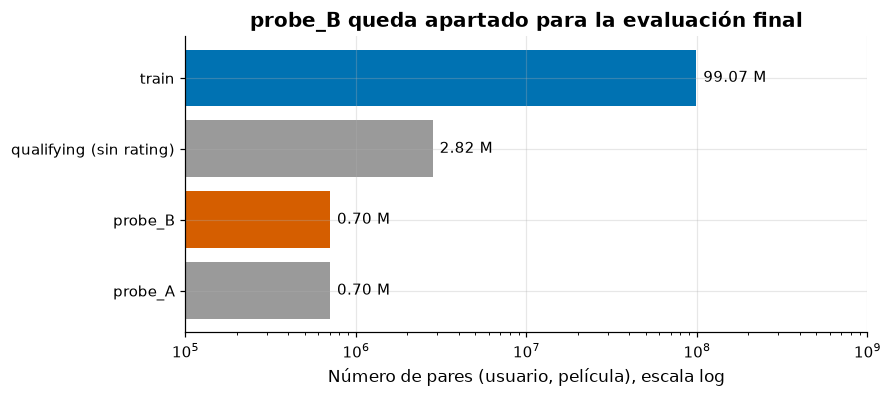

In [ ]:
conjuntos = pd.Series({
    "train": len(train),
    "probe_A": len(probe_A),
    "probe_B": len(probe_B),
    "qualifying (sin rating)": len(qualifying),
}).sort_values()

colores = [COLOR_SECUNDARIO] * len(conjuntos)
colores[list(conjuntos.index).index("train")] = COLOR_PRINCIPAL
colores[list(conjuntos.index).index("probe_B")] = COLOR_RESALTE

fig, ax = plt.subplots(figsize=(8, 3.5))
barras = ax.barh(conjuntos.index, conjuntos.values, color=colores)
for barra, valor in zip(barras, conjuntos.values):
    ax.text(barra.get_width() * 1.1, barra.get_y() + barra.get_height() / 2,
            f"{valor / 1e6:.2f} M", va="center")
ax.set_xscale("log")
ax.set_xlim(1e5, 1e9)
ax.set_xlabel("Número de pares (usuario, película), escala log")
ax.set_title("probe_B queda apartado para la evaluación final")
guardar_figura(fig, "01_tamano_conjuntos")
plt.show()

La gráfica usa escala logarítmica, ya que train es unas 140 veces más grande que cada mitad de probe. probe_B aparece resaltado porque es el conjunto que queda guardado hasta la Etapa 7. qualifying, con 2.82 millones de pares, es el doble de probe y solo aporta información implícita.

In [ ]:
peliculas = titulos.copy()
peliculas["movie_idx"] = mapa_peliculas[peliculas["movie_id"].to_numpy()].astype(np.int16)
usuarios = pd.DataFrame({"user_idx": np.arange(len(user_ids), dtype=np.int32),
                         "user_id": user_ids})

archivos = {
    "train": train,
    "probe_A": probe_A,
    "probe_B": probe_B,
    "qualifying": qualifying,
    "peliculas": peliculas,
    "usuarios": usuarios,
}
for nombre, tabla in archivos.items():
    ruta = ARTEFACTOS / f"{nombre}.parquet"
    tabla.to_parquet(ruta, index=False)
    print(f"{nombre + '.parquet':<20} {len(tabla):>12,} filas {ruta.stat().st_size / 1024**2:>8.1f} MB")

train.parquet          99,072,112 filas    521.4 MB
probe_A.parquet           704,197 filas      5.5 MB


probe_B.parquet           704,198 filas      5.5 MB


qualifying.parquet      2,817,131 filas     15.6 MB
peliculas.parquet          17,770 filas      0.5 MB
usuarios.parquet          480,189 filas      4.8 MB


Guardamos seis archivos Parquet en `artifacts/`. train, con 99 millones de filas, ocupa 521 MB en disco, contra los casi 2 GB de los archivos de texto originales. Parquet comprime cada columna y conserva los tipos, así que al leerlo no hay que volver a convertir nada.

In [ ]:
train_leido = pd.read_parquet(ARTEFACTOS / "train.parquet")
print(train_leido.dtypes)
print(f"Filas iguales a las guardadas: {train_leido.equals(train)}")
del train_leido

rating        int8
dia          int16
user_idx     int32
movie_idx    int16
dtype: object
Filas iguales a las guardadas: True


Volvimos a leer `train.parquet` y es idéntico a la tabla en memoria, con los mismos tipos compactos. De aquí en adelante cada notebook empieza leyendo estos archivos y no vuelve a tocar los `.txt`.

### Resumen de la Etapa 1

- **Validación.** Los conteos coinciden con los oficiales, 100,480,507 ratings, 480,189 usuarios, 17,770 películas, 1,408,395 pares de probe y 2,817,131 de qualifying. Las fechas van del 11 de noviembre de 1999 al 31 de diciembre de 2005.
- **Conjuntos.** train tiene 99,072,112 ratings, sin ningún par de probe. probe se dividió al azar por pares con semilla 42 en probe_A (704,197) y probe_B (704,198), con cobertura casi igual de usuarios y películas.
- **Formato.** Los IDs quedaron como índices consecutivos (`user_idx` de 0 a 480,188 y `movie_idx` de 0 a 17,769). La tabla de ratings ocupa 862 MB en memoria y 521 MB en disco.
- **Títulos.** 336 títulos tienen comas y 7 películas no tienen año. Se leyeron línea por línea para no partirlos.
- **Costo.** La lectura de los textos tomó unos 8 minutos. Esto ya no se repite, pues las siguientes etapas leen los Parquet.

**Siguiente etapa.** Etapa 2, análisis exploratorio con las gráficas de distribución de ratings, cola larga de usuarios y películas, esparsidad, efecto del tiempo y del año de estreno.

## Etapa 2. Análisis exploratorio

Antes de entrenar modelos queremos entender cómo son los datos, pues cada patrón que encontremos aquí se convierte en una pieza de algún modelo. Por ejemplo, si los ratings cambian con el tiempo, el modelo necesita un término temporal, y si hay usuarios con muy pocos ratings, necesita regularización para no creerle demasiado a dos o tres datos.

Todo el análisis usa solo **train** (99 millones de ratings). probe_A y probe_B no se tocan, así ninguna decisión de modelado queda influida por los datos con los que vamos a evaluar.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.carga import FECHA_ORIGEN
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL,
                                 COLOR_SECUNDARIO, COLOR_RESALTE)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
aplicar_estilo()

train = pd.read_parquet(ARTEFACTOS / "train.parquet")
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx")

N_USUARIOS = 480_189
N_PELICULAS = 17_770
print(f"train: {len(train):,} ratings")

train: 99,072,112 ratings


Leemos train y la tabla de películas desde los Parquet de la Etapa 1, lo cual toma unos segundos en vez de los 8 minutos que costó leer los textos.

In [ ]:
def conteos_por_rating(grupo, ratings, n_grupos):
    """Cuenta cuántos ratings de cada valor (1 a 5) tiene cada grupo.

    Devuelve una matriz de n_grupos x 5. La columna 0 son los ratings de 1
    estrella, la columna 4 los de 5 estrellas.
    """
    conteos = np.zeros((n_grupos, 5), dtype=np.int64)
    for estrellas in range(1, 6):
        conteos[:, estrellas - 1] = np.bincount(grupo[ratings == estrellas],
                                                minlength=n_grupos)
    return conteos


def resumen_desde_conteos(conteos):
    """Calcula número de ratings, promedio y desviación estándar por grupo."""
    estrellas = np.arange(1, 6)
    n = conteos.sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        promedio = (conteos @ estrellas) / n
        promedio_cuadrados = (conteos @ estrellas**2) / n
    desviacion = np.sqrt(promedio_cuadrados - promedio**2)
    return pd.DataFrame({"n": n, "promedio": promedio, "desviacion": desviacion})


ratings = train["rating"].to_numpy()
por_usuario = resumen_desde_conteos(conteos_por_rating(train["user_idx"].to_numpy(), ratings, N_USUARIOS))
por_pelicula = resumen_desde_conteos(conteos_por_rating(train["movie_idx"].to_numpy(), ratings, N_PELICULAS))
n_dias = int(train["dia"].max()) + 1
por_dia = resumen_desde_conteos(conteos_por_rating(train["dia"].to_numpy(), ratings, n_dias))
por_dia["fecha"] = FECHA_ORIGEN + pd.to_timedelta(np.arange(n_dias), unit="D")
print(f"Usuarios con al menos un rating en train: {(por_usuario['n'] > 0).sum():,}")
print(f"Películas con al menos un rating en train: {(por_pelicula['n'] > 0).sum():,}")

Usuarios con al menos un rating en train: 480,189
Películas con al menos un rating en train: 17,770


Para sacar promedios por usuario, por película o por día no usamos `groupby` sobre los 99 millones de filas, ya que es lento con tantas filas. En cambio contamos cuántos ratings de cada valor (1, 2, 3, 4 y 5 estrellas) tiene cada grupo con `np.bincount`, que es muy rápido. Con esos cinco conteos se calcula el número de ratings, el promedio y la desviación estándar de cada grupo.

Por ejemplo, si una película tiene 2 ratings de 3 estrellas y 1 de 5, su promedio es (2·3 + 1·5) / 3 = 3.67.

Todos los usuarios y las 17,770 películas tienen al menos un rating en train, así que nadie quedó vacío al quitar probe.

### 1. ¿Cómo califican los usuarios?

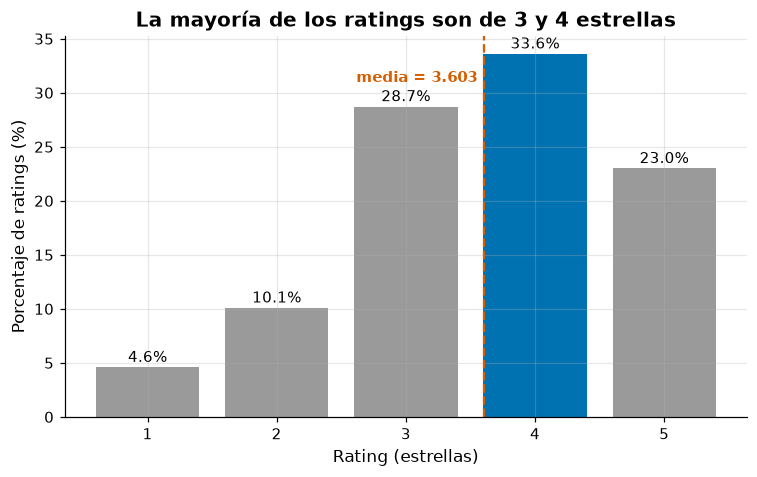

Media global: 3.6033
Desviación estándar global: 1.0846
Ratings >= 4 ('le gusta'): 56.6%


In [ ]:
distribucion = pd.Series(np.bincount(ratings, minlength=6)[1:], index=range(1, 6))
porcentaje = 100 * distribucion / distribucion.sum()
media_global = (distribucion * distribucion.index).sum() / distribucion.sum()

colores = [COLOR_SECUNDARIO] * 5
colores[porcentaje.idxmax() - 1] = COLOR_PRINCIPAL

fig, ax = plt.subplots()
barras = ax.bar(porcentaje.index, porcentaje.values, color=colores)
for barra, valor in zip(barras, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.5, f"{valor:.1f}%", ha="center")
ax.axvline(media_global, color=COLOR_RESALTE, linestyle="--")
ax.text(media_global - 0.05, 31, f"media = {media_global:.3f}",
        color=COLOR_RESALTE, fontweight="bold", ha="right")
ax.set_xlabel("Rating (estrellas)")
ax.set_ylabel("Porcentaje de ratings (%)")
ax.set_title("La mayoría de los ratings son de 3 y 4 estrellas")
guardar_figura(fig, "02_distribucion_ratings")
plt.show()

print(f"Media global: {media_global:.4f}")
print(f"Desviación estándar global: {np.sqrt((distribucion * (distribucion.index - media_global)**2).sum() / distribucion.sum()):.4f}")
print(f"Ratings >= 4 ('le gusta'): {porcentaje[[4, 5]].sum():.1f}%")

Los ratings de 3 y 4 estrellas suman el 62.3% del total, y el 4 es el más común con 33.6%. Los ratings bajos son raros, pues solo el 4.6% son de 1 estrella. La media global es 3.603 y la desviación estándar 1.085.

Esa desviación ya es una primera referencia. Un modelo que siempre prediga 3.603 tiene en train un RMSE igual a esa desviación, 1.085, y Cinematch logra 0.9474 en probe. En la Etapa 3 veremos cuánto da ese modelo trivial en probe_A, que puede ser distinto porque probe tiene otra mezcla de fechas y usuarios.

**Decisiones.** La media global es el punto de partida de todos los modelos de la Etapa 3, que la usan como base y le suman sesgos. Para la Etapa 4, la etiqueta "le gusta" (rating ≥ 4) cubre el 56.6% de los ratings, así que las dos clases quedan bastante balanceadas y no hace falta corregir el desbalance.

### 2. ¿Cuántos ratings tiene cada usuario y cada película?

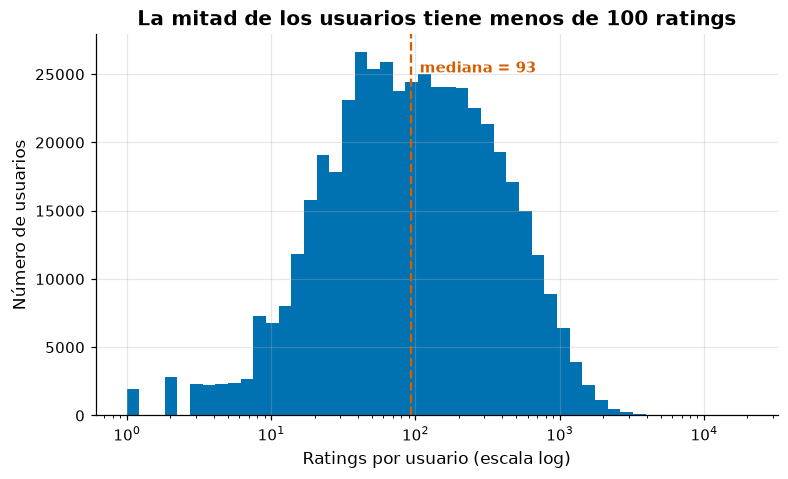

In [ ]:
def histograma_log(conteos, ax, color, etiqueta):
    """Histograma con bins en escala logarítmica y la mediana marcada."""
    bins = np.logspace(0, np.log10(conteos.max()) + 0.05, 50)
    ax.hist(conteos, bins=bins, color=color)
    mediana = np.median(conteos)
    ax.axvline(mediana, color=COLOR_RESALTE, linestyle="--")
    ax.text(mediana * 1.15, ax.get_ylim()[1] * 0.9, f"mediana = {mediana:,.0f}",
            color=COLOR_RESALTE, fontweight="bold")
    ax.set_xscale("log")
    ax.set_xlabel(f"Ratings por {etiqueta} (escala log)")


ratings_por_usuario = por_usuario["n"].to_numpy()
fig, ax = plt.subplots()
histograma_log(ratings_por_usuario, ax, COLOR_PRINCIPAL, "usuario")
ax.set_ylabel("Número de usuarios")
ax.set_title("La mitad de los usuarios tiene menos de 100 ratings")
guardar_figura(fig, "02_ratings_por_usuario")
plt.show()

In [ ]:
def resumen_cola(conteos, nombre):
    """Imprime cuántos ratings aporta el 10% más activo y cuántos tienen muy pocos."""
    ordenados = np.sort(conteos)[::-1]
    top_10 = ordenados[: len(ordenados) // 10].sum() / ordenados.sum()
    print(f"{nombre}: mínimo {conteos.min():,}, mediana {np.median(conteos):,.0f}, "
          f"media {conteos.mean():,.0f}, máximo {conteos.max():,}")
    print(f"  el 10% con más ratings aporta el {100 * top_10:.1f}% de todos los ratings")
    for limite in [10, 50, 100]:
        print(f"  con menos de {limite} ratings: {100 * (conteos < limite).mean():.1f}%")


resumen_cola(ratings_por_usuario, "Usuarios")

Usuarios: mínimo 1, mediana 93, media 206, máximo 17,651
  el 10% con más ratings aporta el 44.0% de todos los ratings
  con menos de 10 ratings: 5.0%
  con menos de 50 ratings: 33.5%
  con menos de 100 ratings: 51.6%


El histograma usa escala logarítmica en el eje x, por eso cada tramo cubre un rango proporcional (de 10 a 20, de 100 a 200, etc.). La mediana es de 93 ratings por usuario, pero la media es 206, porque unos pocos usuarios califican muchísimo. El más activo tiene 17,651 ratings, o sea que calificó casi todo el catálogo de 17,770 películas.

El 10% de usuarios más activos aporta el 44.0% de todos los ratings. En el otro extremo, el 33.5% de los usuarios tiene menos de 50 ratings y el 5.0% menos de 10.

**Decisión.** Un sesgo o un vector de factores estimado con 5 ratings es muy poco confiable. Por eso todos los modelos de las Etapas 3 y 5 llevan regularización, que en la práctica "jala" hacia cero el sesgo de los usuarios con pocos datos y deja libre el de los usuarios con muchos.

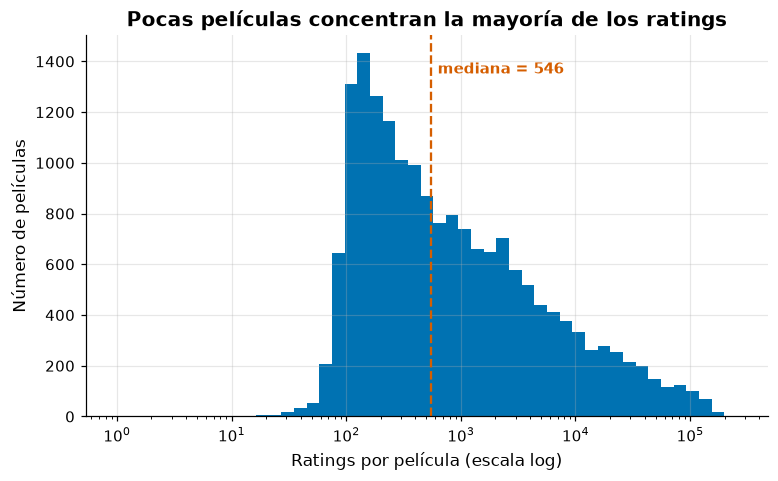

Películas: mínimo 3, mediana 546, media 5,575, máximo 227,715
  el 10% con más ratings aporta el 76.7% de todos los ratings
  con menos de 10 ratings: 0.0%
  con menos de 50 ratings: 0.5%
  con menos de 100 ratings: 6.2%


In [ ]:
ratings_por_pelicula = por_pelicula["n"].to_numpy()
fig, ax = plt.subplots()
histograma_log(ratings_por_pelicula, ax, COLOR_PRINCIPAL, "película")
ax.set_ylabel("Número de películas")
ax.set_title("Pocas películas concentran la mayoría de los ratings")
guardar_figura(fig, "02_ratings_por_pelicula")
plt.show()

resumen_cola(ratings_por_pelicula, "Películas")

Con las películas la concentración es mucho más fuerte. La mediana es de 546 ratings, pero la media es 5,575, y la más vista tiene 227,715. El 10% de películas más populares concentra el 76.7% de los ratings.

En cambio, casi ninguna película tiene menos de 50 ratings (0.5%), y el 6.2% tiene menos de 100. Es decir, en Netflix Prize el problema de los datos escasos está sobre todo en los usuarios, no tanto en las películas.

**Decisión.** Para el kNN ítem-ítem de la Etapa 5, la similitud entre dos películas de nicho se calcula con muy pocos usuarios en común, así que la ajustaremos con shrinkage (encoger la similitud hacia cero cuando hay pocos datos). Para la Etapa 4, el contenido (título y año) es candidato a ayudar en esas películas con pocos ratings, aunque son relativamente pocas.

### 3. ¿Qué tan vacía está la matriz usuario × película?

In [ ]:
celdas_totales = N_USUARIOS * N_PELICULAS
densidad = len(train) / celdas_totales
print(f"Celdas de la matriz usuario x película: {celdas_totales:,}")
print(f"Celdas con rating: {len(train):,}")
print(f"Densidad: {100 * densidad:.2f}%  (vacías: {100 * (1 - densidad):.2f}%)")
print(f"Memoria si la guardáramos densa en float32: {celdas_totales * 4 / 1024**3:.1f} GB")

Celdas de la matriz usuario x película: 8,532,958,530
Celdas con rating: 99,072,112
Densidad: 1.16%  (vacías: 98.84%)
Memoria si la guardáramos densa en float32: 31.8 GB


La matriz completa tendría 8,532 millones de celdas (480,189 usuarios por 17,770 películas) y solo 99 millones tienen rating. Eso es una densidad de 1.16%, o sea, el 98.84% de la matriz está vacía. Guardarla como matriz densa costaría 31.8 GB, por eso todo el proyecto trabaja con estructuras dispersas.

Celdas llenas en la muestra: 916 de 90,000 (1.02%)


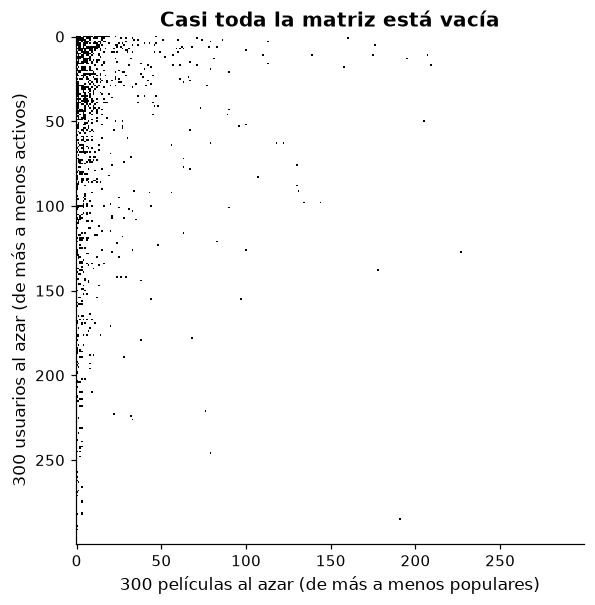

In [ ]:
rng = np.random.default_rng(SEMILLA)
usuarios_muestra = rng.choice(N_USUARIOS, 300, replace=False)
peliculas_muestra = rng.choice(N_PELICULAS, 300, replace=False)

# Ordenamos para que los más activos y las más populares queden arriba y a la izquierda
usuarios_muestra = usuarios_muestra[np.argsort(-ratings_por_usuario[usuarios_muestra])]
peliculas_muestra = peliculas_muestra[np.argsort(-ratings_por_pelicula[peliculas_muestra])]

fila_de_usuario = np.full(N_USUARIOS, -1)
fila_de_usuario[usuarios_muestra] = np.arange(300)
columna_de_pelicula = np.full(N_PELICULAS, -1)
columna_de_pelicula[peliculas_muestra] = np.arange(300)

filas = fila_de_usuario[train["user_idx"].to_numpy()]
columnas = columna_de_pelicula[train["movie_idx"].to_numpy()]
en_muestra = (filas >= 0) & (columnas >= 0)

matriz = np.full((300, 300), np.nan)
matriz[filas[en_muestra], columnas[en_muestra]] = ratings[en_muestra]
print(f"Celdas llenas en la muestra: {en_muestra.sum()} de 90,000 ({100 * en_muestra.sum() / 90_000:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(~np.isnan(matriz), cmap="Greys", interpolation="nearest")
ax.set_xlabel("300 películas al azar (de más a menos populares)")
ax.set_ylabel("300 usuarios al azar (de más a menos activos)")
ax.set_title("Casi toda la matriz está vacía")
ax.grid(False)
guardar_figura(fig, "02_esparsidad")
plt.show()

Cada punto negro es un rating en una muestra de 300 usuarios y 300 películas tomados al azar con semilla 42. Solo 916 de las 90,000 celdas están llenas (1.02%), muy parecido a la densidad total. Como ordenamos por actividad y popularidad, los puntos se juntan arriba a la izquierda, donde se cruzan los usuarios activos con las películas populares. La mayor parte de la imagen está en blanco.

**Decisión.** Los modelos se entrenan solo con las celdas observadas, guardadas en formato disperso. No rellenamos los vacíos con ceros, ya que un vacío no significa "no me gustó", sino "no la calificó". Un SVD clásico de álgebra lineal necesita la matriz completa, por eso usaremos factorización con SGD o ALS sobre los ratings conocidos.

### 4. ¿Cambian los ratings con el tiempo?

In [ ]:
por_dia["mes"] = por_dia["fecha"].dt.to_period("M")
por_dia["suma"] = por_dia["n"] * por_dia["promedio"].fillna(0)
por_mes = por_dia.groupby("mes").agg(n=("n", "sum"), suma=("suma", "sum"))
por_mes["promedio"] = por_mes["suma"] / por_mes["n"]

# Los meses con muy pocos ratings dan promedios ruidosos
MIN_RATINGS_MES = 10_000
por_mes_confiable = por_mes[por_mes["n"] >= MIN_RATINGS_MES].copy()


def salto_con_ventana(tabla, meses=3):
    """Promedio de los `meses` siguientes menos el de los `meses` anteriores.

    Comparar ventanas de varios meses evita que un solo mes ruidoso parezca un salto.
    """
    saltos = {}
    for i in range(meses, len(tabla) - meses + 1):
        antes = tabla.iloc[i - meses:i]
        despues = tabla.iloc[i:i + meses]
        saltos[tabla.index[i]] = (despues["suma"].sum() / despues["n"].sum()
                                  - antes["suma"].sum() / antes["n"].sum())
    return pd.Series(saltos)


por_mes_confiable["cambio_mes"] = por_mes_confiable["promedio"].diff()
por_mes_confiable["salto_3_meses"] = salto_con_ventana(por_mes_confiable)
mes_salto = por_mes_confiable["salto_3_meses"].idxmax()

print(f"Meses con al menos {MIN_RATINGS_MES:,} ratings: {len(por_mes_confiable)} de {len(por_mes)}")
print(f"Mayor subida mes contra mes: {por_mes_confiable['cambio_mes'].idxmax()} "
      f"(+{por_mes_confiable['cambio_mes'].max():.3f})")
print(f"Mayor salto con ventana de 3 meses: {mes_salto} "
      f"(+{por_mes_confiable.loc[mes_salto, 'salto_3_meses']:.3f})")
por_mes_confiable.loc[mes_salto - 3: mes_salto + 3, ["n", "promedio", "cambio_mes", "salto_3_meses"]]

Meses con al menos 10,000 ratings: 72 de 74
Mayor subida mes contra mes: 2001-03 (+0.104)
Mayor salto con ventana de 3 meses: 2004-03 (+0.137)


,n,promedio,cambio_mes,salto_3_meses
mes,,,,
2003-12,1293800,3.422331,0.002743,0.002179
2004-01,1951244,3.407800,-0.014531,0.035326
2004-02,1814823,3.434801,0.027001,0.103266
2004-03,2126444,3.528925,0.094124,0.136580
2004-04,2221180,3.576621,0.047696,0.115094
2004-05,2285404,3.566317,-0.010305,0.063734
2004-06,2533333,3.581193,0.014877,0.045003


Agrupamos los ratings por mes y descartamos los 2 meses con menos de 10 mil ratings (los primeros del dataset), porque su promedio depende de muy pocos datos.

Para encontrar el salto probamos dos métodos. Comparar cada mes con el anterior señala marzo de 2001 (+0.104), pero eso es ruido de una época con apenas 130 mil ratings por mes. Al comparar los 3 meses siguientes contra los 3 anteriores, el salto más grande es marzo de 2004 (+0.137). La tabla muestra cómo el promedio pasa de 3.43 en febrero a 3.53 en marzo y 3.58 en abril de 2004, y ya no regresa.

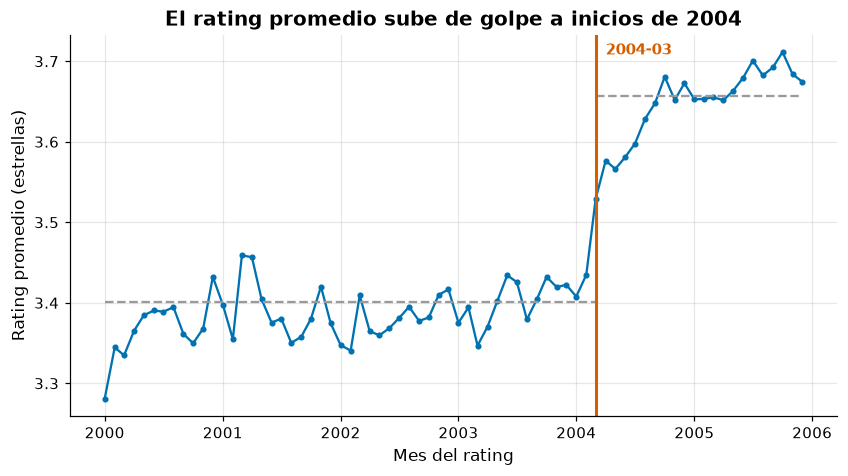

Promedio ponderado antes de 2004-03: 3.401
Promedio ponderado desde 2004-03: 3.657
Diferencia: +0.256


In [ ]:
fechas = por_mes_confiable.index.to_timestamp()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(fechas, por_mes_confiable["promedio"], color=COLOR_PRINCIPAL, marker="o", markersize=3)

antes = por_mes_confiable[por_mes_confiable.index < mes_salto]["promedio"]
despues = por_mes_confiable[por_mes_confiable.index >= mes_salto]["promedio"]
n_antes = por_mes_confiable[por_mes_confiable.index < mes_salto]["n"]
n_despues = por_mes_confiable[por_mes_confiable.index >= mes_salto]["n"]
media_antes = np.average(antes, weights=n_antes)
media_despues = np.average(despues, weights=n_despues)

ax.hlines(media_antes, fechas[0], mes_salto.to_timestamp(), color=COLOR_SECUNDARIO, linestyle="--")
ax.hlines(media_despues, mes_salto.to_timestamp(), fechas[-1], color=COLOR_SECUNDARIO, linestyle="--")
ax.axvline(mes_salto.to_timestamp(), color=COLOR_RESALTE, linewidth=2)
ax.text(mes_salto.to_timestamp(), ax.get_ylim()[1] - 0.01, f"  {mes_salto}",
        color=COLOR_RESALTE, fontweight="bold", va="top")
ax.set_xlabel("Mes del rating")
ax.set_ylabel("Rating promedio (estrellas)")
ax.set_title("El rating promedio sube de golpe a inicios de 2004")
guardar_figura(fig, "02_promedio_por_mes")
plt.show()

print(f"Promedio ponderado antes de {mes_salto}: {media_antes:.3f}")
print(f"Promedio ponderado desde {mes_salto}: {media_despues:.3f}")
print(f"Diferencia: {media_despues - media_antes:+.3f}")

La gráfica muestra dos épocas. Hasta febrero de 2004 el promedio se mueve alrededor de 3.40, y a partir de marzo de 2004 sube a 3.66, una diferencia de 0.256 estrellas. Ese salto pesa mucho, pues desde 2004 se concentra la mayor parte de los ratings (desde marzo de 2004 hay más de 2 millones por mes, contra 100 a 160 mil en 2001).

Los datos no dicen la causa. Una explicación que se ha propuesto es un cambio en el propio sistema de Netflix, por ejemplo en el texto que describía cada estrella o en la calidad de las recomendaciones, más que un cambio en los gustos de la gente.

**Decisión.** Un modelo que ignore la fecha se equivoca de forma sistemática, ya que predice casi lo mismo para un rating de 2002 que para uno de 2005. Por eso en la Etapa 3 agregamos sesgos temporales (sesgo de película por periodo y deriva del sesgo de usuario) y en la Etapa 5 probaremos timeSVD++.

In [ ]:
peliculas_con_anio = peliculas.assign(n=por_pelicula["n"].to_numpy(),
                                      promedio=por_pelicula["promedio"].to_numpy())
peliculas_con_anio = peliculas_con_anio.dropna(subset=["anio"])
peliculas_con_anio["suma"] = peliculas_con_anio["n"] * peliculas_con_anio["promedio"]

por_anio = peliculas_con_anio.groupby("anio").agg(
    peliculas=("movie_idx", "count"), n=("n", "sum"), suma=("suma", "sum"))
por_anio["promedio"] = por_anio["suma"] / por_anio["n"]

# Solo años con suficientes películas para que el promedio no dependa de una sola
MIN_PELICULAS_ANIO = 20
por_anio_confiable = por_anio[por_anio["peliculas"] >= MIN_PELICULAS_ANIO]
print(f"Años de estreno de {int(por_anio.index.min())} a {int(por_anio.index.max())}")
print(f"Años con al menos {MIN_PELICULAS_ANIO} películas: {len(por_anio_confiable)}")

Años de estreno de 1896 a 2005
Años con al menos 20 películas: 72


Los años de estreno van de 1896 a 2005. Para la gráfica solo usamos los 72 años que tienen al menos 20 películas, ya que el promedio de un año con 2 o 3 películas depende de esas pocas películas.

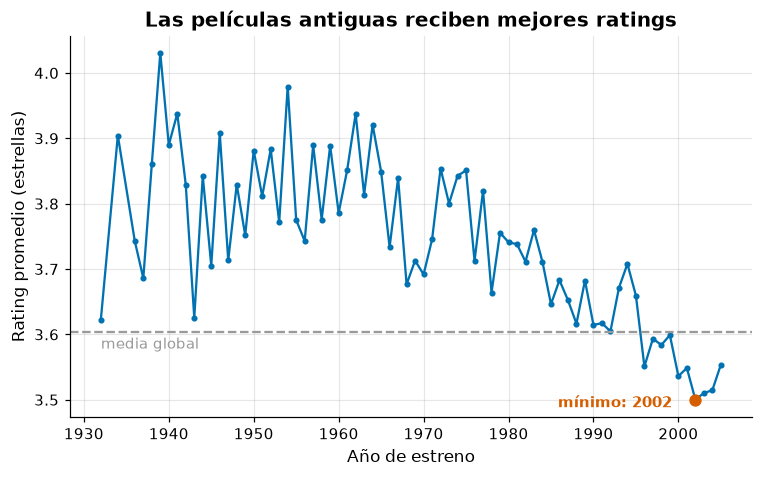

Década 1940: promedio 3.841
Década 1960: promedio 3.814
Década 1980: promedio 3.683
Década 1990: promedio 3.616
Década 2000: promedio 3.521


In [ ]:
anio_bajo = por_anio_confiable["promedio"].idxmin()

fig, ax = plt.subplots()
ax.plot(por_anio_confiable.index, por_anio_confiable["promedio"], color=COLOR_PRINCIPAL,
        marker="o", markersize=3)
ax.scatter([anio_bajo], [por_anio_confiable.loc[anio_bajo, "promedio"]], color=COLOR_RESALTE, zorder=3, s=50)
ax.annotate(f"mínimo: {anio_bajo}", (anio_bajo, por_anio_confiable.loc[anio_bajo, "promedio"]),
            xytext=(-90, -5), textcoords="offset points", color=COLOR_RESALTE, fontweight="bold")
ax.axhline(media_global, color=COLOR_SECUNDARIO, linestyle="--")
ax.text(por_anio_confiable.index.min(), media_global - 0.025, "media global", color=COLOR_SECUNDARIO)
ax.set_xlabel("Año de estreno")
ax.set_ylabel("Rating promedio (estrellas)")
ax.set_title("Las películas antiguas reciben mejores ratings")
guardar_figura(fig, "02_promedio_por_anio_estreno")
plt.show()

for decada in [1940, 1960, 1980, 1990, 2000]:
    filas_decada = por_anio_confiable[(por_anio_confiable.index >= decada) & (por_anio_confiable.index < decada + 10)]
    if len(filas_decada):
        print(f"Década {decada}: promedio {np.average(filas_decada['promedio'], weights=filas_decada['n']):.3f}")

Las películas antiguas tienen mejores promedios. Las de los años 40 promedian 3.84 y las de los 60 3.81, mientras que las de los 90 bajan a 3.62 y las de los 2000 a 3.52. El mínimo está en las estrenadas en 2002.

Una explicación probable es la selección. De los años 40 solo siguen disponibles (y solo se ven) las películas que la gente considera clásicas, en cambio de los estrenos recientes se ve de todo, lo bueno y lo malo.

**Decisión.** El año de estreno sí lleva información, por eso entra como variable de contenido en la Etapa 4 y como metavariable del blender en la Etapa 6. Las 7 películas sin año quedan fuera de esta gráfica.

In [ ]:
anio_del_dia = por_dia["fecha"].dt.year.to_numpy()
anio_estreno = peliculas["anio"].fillna(-1).to_numpy().astype(np.int16)

anio_rating = anio_del_dia[train["dia"].to_numpy()].astype(np.int16)
estreno = anio_estreno[train["movie_idx"].to_numpy()]
tiene_anio = estreno >= 0
edad = anio_rating[tiene_anio] - estreno[tiene_anio]
del anio_rating, estreno

MIN_EDAD = int(edad.min())
conteos_edad = conteos_por_rating(edad - MIN_EDAD, ratings[tiene_anio],
                                  int(edad.max()) - MIN_EDAD + 1)
por_edad = resumen_desde_conteos(conteos_edad)
por_edad.index = np.arange(MIN_EDAD, MIN_EDAD + len(por_edad))
# Las edades con menos de 100 mil ratings quedan como hueco en la línea
por_edad_confiable = por_edad.where(por_edad["n"] >= 100_000)
del edad
print(f"Edad de la película al calificarla: de {MIN_EDAD} a {por_edad.index.max()} años")
print(f"Edades con al menos 100 mil ratings: {por_edad_confiable['n'].notna().sum()}, de 0 a {por_edad_confiable['n'].last_valid_index()}")

Edad de la película al calificarla: de -4 a 109 años
Edades con al menos 100 mil ratings: 60, de 0 a 66


La edad de la película al momento del rating es el año del rating menos el año de estreno. Hay algunas edades negativas (hasta -4), que son ratings anteriores al año de estreno registrado, probablemente errores o diferencias en el año registrado en el catálogo. Para la gráfica usamos las 60 edades con al menos 100 mil ratings.

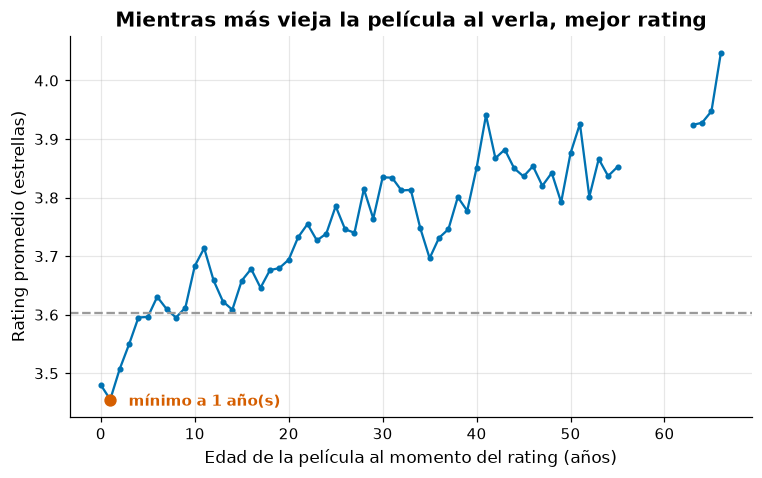

             n  promedio
0    4855943.0     3.480
1   15601238.0     3.455
5    5310243.0     3.596
10   2996284.0     3.683
20   1294269.0     3.694
30    426805.0     3.835
40    250797.0     3.851


In [ ]:
fig, ax = plt.subplots()
ax.plot(por_edad_confiable.index, por_edad_confiable["promedio"], color=COLOR_PRINCIPAL,
        marker="o", markersize=3)
edad_minima = por_edad_confiable["promedio"].idxmin()
ax.scatter([edad_minima], [por_edad_confiable.loc[edad_minima, "promedio"]], color=COLOR_RESALTE, zorder=3, s=50)
ax.annotate(f"mínimo a {edad_minima} año(s)", (edad_minima, por_edad_confiable.loc[edad_minima, "promedio"]),
            xytext=(12, -4), textcoords="offset points", color=COLOR_RESALTE, fontweight="bold")
ax.axhline(media_global, color=COLOR_SECUNDARIO, linestyle="--")
ax.set_xlabel("Edad de la película al momento del rating (años)")
ax.set_ylabel("Rating promedio (estrellas)")
ax.set_title("Mientras más vieja la película al verla, mejor rating")
guardar_figura(fig, "02_promedio_por_edad")
plt.show()

print(por_edad_confiable.reindex([0, 1, 5, 10, 20, 30, 40])[["n", "promedio"]].dropna().round(3))

El rating promedio crece con la edad de la película al verla. Las películas de 0 a 1 año promedian alrededor de 3.46 a 3.48, a los 10 años 3.68, a los 30 años 3.84 y a los 40 años 3.85. El hueco entre 55 y 63 años aparece porque esas edades tienen menos de 100 mil ratings.

Este efecto se parece al del año de estreno, pero no es idéntico. Una película de 2000 calificada en 2000 tiene edad 0, y calificada en 2005 tiene edad 5, así que la edad mezcla el año de estreno con el momento en que se calificó.

**Decisión.** La edad al momento del rating entra como variable en la Etapa 4 junto con el año de estreno, y probaremos si aporta algo además de él.

### 5. ¿Califican distinto los usuarios activos y los poco activos?

In [ ]:
usuarios = por_usuario[por_usuario["n"] > 0].copy()
usuarios["decil"] = pd.qcut(usuarios["n"].rank(method="first"), 10, labels=range(1, 11))

por_decil = usuarios.groupby("decil", observed=True).agg(
    min_ratings=("n", "min"), max_ratings=("n", "max"),
    promedio_usuarios=("promedio", "mean"),
    dispersion_entre_usuarios=("promedio", "std"),
    desviacion_dentro_usuario=("desviacion", "mean"))
por_decil.round(3)

,min_ratings,max_ratings,promedio_usuarios,dispersion_entre_usuarios,desviacion_dentro_usuario
decil,,,,,
1,1,16,3.689,0.679,0.857
2,16,28,3.710,0.543,0.978
3,28,43,3.700,0.501,1.007
4,43,63,3.680,0.481,1.023
5,63,93,3.688,0.450,1.013
6,93,139,3.694,0.432,0.999
7,139,208,3.695,0.418,0.989
8,208,319,3.684,0.404,0.976
9,319,538,3.655,0.389,0.966


Dividimos a los usuarios en 10 grupos del mismo tamaño (deciles) según cuántos ratings tienen. El decil 1 son usuarios con 1 a 16 ratings y el decil 10 los que tienen de 538 a 17,651.

La tabla muestra tres cosas por decil. El promedio de los ratings de sus usuarios, la dispersión entre usuarios (qué tan distintos son los promedios de unos y otros) y la desviación dentro de cada usuario (qué tanto varía un mismo usuario de una película a otra).

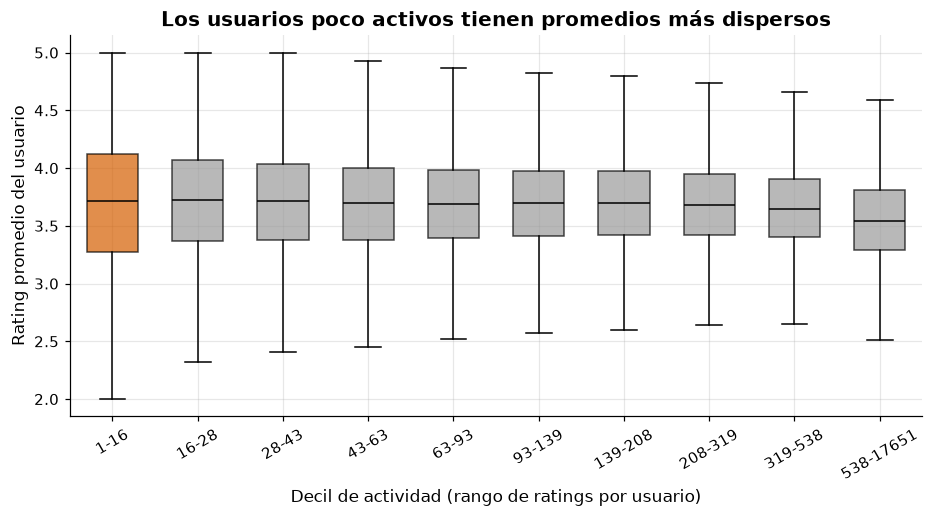

In [ ]:
etiquetas = [f"{fila.min_ratings}-{fila.max_ratings}" for fila in por_decil.itertuples()]
grupos = [usuarios.loc[usuarios["decil"] == d, "promedio"].to_numpy() for d in range(1, 11)]

fig, ax = plt.subplots(figsize=(10, 4.5))
cajas = ax.boxplot(grupos, showfliers=False, patch_artist=True, widths=0.6)
for numero, caja in enumerate(cajas["boxes"]):
    caja.set_facecolor(COLOR_RESALTE if numero == 0 else COLOR_SECUNDARIO)
    caja.set_alpha(0.7)
for mediana in cajas["medians"]:
    mediana.set_color("black")
ax.set_xticks(range(1, 11), etiquetas, rotation=30)
ax.set_xlabel("Decil de actividad (rango de ratings por usuario)")
ax.set_ylabel("Rating promedio del usuario")
ax.set_title("Los usuarios poco activos tienen promedios más dispersos")
guardar_figura(fig, "02_usuarios_por_actividad")
plt.show()

Cada caja muestra el rango donde cae la mitad central de los promedios de usuario de ese decil, y la línea negra es la mediana. El decil 1 (en naranja) tiene la caja más ancha, pues la dispersión entre usuarios es 0.679, contra 0.389 a 0.413 en los deciles 9 y 10. Con solo 1 a 16 ratings, el promedio de un usuario depende mucho de cuáles películas le tocó calificar.

El nivel también cambia. Los deciles 1 a 8 tienen promedios entre 3.68 y 3.71, en cambio el decil 10, el de los usuarios más activos, baja a 3.55. Los usuarios que califican cientos de películas son más exigentes, quizá porque califican también lo que no les gustó.

**Decisiones.** La caja ancha del decil 1 es la razón práctica para regularizar el sesgo de usuario. Además, como el nivel depende de la actividad, el número de ratings del usuario entra como metavariable del blender en la Etapa 6, para que pueda corregir de forma distinta a usuarios nuevos y veteranos.

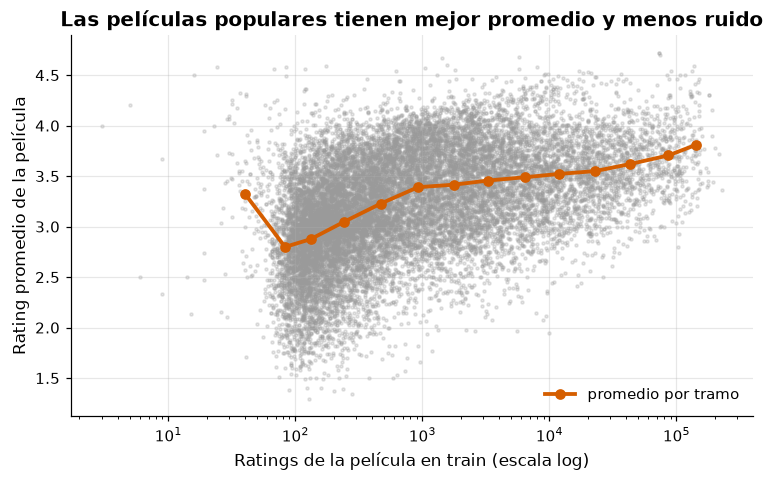

Correlación entre log(número de ratings) y promedio: 0.463
Menos de 100: desv. de promedios 0.550 | 100 o más: 0.514
Menos de 1,000: desv. de promedios 0.514 | 1,000 o más: 0.425
Menos de 10,000: desv. de promedios 0.524 | 10,000 o más: 0.369


In [ ]:
pelis = por_pelicula.copy()
pelis["titulo"] = peliculas["titulo"].to_numpy()

fig, ax = plt.subplots()
ax.scatter(pelis["n"], pelis["promedio"], s=4, alpha=0.25, color=COLOR_SECUNDARIO)

bins = np.logspace(0, np.log10(pelis["n"].max()) + 0.01, 20)
pelis["bin"] = pd.cut(pelis["n"], bins)
tendencia = pelis.groupby("bin", observed=True).agg(n=("n", "median"), promedio=("promedio", "mean"),
                                                    peliculas=("n", "size"))
# Solo tramos con al menos 50 películas, los demás son ruido
tendencia = tendencia[tendencia["peliculas"] >= 50]
ax.plot(tendencia["n"], tendencia["promedio"], color=COLOR_RESALTE, linewidth=2.5, marker="o",
        label="promedio por tramo")
ax.set_xscale("log")
ax.set_xlabel("Ratings de la película en train (escala log)")
ax.set_ylabel("Rating promedio de la película")
ax.set_title("Las películas populares tienen mejor promedio y menos ruido")
ax.legend(loc="lower right")
guardar_figura(fig, "02_popularidad_vs_promedio")
plt.show()

print(f"Correlación entre log(número de ratings) y promedio: "
      f"{np.corrcoef(np.log10(pelis['n']), pelis['promedio'])[0, 1]:.3f}")
for limite in [100, 1_000, 10_000]:
    pocas = pelis[pelis["n"] < limite]["promedio"]
    muchas = pelis[pelis["n"] >= limite]["promedio"]
    print(f"Menos de {limite:,}: desv. de promedios {pocas.std():.3f} | {limite:,} o más: {muchas.std():.3f}")

Cada punto gris es una película y la línea naranja es el promedio de las películas en cada tramo de popularidad (solo tramos con al menos 50 películas). La correlación entre el logaritmo del número de ratings y el promedio es 0.463. Las películas con unos 100 ratings promedian cerca de 2.8, y las que pasan de 100 mil ratings rondan 3.8. Es lógico, pues las películas buenas atraen a más gente.

Además, los promedios de las películas poco vistas están más dispersos. La desviación de los promedios es 0.524 en las películas con menos de 10 mil ratings, contra 0.369 en las que tienen 10 mil o más.

**Decisiones.** El sesgo de película también necesita regularización, para que una película con 100 ratings y promedio de 4.5 no reciba ese 4.5 completo como si fuera seguro. El número de ratings de la película entra como metavariable del blender, igual que el del usuario.

### Resumen de la Etapa 2

| Hallazgo | Número clave | Decisión de modelado |
|---|---|---|
| Los ratings se concentran en 3 y 4 | media 3.603, desviación 1.085 | La media global es la base de todos los modelos. "Le gusta" (≥ 4) está balanceado, con 56.6% |
| Cola larga de usuarios | mediana de 93 ratings, 33.5% con menos de 50 | Regularización del sesgo de usuario y de los factores |
| Concentración en pocas películas | el 10% más popular tiene el 76.7% de los ratings | Shrinkage en el kNN y contenido para películas de nicho |
| Matriz casi vacía | densidad de 1.16% | Entrenar solo con ratings observados, sin rellenar con ceros |
| Salto en marzo de 2004 | de 3.40 a 3.66 (+0.256) | Sesgos temporales en la Etapa 3 y timeSVD++ en la Etapa 5 |
| Películas antiguas mejor calificadas | años 40 con 3.84 contra 3.52 en los 2000 | Año de estreno y edad como variables de contenido y del blender |
| Usuarios poco activos más dispersos | dispersión de 0.679 en el decil 1 contra 0.389 en el 9 | Regularización y número de ratings como metavariable |
| Películas populares mejor calificadas | correlación de 0.463 | Regularizar el sesgo de película y usar su popularidad en el blender |

Ninguno de estos análisis usó probe_A ni probe_B.

**Siguiente etapa.** Etapa 3, baselines. Media global, sesgos de usuario y película, sesgos regularizados y sesgos temporales, comparados contra Cinematch con el RMSE en probe_A.

## Etapa 3. Baselines

Un baseline es el modelo más simple que todavía tiene sentido. Sirve para dos cosas. Primero, marca el piso que cualquier modelo complejo debe superar. Segundo, en el Netflix Prize los sesgos explican buena parte de la variación de los ratings, así que todos los modelos de las etapas siguientes se construyen encima de ellos.

Vamos a sumar una pieza a la vez y medir cuánto baja el RMSE en probe_A con cada una.

- **B0** media global μ.
- **B1** μ + sesgo de usuario b_u (cuánto califica un usuario por arriba o por abajo de la media).
- **B2** μ + sesgo de película b_i.
- **B3** μ + b_i + b_u.
- **B4** lo mismo, pero regularizado.
- **B5** a **B7** sesgos que cambian con el tiempo.

El RMSE (raíz del error cuadrático medio) es la métrica del concurso. Un RMSE de 0.98 quiere decir, a grandes rasgos, que nos equivocamos por casi una estrella en promedio, castigando más los errores grandes.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.carga import FECHA_ORIGEN
from src.metricas import rmse, registrar_experimento
from src.baselines import (SesgosTemporales, suma_por_grupo, periodo_del_dia,
                           calcular_dev, indices_usuario_dia, N_BINS, N_DIAS)
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL,
                                 COLOR_SECUNDARIO, COLOR_RESALTE, COLOR_CINEMATCH,
                                 COLOR_GANADOR, RMSE_CINEMATCH_PROBE, RMSE_GANADOR_TEST)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
(ARTEFACTOS / "predicciones").mkdir(exist_ok=True)
(ARTEFACTOS / "modelos").mkdir(exist_ok=True)
aplicar_estilo()

N_USUARIOS = 480_189
N_PELICULAS = 17_770

Además de las librerías de siempre usamos `src/metricas.py` (cálculo del RMSE y registro en `experimentos.csv`) y `src/baselines.py`, donde está el modelo con sesgos temporales.

In [ ]:
def columnas(tabla):
    """Extrae las columnas de una tabla de ratings como arreglos de numpy."""
    return {
        "usuarios": tabla["user_idx"].to_numpy(),
        "peliculas": tabla["movie_idx"].to_numpy(),
        "ratings": tabla["rating"].to_numpy(),
        "dias": tabla["dia"].to_numpy(),
    }


train = columnas(pd.read_parquet(ARTEFACTOS / "train.parquet"))
probe_A = columnas(pd.read_parquet(ARTEFACTOS / "probe_A.parquet"))
probe_B = columnas(pd.read_parquet(ARTEFACTOS / "probe_B.parquet"))
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx")

N_TRAIN = len(train["ratings"])
mu = train["ratings"].mean()
print(f"train: {N_TRAIN:,} ratings, probe_A: {len(probe_A['ratings']):,}, probe_B: {len(probe_B['ratings']):,}")
print(f"Media global de train (mu): {mu:.4f}")

train: 99,072,112 ratings, probe_A: 704,197, probe_B: 704,198
Media global de train (mu): 3.6033


La media global de train es μ = 3.6033, que será la predicción de B0. Todas las predicciones de esta etapa se recortan al rango de 1 a 5, ya que un rating fuera de ese rango no existe.

In [ ]:
resultados = []          # una fila por modelo final
predicciones_A = {}      # predicciones de cada modelo en probe_A
predicciones_B = {}      # se guardan para la Etapa 7, aquí no se evalúan


def evaluar(nombre, descripcion, pred_A, pred_B, hiperparametros, segundos, notas=""):
    """Mide el RMSE en probe_A, registra la corrida y guarda las predicciones."""
    error = rmse(probe_A["ratings"], pred_A)
    registrar_experimento(nombre, hiperparametros, N_TRAIN, error, segundos, notas)
    predicciones_A[nombre] = np.clip(pred_A, 1, 5).astype(np.float32)
    predicciones_B[nombre] = np.clip(pred_B, 1, 5).astype(np.float32)
    resultados.append({"modelo": nombre, "descripcion": descripcion, "rmse_probe_A": error})
    print(f"{nombre} ({descripcion}): RMSE probe_A = {error:.4f}")

La función `evaluar` concentra el protocolo. Mide el RMSE solo en probe_A, registra la corrida en `experimentos.csv` y guarda las predicciones de probe_A y probe_B. Las de probe_B se guardan pero no se evalúan aquí, quedan para la Etapa 7.

In [ ]:
inicio = time.perf_counter()
pred_A = np.full(len(probe_A["ratings"]), mu)
pred_B = np.full(len(probe_B["ratings"]), mu)
evaluar("B0", "media global", pred_A, pred_B, {}, time.perf_counter() - inicio)

B0 (media global): RMSE probe_A = 1.1294


Predecir siempre 3.6033 da un RMSE de 1.1294 en probe_A. Es más alto que la desviación estándar de train (1.085) porque probe no es una muestra al azar de los ratings. Según el diseño del concurso, probe y qualifying salieron de los ratings más recientes de cada usuario, y en la Etapa 2 vimos que el promedio subió después de 2004. Así que la media de train ya queda corta para probe.

In [ ]:
n_por_usuario = np.bincount(train["usuarios"], minlength=N_USUARIOS)
n_por_pelicula = np.bincount(train["peliculas"], minlength=N_PELICULAS)
desviacion_de_mu = train["ratings"].astype(np.float32) - np.float32(mu)

inicio = time.perf_counter()
b_u_simple = suma_por_grupo(train["usuarios"], desviacion_de_mu, N_USUARIOS) / n_por_usuario
evaluar("B1", "mu + b_u", mu + b_u_simple[probe_A["usuarios"]], mu + b_u_simple[probe_B["usuarios"]],
        {"regularizacion": 0}, time.perf_counter() - inicio)

inicio = time.perf_counter()
b_i_simple = suma_por_grupo(train["peliculas"], desviacion_de_mu, N_PELICULAS) / n_por_pelicula
evaluar("B2", "mu + b_i", mu + b_i_simple[probe_A["peliculas"]], mu + b_i_simple[probe_B["peliculas"]],
        {"regularizacion": 0}, time.perf_counter() - inicio)

B1 (mu + b_u): RMSE probe_A = 1.0685


B2 (mu + b_i): RMSE probe_A = 1.0525


Con solo el sesgo de usuario el RMSE baja a 1.0685, y con solo el de película a 1.0525. Ambos ayudan, y el de película un poco más, pues una película tiene en promedio muchos más ratings que un usuario y su sesgo se estima mejor.

Aquí los sesgos son promedios simples. Por ejemplo, b_u de un usuario es el promedio de (rating - μ) sobre sus ratings, así que si siempre califica 4.6 su sesgo es cerca de +1.

In [ ]:
def sesgos_regularizados(lambda_i, lambda_u):
    """Calcula b_i y después b_u sobre lo que b_i no explica.

    b_i = suma(r - mu) / (lambda_i + n_i)
    b_u = suma(r - mu - b_i) / (lambda_u + n_u)
    Con lambda = 0 son promedios simples.
    """
    b_i = suma_por_grupo(train["peliculas"], desviacion_de_mu, N_PELICULAS) / (lambda_i + n_por_pelicula)
    residuo = desviacion_de_mu - b_i.astype(np.float32)[train["peliculas"]]
    b_u = suma_por_grupo(train["usuarios"], residuo, N_USUARIOS) / (lambda_u + n_por_usuario)
    return b_i, b_u


def predecir_sesgos(b_i, b_u, datos):
    return mu + b_i[datos["peliculas"]] + b_u[datos["usuarios"]]


inicio = time.perf_counter()
b_i_sin_reg, b_u_sin_reg = sesgos_regularizados(0, 0)
evaluar("B3", "mu + b_i + b_u", predecir_sesgos(b_i_sin_reg, b_u_sin_reg, probe_A),
        predecir_sesgos(b_i_sin_reg, b_u_sin_reg, probe_B), {"lambda_i": 0, "lambda_u": 0},
        time.perf_counter() - inicio)

B3 (mu + b_i + b_u): RMSE probe_A = 0.9876


Al juntar los dos sesgos el RMSE cae a 0.9876, la mayor mejora de toda la etapa. Primero se calcula b_i y después b_u sobre lo que b_i no explica, para no contar dos veces el mismo efecto. Ya estamos a 4.2% de Cinematch.

In [ ]:
valores_lambda_i = [0, 5, 10, 25, 50, 100]
valores_lambda_u = [0, 5, 10, 15, 25, 50]

busqueda = []
for lambda_i in valores_lambda_i:
    for lambda_u in valores_lambda_u:
        inicio = time.perf_counter()
        b_i, b_u = sesgos_regularizados(lambda_i, lambda_u)
        error = rmse(probe_A["ratings"], predecir_sesgos(b_i, b_u, probe_A))
        segundos = time.perf_counter() - inicio
        registrar_experimento("B4_busqueda", {"lambda_i": lambda_i, "lambda_u": lambda_u},
                              N_TRAIN, error, segundos, "búsqueda de rejilla")
        busqueda.append({"lambda_i": lambda_i, "lambda_u": lambda_u, "rmse_probe_A": error})

busqueda = pd.DataFrame(busqueda)
mejor = busqueda.loc[busqueda["rmse_probe_A"].idxmin()]
LAMBDA_I, LAMBDA_U = float(mejor["lambda_i"]), float(mejor["lambda_u"])
print(f"Mejor combinación: lambda_i = {LAMBDA_I:g}, lambda_u = {LAMBDA_U:g}, RMSE = {mejor['rmse_probe_A']:.4f}")
busqueda.pivot(index="lambda_i", columns="lambda_u", values="rmse_probe_A").round(4)

Mejor combinación: lambda_i = 10, lambda_u = 5, RMSE = 0.9838


lambda_u,0,5,10,15,25,50
lambda_i,,,,,,
0,0.9876,0.9839,0.9839,0.9848,0.9873,0.9935
5,0.9876,0.9838,0.9839,0.9848,0.9873,0.9934
10,0.9875,0.9838,0.9839,0.9848,0.9873,0.9934
25,0.9876,0.9838,0.9839,0.9848,0.9873,0.9934
50,0.9878,0.9840,0.9840,0.9849,0.9874,0.9935
100,0.9883,0.9845,0.9845,0.9854,0.9879,0.9940


Ahora regularizamos. La idea es encoger el sesgo cuando hay pocos datos, dividiendo entre n + λ en lugar de n. Por ejemplo, un usuario con 2 ratings que promedian +1.5 sobre la media tendría con λ_u = 5 un sesgo de 2·1.5 / (2 + 5) = 0.43, mucho más prudente.

Probamos 36 combinaciones en probe_A. La mejor es λ_i = 10 y λ_u = 5, con RMSE de 0.9838. La tabla muestra que λ_i casi no importa (entre 0 y 25 el RMSE se mueve en el cuarto decimal), ya que casi todas las películas tienen cientos de ratings. En cambio λ_u sí importa, pues pasar de 0 a 5 baja el error de 0.9876 a 0.9838 y pasar a 50 lo sube a 0.9934.

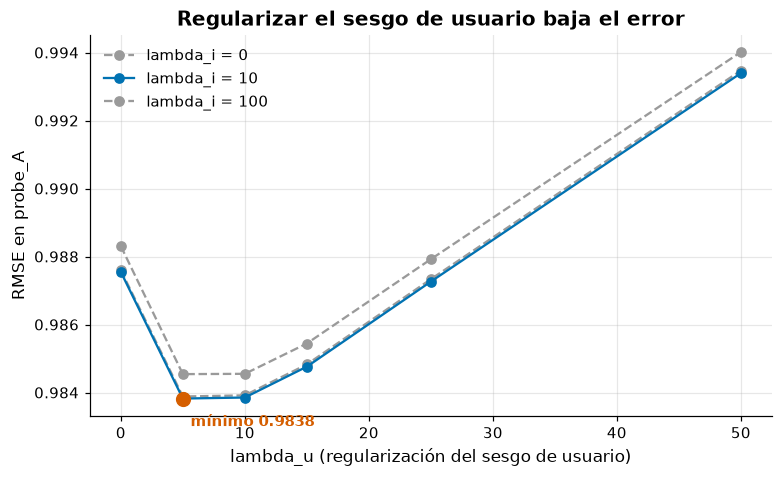

In [ ]:
fig, ax = plt.subplots()
for lambda_i in sorted({0, LAMBDA_I, 100}):
    filas = busqueda[busqueda["lambda_i"] == lambda_i]
    color = COLOR_PRINCIPAL if lambda_i == LAMBDA_I else COLOR_SECUNDARIO
    ax.plot(filas["lambda_u"], filas["rmse_probe_A"], marker="o", color=color,
            linestyle="-" if lambda_i == LAMBDA_I else "--", label=f"lambda_i = {lambda_i:g}")
fila_mejor = busqueda[(busqueda["lambda_i"] == LAMBDA_I)].set_index("lambda_u")["rmse_probe_A"]
ax.scatter([LAMBDA_U], [fila_mejor[LAMBDA_U]], color=COLOR_RESALTE, s=80, zorder=3)
ax.annotate(f"mínimo {fila_mejor[LAMBDA_U]:.4f}", (LAMBDA_U, fila_mejor[LAMBDA_U]),
            xytext=(5, -18), textcoords="offset points", color=COLOR_RESALTE, fontweight="bold")
ax.set_xlabel("lambda_u (regularización del sesgo de usuario)")
ax.set_ylabel("RMSE en probe_A")
ax.set_title("Regularizar el sesgo de usuario baja el error")
ax.legend()
guardar_figura(fig, "03_sensibilidad_lambda")
plt.show()

La gráfica muestra la forma de U típica de la regularización. Sin regularizar (λ_u = 0) el modelo le cree demasiado a los usuarios con pocos ratings, y con λ_u muy grande encoge también a los que tienen muchos datos. El mínimo está en λ_u = 5. Las curvas para λ_i = 0 y λ_i = 10 casi se enciman, mientras que λ_i = 100 ya empieza a estorbar.

In [ ]:
inicio = time.perf_counter()
b_i_reg, b_u_reg = sesgos_regularizados(LAMBDA_I, LAMBDA_U)
evaluar("B4", "sesgos regularizados", predecir_sesgos(b_i_reg, b_u_reg, probe_A),
        predecir_sesgos(b_i_reg, b_u_reg, probe_B), {"lambda_i": LAMBDA_I, "lambda_u": LAMBDA_U},
        time.perf_counter() - inicio)

B4 (sesgos regularizados): RMSE probe_A = 0.9838


B4 con los λ elegidos llega a 0.9838 en probe_A, una mejora de 0.0038 sobre B3. Parece poco, pero en el Netflix Prize las mejoras se pelean en el tercer decimal.

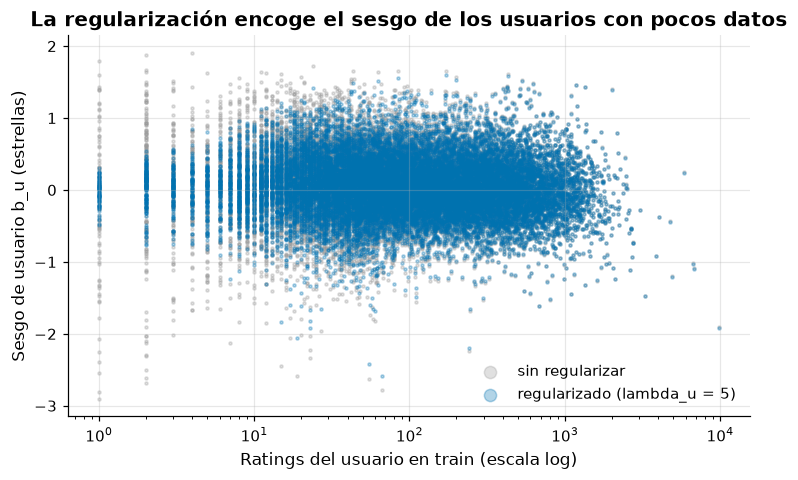

Usuarios con <=    5 ratings: |b_u| promedio sin reg 0.656, con reg 0.220
Usuarios con <=   20 ratings: |b_u| promedio sin reg 0.479, con reg 0.297
Usuarios con <=  100 ratings: |b_u| promedio sin reg 0.401, con reg 0.324
Usuarios con <= 1000 ratings: |b_u| promedio sin reg 0.359, con reg 0.315


In [ ]:
rng = np.random.default_rng(SEMILLA)
muestra = rng.choice(N_USUARIOS, 20_000, replace=False)

fig, ax = plt.subplots()
ax.scatter(n_por_usuario[muestra], b_u_sin_reg[muestra], s=4, alpha=0.3,
           color=COLOR_SECUNDARIO, label="sin regularizar")
ax.scatter(n_por_usuario[muestra], b_u_reg[muestra], s=4, alpha=0.3,
           color=COLOR_PRINCIPAL, label=f"regularizado (lambda_u = {LAMBDA_U:g})")
ax.set_xscale("log")
ax.set_xlabel("Ratings del usuario en train (escala log)")
ax.set_ylabel("Sesgo de usuario b_u (estrellas)")
ax.set_title("La regularización encoge el sesgo de los usuarios con pocos datos")
ax.legend(markerscale=4)
guardar_figura(fig, "03_encogimiento_b_u")
plt.show()

for limite in [5, 20, 100, 1000]:
    grupo = n_por_usuario <= limite
    print(f"Usuarios con <= {limite:>4} ratings: |b_u| promedio sin reg {np.abs(b_u_sin_reg[grupo]).mean():.3f}, "
          f"con reg {np.abs(b_u_reg[grupo]).mean():.3f}")

Cada punto es un usuario (muestra de 20 mil). En gris está su sesgo sin regularizar y en azul el regularizado. A la izquierda, con pocos ratings, los puntos grises llegan hasta ±3 estrellas, en cambio los azules se quedan cerca de cero. A la derecha, con cientos de ratings, gris y azul coinciden.

Los números lo confirman. Para usuarios con 5 ratings o menos, el sesgo promedio en valor absoluto pasa de 0.656 a 0.220. Para los que tienen hasta 1,000 ratings apenas cambia, de 0.359 a 0.315.

In [ ]:
# Periodo de cada rating (30 periodos de unos 75 días)
for datos in (train, probe_A, probe_B):
    datos["periodos"] = periodo_del_dia(datos["dias"])

# Día medio de cada usuario en train y deriva dev_u(t)
dia_medio_usuario = suma_por_grupo(train["usuarios"], train["dias"], N_USUARIOS) / n_por_usuario
for datos in (train, probe_A, probe_B):
    datos["devs"] = calcular_dev(datos["usuarios"], datos["dias"], dia_medio_usuario)

print(f"Días por periodo: {N_DIAS / N_BINS:.1f}")
print(f"dev_u(t) en train: de {train['devs'].min():.1f} a {train['devs'].max():.1f}")

Días por periodo: 74.8
dev_u(t) en train: de -21.1 a 20.9


Para los sesgos temporales preparamos dos variables.

- **Periodo.** Dividimos los 2,243 días del dataset en 30 periodos de 74.8 días. Cada película tendrá un sesgo extra por periodo, b_i,Bin(t).
- **dev_u(t).** Mide qué tan lejos está la fecha del rating del día medio del usuario, con la fórmula signo(t - t_u)·|t - t_u|^0.4 de Koren (2009). El exponente 0.4 hace que crezca rápido al principio y luego despacio. Va de -21.1 a 20.9. El modelo aprende un α_u por usuario, así que α_u·dev_u(t) es una deriva lineal (en esa escala) del sesgo del usuario.

In [ ]:
# Índice de cada par (usuario, día). Se calcula sobre train y probe juntos para que
# un mismo día tenga el mismo índice en los tres conjuntos. Los pares que solo
# aparecen en probe quedan sin datos de train y su sesgo b_u,t se queda en cero.
todos_usuarios = np.concatenate([train["usuarios"], probe_A["usuarios"], probe_B["usuarios"]])
todos_dias = np.concatenate([train["dias"], probe_A["dias"], probe_B["dias"]])
usuario_dia, N_USUARIO_DIA = indices_usuario_dia(todos_usuarios, todos_dias, N_USUARIOS)
del todos_usuarios, todos_dias

fin_A = N_TRAIN + len(probe_A["ratings"])
train["usuario_dia"] = usuario_dia[:N_TRAIN]
probe_A["usuario_dia"] = usuario_dia[N_TRAIN:fin_A]
probe_B["usuario_dia"] = usuario_dia[fin_A:]

dias_con_train = np.zeros(N_USUARIO_DIA, dtype=bool)
dias_con_train[train["usuario_dia"]] = True
print(f"Pares (usuario, día) distintos: {N_USUARIO_DIA:,}")
print(f"Ratings de train por par (usuario, día): {N_TRAIN / dias_con_train.sum():.1f} en promedio")
print(f"probe_A con ratings de train el mismo día: {100 * dias_con_train[probe_A['usuario_dia']].mean():.1f}%")

Pares (usuario, día) distintos: 17,280,041
Ratings de train por par (usuario, día): 6.0 en promedio
probe_A con ratings de train el mismo día: 37.0%


El último sesgo, b_u,t, es uno por cada par (usuario, día). Hay 17,280,041 pares distintos con 6.0 ratings de train en promedio cada uno, lo que confirma que la gente califica en tandas. Lo importante es que el 37.0% de las filas de probe_A tienen ratings de train del mismo usuario el mismo día. Para ese 37% el modelo sabe si ese día el usuario andaba generoso o exigente.

Usar la fecha de probe no es fuga de información, pues la fecha estaba publicada para todos los participantes. Lo que nunca usamos es el rating.

In [ ]:
def ajustar_modelo(grupos, lambdas, n_vueltas=8):
    """Ajusta un modelo de sesgos temporales y devuelve el modelo, su historial y el tiempo."""
    modelo = SesgosTemporales(mu, N_USUARIOS, N_PELICULAS, N_USUARIO_DIA, grupos, lambdas)
    inicio = time.perf_counter()
    historial = modelo.ajustar(train, probe_A, n_vueltas=n_vueltas)
    return modelo, historial, time.perf_counter() - inicio


def buscar(nombre, grupos, lambdas_base, grupo_a_ajustar, valores):
    """Prueba varios valores de lambda para un grupo y se queda con el mejor en probe_A."""
    filas = []
    mejor = None
    for valor in valores:
        lambdas = {**lambdas_base, grupo_a_ajustar: valor}
        modelo, historial, segundos = ajustar_modelo(grupos, lambdas)
        error = historial["rmse_probe_A"].iloc[-1]
        registrar_experimento(f"{nombre}_busqueda", lambdas, N_TRAIN, error, segundos,
                              f"grupos: {', '.join(grupos)}")
        filas.append({grupo_a_ajustar: valor, "rmse_probe_A": error, "segundos": segundos})
        if mejor is None or error < mejor[0]:
            mejor = (error, modelo, historial, lambdas, segundos)
    print(pd.DataFrame(filas).round(4).to_string(index=False))
    return mejor


lambdas = {"b_i": LAMBDA_I, "b_u": LAMBDA_U}
grupos_B5 = ["b_i", "b_u", "b_ibin"]
_, modelo_B5, historial_B5, lambdas_B5, segundos_B5 = buscar("B5", grupos_B5, lambdas, "b_ibin",
                                                            [50, 200, 1_000])
evaluar("B5", "+ sesgo de película por periodo", modelo_B5.predecir(probe_A),
        modelo_B5.predecir(probe_B), lambdas_B5, segundos_B5)

 b_ibin  rmse_probe_A  segundos
     50        0.9793  147.4699
    200        0.9792  145.7049
   1000        0.9794  147.4501


B5 (+ sesgo de película por periodo): RMSE probe_A = 0.9792


Los modelos temporales se ajustan por descenso por coordenadas. Con todos los demás sesgos fijos, el mejor valor de un grupo (por ejemplo, todos los b_i,Bin) tiene fórmula cerrada, que es un promedio regularizado del residuo, igual que en B4. Se recorre cada grupo por turnos durante 8 vueltas. Esto reemplaza al SGD que planeamos al inicio, ya que no necesita tasas de aprendizaje y da el mismo resultado sin importar el orden de los datos.

Agregar el sesgo de película por periodo baja el RMSE a 0.9792 (mejora de 0.0046 sobre B4). El λ_bin casi no importa, pues entre 50 y 1,000 el resultado se mueve en el cuarto decimal. Nos quedamos con 200.

In [ ]:
grupos_B6 = grupos_B5 + ["alpha"]
_, modelo_B6, historial_B6, lambdas_B6, segundos_B6 = buscar("B6", grupos_B6, lambdas_B5, "alpha",
                                                            [1_000, 10_000, 100_000])
evaluar("B6", "+ deriva del sesgo de usuario", modelo_B6.predecir(probe_A),
        modelo_B6.predecir(probe_B), lambdas_B6, segundos_B6)

 alpha  rmse_probe_A  segundos
  1000        0.9765  191.6343
 10000        0.9754  197.5868
100000        0.9778  193.7888
B6 (+ deriva del sesgo de usuario): RMSE probe_A = 0.9754


La deriva del usuario baja el RMSE a 0.9754. Aquí la regularización es decisiva. Con λ_α = 10 (corrida previa registrada en `experimentos.csv`) el RMSE subía a 1.0039, peor que B4, porque α_u multiplica a dev_u(t), que llega a ±21, y un α_u mal estimado produce errores enormes en fechas lejanas. Con λ_α = 10,000 el modelo solo deja moverse a los usuarios con muchos ratings repartidos en el tiempo, y con 100,000 ya se queda corto (0.9778).

In [ ]:
grupos_B7 = grupos_B6 + ["b_ut"]
_, modelo_B7, historial_B7, lambdas_B7, segundos_B7 = buscar("B7", grupos_B7, lambdas_B6, "b_ut",
                                                            [3, 10, 30])
evaluar("B7", "+ sesgo de usuario por día", modelo_B7.predecir(probe_A),
        modelo_B7.predecir(probe_B), lambdas_B7, segundos_B7)

 b_ut  rmse_probe_A  segundos
    3        0.9661  258.6967
   10        0.9650  263.8331
   30        0.9680  250.6414
B7 (+ sesgo de usuario por día): RMSE probe_A = 0.9650


El sesgo por usuario y día da la mejora más grande de los modelos temporales, de 0.9754 a 0.9650. Con λ_ut = 3 el RMSE es 0.9661 y con 30 es 0.9680, así que 10 queda en el punto medio. Este sesgo captura el "humor del día". Hay días en que un usuario califica todo alto, quizá porque está revisando películas viejas que le gustaron, y días en que califica todo bajo.

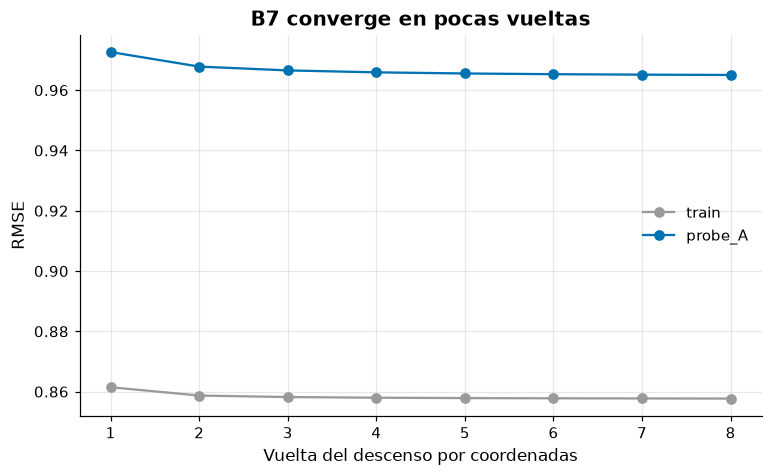

,vuelta,rmse_train,rmse_probe_A
0,1,0.8615,0.9726
1,2,0.8587,0.9678
2,3,0.8582,0.9665
3,4,0.8580,0.9659
4,5,0.8579,0.9655
5,6,0.8578,0.9653
6,7,0.8577,0.9651
7,8,0.8577,0.9650


In [ ]:
fig, ax = plt.subplots()
ax.plot(historial_B7["vuelta"], historial_B7["rmse_train"], marker="o", color=COLOR_SECUNDARIO, label="train")
ax.plot(historial_B7["vuelta"], historial_B7["rmse_probe_A"], marker="o", color=COLOR_PRINCIPAL, label="probe_A")
ax.set_xlabel("Vuelta del descenso por coordenadas")
ax.set_ylabel("RMSE")
ax.set_title("B7 converge en pocas vueltas")
ax.legend()
guardar_figura(fig, "03_curva_B7")
plt.show()
historial_B7.round(4)

El descenso por coordenadas converge rápido. En la primera vuelta el RMSE de probe_A ya es 0.9726, y después de 4 vueltas las mejoras están en el cuarto decimal. Con 8 vueltas llega a 0.9650.

Hay una brecha grande entre train (0.8577) y probe_A (0.9650). En parte es sobreajuste de b_u,t, que tiene 17 millones de parámetros, y en parte es que probe contiene los ratings más recientes, que son más difíciles de predecir.

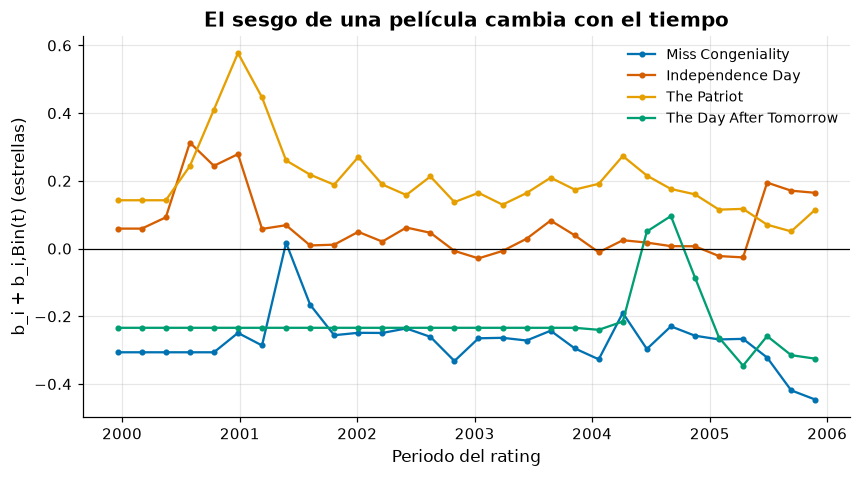

In [ ]:
mas_vistas = np.argsort(-n_por_pelicula)[:4]
centro_periodo = FECHA_ORIGEN + pd.to_timedelta((np.arange(N_BINS) + 0.5) * N_DIAS / N_BINS, unit="D")
colores = [COLOR_PRINCIPAL, COLOR_RESALTE, COLOR_CINEMATCH, COLOR_GANADOR]

fig, ax = plt.subplots(figsize=(9, 4.5))
for pelicula, color in zip(mas_vistas, colores):
    sesgo_total = modelo_B7.b_i[pelicula] + modelo_B7.b_ibin[pelicula * N_BINS:(pelicula + 1) * N_BINS]
    titulo = peliculas.loc[peliculas["movie_idx"] == pelicula, "titulo"].iloc[0]
    ax.plot(centro_periodo, sesgo_total, marker="o", markersize=3, color=color, label=titulo)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Periodo del rating")
ax.set_ylabel("b_i + b_i,Bin(t) (estrellas)")
ax.set_title("El sesgo de una película cambia con el tiempo")
ax.legend(fontsize=9)
guardar_figura(fig, "03_sesgo_pelicula_periodo")
plt.show()

La gráfica muestra b_i + b_i,Bin(t) para las 4 películas con más ratings. Se ven historias distintas. *The Patriot* tiene un pico cerca de +0.58 a inicios de 2001 y luego baja a un nivel cercano a +0.15, como si sus primeros espectadores fueran sus fans. *Miss Congeniality* empeora hacia 2005. *The Day After Tomorrow* se estrenó en 2004, así que antes no tiene ratings y su línea es plana, porque el sesgo por periodo se queda en cero y solo queda su b_i.

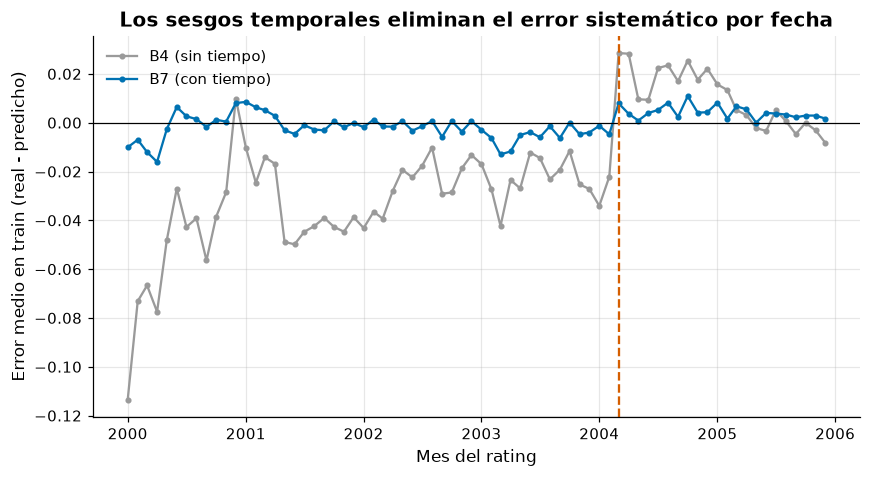

Error medio absoluto por mes, B4: 0.0269, B7: 0.0041


In [ ]:
def error_medio_por_mes(predicciones):
    """Promedio de (rating real - predicción) en train, agrupado por mes."""
    error = train["ratings"].astype(np.float32) - predicciones
    suma = suma_por_grupo(train["dias"], error, N_DIAS)
    n = np.bincount(train["dias"], minlength=N_DIAS)
    por_dia = pd.DataFrame({"suma": suma, "n": n},
                           index=FECHA_ORIGEN + pd.to_timedelta(np.arange(N_DIAS), unit="D"))
    por_mes = por_dia.resample("MS").sum()
    por_mes = por_mes[por_mes["n"] >= 10_000]
    return por_mes["suma"] / por_mes["n"]


error_B4 = error_medio_por_mes(predecir_sesgos(b_i_reg, b_u_reg, train).astype(np.float32))
error_B7 = error_medio_por_mes(modelo_B7.predecir(train))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(error_B4.index, error_B4, marker="o", markersize=3, color=COLOR_SECUNDARIO, label="B4 (sin tiempo)")
ax.plot(error_B7.index, error_B7, marker="o", markersize=3, color=COLOR_PRINCIPAL, label="B7 (con tiempo)")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(pd.Timestamp("2004-03-01"), color=COLOR_RESALTE, linestyle="--")
ax.set_xlabel("Mes del rating")
ax.set_ylabel("Error medio en train (real - predicho)")
ax.set_title("Los sesgos temporales eliminan el error sistemático por fecha")
ax.legend()
guardar_figura(fig, "03_error_por_mes")
plt.show()

print(f"Error medio absoluto por mes, B4: {error_B4.abs().mean():.4f}, B7: {error_B7.abs().mean():.4f}")

Esta gráfica es la prueba de que los sesgos temporales hacen su trabajo. Mostramos el error medio en train por mes (rating real menos predicho). B4, que no conoce la fecha, sobreestima los ratings de 2000 a 2003 (error negativo, hasta -0.11 en el primer mes) y los subestima justo después del salto de marzo de 2004 (error de casi +0.03). B7 se queda pegado a cero. El error medio absoluto por mes pasa de 0.0269 a 0.0041.

In [ ]:
tabla = pd.DataFrame(resultados)
tabla["mejora_vs_anterior"] = -tabla["rmse_probe_A"].diff()
tabla["vs_cinematch_%"] = 100 * (tabla["rmse_probe_A"] - RMSE_CINEMATCH_PROBE) / RMSE_CINEMATCH_PROBE
tabla.round(4)

,modelo,descripcion,rmse_probe_A,mejora_vs_anterior,vs_cinematch_%
0,B0,media global,1.1294,NaN,19.2133
1,B1,mu + b_u,1.0685,0.0609,12.7814
2,B2,mu + b_i,1.0525,0.0160,11.0969
3,B3,mu + b_i + b_u,0.9876,0.0649,4.2430
4,B4,sesgos regularizados,0.9838,0.0038,3.8444
5,B5,+ sesgo de película por periodo,0.9792,0.0046,3.3602
6,B6,+ deriva del sesgo de usuario,0.9754,0.0038,2.9607
7,B7,+ sesgo de usuario por día,0.9650,0.0104,1.8624


La tabla resume la etapa. La columna de mejora muestra cuánto aporta cada pieza. Las más valiosas son juntar los dos sesgos (B3, 0.0649) y el sesgo de usuario solo (B1, 0.0609). Entre los temporales, b_u,t aporta 0.0104, más que b_i,Bin y la deriva juntos.

La última columna compara con Cinematch (0.9474 en probe). Recordemos que medimos en probe_A, la mitad de probe, así que la comparación es aproximada. El mejor baseline, B7, queda 1.86% arriba de Cinematch.

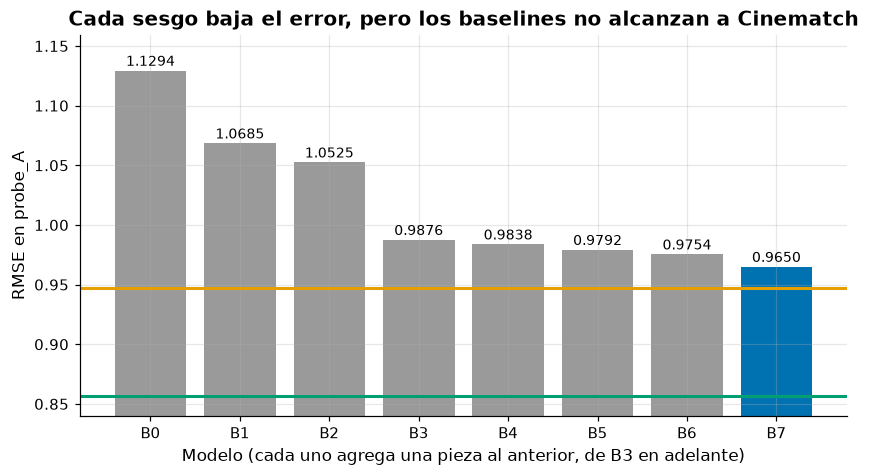

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [COLOR_SECUNDARIO] * len(tabla)
colores[tabla["rmse_probe_A"].idxmin()] = COLOR_PRINCIPAL
ax.bar(tabla["modelo"], tabla["rmse_probe_A"], color=colores)
for x, valor in enumerate(tabla["rmse_probe_A"]):
    ax.text(x, valor + 0.004, f"{valor:.4f}", ha="center", fontsize=9)
ax.axhline(RMSE_CINEMATCH_PROBE, color=COLOR_CINEMATCH, linewidth=2, label=f"Cinematch en probe ({RMSE_CINEMATCH_PROBE})")
ax.axhline(RMSE_GANADOR_TEST, color=COLOR_GANADOR, linewidth=2, label=f"Ganador en test ({RMSE_GANADOR_TEST})")
ax.set_ylim(0.84, tabla["rmse_probe_A"].max() + 0.03)
ax.set_xlabel("Modelo (cada uno agrega una pieza al anterior, de B3 en adelante)")
ax.set_ylabel("RMSE en probe_A")
ax.set_title("Cada sesgo baja el error, pero los baselines no alcanzan a Cinematch")
guardar_figura(fig, "03_rmse_acumulado")
plt.show()

La gráfica pone en perspectiva lo que falta. B7 está a 0.0176 de Cinematch y a 0.108 del 0.8567 de BellKor's Pragmatic Chaos. Ese último número es del test oficial y no de probe, así que la distancia real es aproximada. Con solo sesgos no basta, hace falta que el modelo entienda **qué** películas le gustan a cada usuario y no solo **cuánto** califica en general. Eso es lo que hacen el contenido (Etapa 4) y el filtrado colaborativo (Etapa 5).

In [ ]:
pd.DataFrame(predicciones_A).to_parquet(ARTEFACTOS / "predicciones" / "baselines_probe_A.parquet", index=False)
pd.DataFrame(predicciones_B).to_parquet(ARTEFACTOS / "predicciones" / "baselines_probe_B.parquet", index=False)

np.savez(ARTEFACTOS / "modelos" / "baseline_B7.npz", mu=mu, b_u=modelo_B7.b_u, b_i=modelo_B7.b_i,
         b_ibin=modelo_B7.b_ibin, alpha=modelo_B7.alpha, b_ut=modelo_B7.b_ut,
         dia_medio_usuario=dia_medio_usuario, lambdas=str(lambdas_B7))
np.save(ARTEFACTOS / "usuario_dia_train.npy", train["usuario_dia"])
np.save(ARTEFACTOS / "usuario_dia_probe_A.npy", probe_A["usuario_dia"])
np.save(ARTEFACTOS / "usuario_dia_probe_B.npy", probe_B["usuario_dia"])

for archivo in sorted((ARTEFACTOS / "predicciones").glob("baselines_*")) + sorted((ARTEFACTOS / "modelos").glob("*.npz")):
    print(f"{archivo.name:<32} {archivo.stat().st_size / 1024**2:>8.1f} MB")

baselines_probe_A.parquet            19.0 MB
baselines_probe_B.parquet            19.0 MB
baseline_B7.npz                     147.0 MB


Guardamos las predicciones de los 8 baselines para probe_A y probe_B (servirán como entradas del blending en la Etapa 6) y los parámetros de B7, que la Etapa 5 usa como punto de partida para timeSVD++. El archivo de B7 pesa 147 MB, casi todo por los 17 millones de sesgos b_u,t.

### Resumen de la Etapa 3

| Modelo | RMSE probe_A | Pieza que agrega |
|---|---|---|
| B0 | 1.1294 | media global |
| B1 | 1.0685 | sesgo de usuario |
| B2 | 1.0525 | sesgo de película |
| B3 | 0.9876 | ambos sesgos |
| B4 | 0.9838 | regularización (λ_i = 10, λ_u = 5) |
| B5 | 0.9792 | sesgo de película por periodo (λ = 200) |
| B6 | 0.9754 | deriva del usuario (λ = 10,000) |
| B7 | **0.9650** | sesgo de usuario por día (λ = 10) |

- **Hallazgos.** La regularización importa sobre todo para los usuarios, ya que las películas tienen suficientes ratings. Los sesgos temporales eliminan casi todo el error sistemático por fecha (de 0.0269 a 0.0041 por mes) y el más útil es el sesgo por usuario y día, pues el 37% de probe_A tiene ratings de train del mismo día.
- **Comparación.** B7 queda 1.86% arriba de Cinematch (0.9474) y lejos del 0.8567 del ganador. Las dos comparaciones son aproximadas, porque probe_A no es probe completo ni el test oficial.
- **Problemas.** En la primera corrida dos λ (de b_i,Bin y de α_u) quedaron en el borde de su rejilla. Extendimos las rejillas y en la corrida final los tres óptimos quedaron en el interior. Ambas corridas están registradas en `experimentos.csv`, así que los modelos B0 a B4 aparecen dos veces, con resultados idénticos. Cada ajuste temporal tarda de 2.5 a 4 minutos, porque los accesos a 17 millones de sesgos b_u,t están dispersos en memoria.
- **Cambio respecto al plan.** Los sesgos temporales se ajustaron por descenso por coordenadas en lugar de SGD. Es más estable y no tiene tasas de aprendizaje que ajustar.

**Siguiente etapa.** Etapa 4, filtrado basado en contenido con los títulos y años de las películas.

## Etapa 4. Filtrado basado en contenido

Un recomendador basado en contenido describe cada película por sus características y aprende qué características le gustan a cada usuario. En el Netflix Prize el único contenido disponible es el **título** y el **año de estreno**, así que hay que ser honestos desde el inicio. Un título dice muy poco del género, el tono o la calidad de una película, por lo tanto no esperamos que el contenido compita con los sesgos. Lo que sí esperamos es que capture algunas cosas que los sesgos no ven, como las sagas ("Star Trek", "Harry Potter") o las temporadas de una misma serie.

En este notebook hacemos lo siguiente.
1. Representar los títulos con TF-IDF de palabras y de n-gramas de caracteres.
2. Medir el efecto del año de estreno y de la edad de la película.
3. Usar la similitud de títulos como un kNN sobre el baseline B4, para todos los usuarios.
4. Entrenar un modelo por usuario (ridge y Naive Bayes) en una muestra, como lo plantea la teoría.
5. Seleccionar términos de forma supervisada con chi cuadrada.
6. Ver dónde ayuda el contenido y dónde no.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import roc_auc_score, precision_score, recall_score

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.carga import FECHA_ORIGEN
from src.datos import leer_train, leer_conjunto, construir_csr_usuario, guardar_csr, N_USUARIOS, N_PELICULAS
from src.baselines import sesgos_b4, lambdas_b4_desde_experimentos, suma_por_grupo
from src.metricas import rmse, registrar_experimento
from src import vecinos
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL,
                                 COLOR_SECUNDARIO, COLOR_RESALTE, COLOR_CINEMATCH)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
aplicar_estilo()

Usamos scikit-learn para TF-IDF y los modelos por usuario, y `src/vecinos.py` para el kNN, que también usaremos en las Etapas 5 y 6.

In [ ]:
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx").reset_index(drop=True)
train = leer_train()
probe_A = leer_conjunto("probe_A")
probe_B = leer_conjunto("probe_B")
N_TRAIN = len(train["ratings"])

LAMBDA_I, LAMBDA_U = lambdas_b4_desde_experimentos(RAIZ / "experimentos.csv")
mu, b_i, b_u = sesgos_b4(train, N_USUARIOS, N_PELICULAS, LAMBDA_I, LAMBDA_U)


def prediccion_b4(datos):
    return np.clip(mu + b_u[datos["usuarios"]] + b_i[datos["peliculas"]], 1, 5)


rmse_b4 = rmse(probe_A["ratings"], prediccion_b4(probe_A))
n_por_pelicula = np.bincount(train["peliculas"], minlength=N_PELICULAS)
print(f"B4 recalculado con lambda_i = {LAMBDA_I:g}, lambda_u = {LAMBDA_U:g}: RMSE probe_A = {rmse_b4:.4f}")

B4 recalculado con lambda_i = 10, lambda_u = 5: RMSE probe_A = 0.9838


Recalculamos B4 con los λ que guardamos en `experimentos.csv` (λ_i = 10, λ_u = 5). Da el mismo RMSE que en la Etapa 3, 0.9838, y es la base sobre la que medimos si el contenido aporta algo.

### 1. Representar los títulos con TF-IDF

In [ ]:
titulos = peliculas["titulo"].fillna("")

tfidf_palabras = TfidfVectorizer(analyzer="word", lowercase=True, min_df=2)
matriz_palabras = tfidf_palabras.fit_transform(titulos)

tfidf_caracteres = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), lowercase=True, min_df=2)
matriz_caracteres = tfidf_caracteres.fit_transform(titulos)

print(f"Palabras: {matriz_palabras.shape[1]:,} términos, {matriz_palabras.nnz / len(titulos):.1f} por título")
print(f"n-gramas de caracteres: {matriz_caracteres.shape[1]:,} términos, {matriz_caracteres.nnz / len(titulos):.1f} por título")

idf = pd.Series(tfidf_palabras.idf_, index=tfidf_palabras.get_feature_names_out())
print("\nPalabras con IDF más bajo (más comunes):", ", ".join(idf.nsmallest(10).index))

Palabras: 5,423 términos, 3.0 por título
n-gramas de caracteres: 40,825 términos, 41.9 por título

Palabras con IDF más bajo (más comunes): the, of, and, season, in, to, live, vol, on, man


TF-IDF convierte cada título en un vector. Cada término tiene un peso alto si aparece en el título (TF) y si es raro en el catálogo (IDF). Por ejemplo, "the" aparece en casi todo y pesa poco, en cambio "Sopranos" aparece en pocos títulos y pesa mucho.

Probamos dos representaciones.
- **Palabras.** 5,423 términos (con al menos 2 apariciones) y unos 3 términos por título. Las palabras más comunes son "the", "of", "and" y, curiosamente, "season", ya que el catálogo tiene muchas temporadas de series.
- **n-gramas de caracteres.** Pedazos de 3 a 5 letras, por ejemplo "pot", "pott", "potte" para "Potter". Son 40,825 términos y unos 42 por título. Toleran variaciones como plurales, números romanos o errores de escritura.

In [ ]:
def buscar_pelicula(texto):
    """Devuelve el índice de la película más vista cuyo título contiene `texto`."""
    candidatas = peliculas[peliculas["titulo"].str.contains(texto, case=False, regex=False)]
    return int(candidatas.loc[candidatas["movie_idx"].map(lambda i: n_por_pelicula[i]).idxmax(), "movie_idx"])


def vecinos_por_titulo(matriz, indice, n=6):
    similitud = (matriz @ matriz[indice].T).toarray().ravel()
    similitud[indice] = -1
    mejores = np.argsort(-similitud)[:n]
    return pd.DataFrame({"titulo": peliculas.loc[mejores, "titulo"].to_numpy(),
                         "similitud": similitud[mejores].round(3)})


ejemplos = ["Harry Potter and the Sorcerer", "Star Trek: The Next Generation", "Lord of the Rings: The Fellowship",
            "Rocky"]
for texto in ejemplos:
    indice = buscar_pelicula(texto)
    print(f"\n=== {peliculas.loc[indice, 'titulo']} ({peliculas.loc[indice, 'anio']})")
    lado = pd.concat([vecinos_por_titulo(matriz_palabras, indice).add_suffix("_palabras"),
                      vecinos_por_titulo(matriz_caracteres, indice).add_suffix("_caracteres")], axis=1)
    print(lado.to_string(index=False))


=== Harry Potter and the Sorcerer's Stone (2001)
                                      titulo_palabras  similitud_palabras                                     titulo_caracteres  similitud_caracteres
Harry Potter and the Sorcerer's Stone: Bonus Material               0.913 Harry Potter and the Sorcerer's Stone: Bonus Material                 0.844
           J.K. Rowling and the Birth of Harry Potter               0.575                                              Sorcerer                 0.525
              Harry Potter and the Chamber of Secrets               0.516                            The Sword and the Sorcerer                 0.466
                                             Sorcerer               0.511                                 Sorcerer on the Rocks                 0.437
                                      Harry and Tonto               0.508                                  The Sorcerer Hunters                 0.436
             Harry Potter and the Prisoner of Azka

La similitud coseno entre dos vectores TF-IDF va de 0 (nada en común) a 1 (mismos términos). Los ejemplos muestran las fortalezas y debilidades de cada representación.

- **Star Trek: The Next Generation.** Las dos encuentran las otras 6 temporadas. Con palabras todas empatan en 1.0, ya que "Season 1" y "Season 7" solo difieren en el número, que TF-IDF de palabras ignora (los tokens de un carácter no cuentan). Los n-gramas sí distinguen un poco, de 0.986 a 0.992.
- **Rocky.** Con palabras, "Rocky Marciano" y "Rocky (Hindi)" empatan en 1.0 con "Rocky V", aunque no tienen nada que ver con la saga. Con n-gramas las secuelas (V, II, IV, III) quedan primero y "Rocky Marciano" baja a 0.556.
- **Harry Potter.** Ambas encuentran el material extra y las secuelas, pero también "Sorcerer" y "The Sword and the Sorcerer", que solo comparten una palabra.
- **El Señor de los Anillos.** Con n-gramas aparece "The Ring", una película de terror sin relación alguna.

Este es el límite del contenido por título. Sabe que dos títulos se parecen, pero no si las películas se parecen.

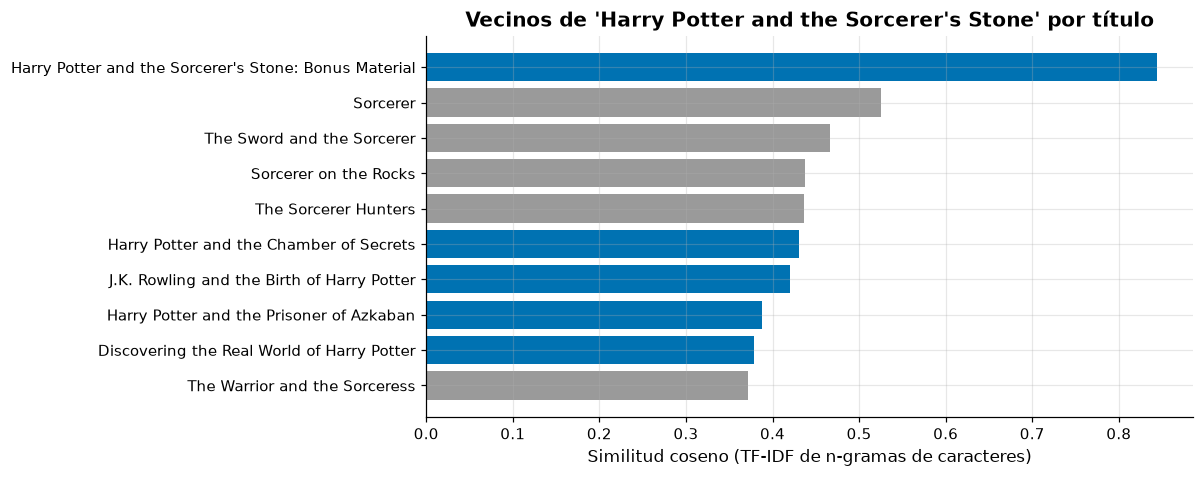

In [ ]:
indice_hp = buscar_pelicula("Harry Potter and the Sorcerer")
vecinos_hp = vecinos_por_titulo(matriz_caracteres, indice_hp, n=10).iloc[::-1]
es_saga = vecinos_hp["titulo"].str.contains("Harry Potter")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(vecinos_hp["titulo"], vecinos_hp["similitud"],
        color=np.where(es_saga, COLOR_PRINCIPAL, COLOR_SECUNDARIO))
ax.set_xlabel("Similitud coseno (TF-IDF de n-gramas de caracteres)")
ax.set_title(f"Vecinos de '{peliculas.loc[indice_hp, 'titulo']}' por título")
guardar_figura(fig, "04_vecinos_harry_potter")
plt.show()

En azul están los títulos de la saga. El vecino más cercano es el material extra del mismo DVD (0.844), después vienen cuatro títulos con "Sorcerer" y luego las secuelas, con similitudes de 0.38 a 0.43. Un sistema de contenido puro recomendaría "Sorcerer" (un thriller de 1977) a un fan de Harry Potter con la misma confianza que la segunda película de la saga.

### 2. Año de estreno y edad de la película

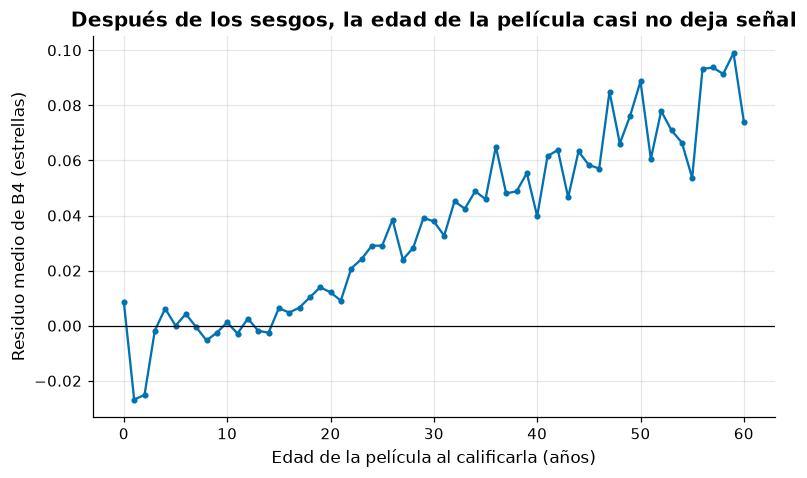

Efecto por edad: de -0.027 a +0.099 estrellas


In [ ]:
anio_estreno = peliculas["anio"].fillna(-1).to_numpy().astype(np.int16)
anio_del_dia = (FECHA_ORIGEN + pd.to_timedelta(np.arange(2243), unit="D")).year.to_numpy().astype(np.int16)


def edad_al_calificar(datos):
    """Años entre el estreno y el rating, recortado a [0, 60]. -1 si no hay año."""
    edad = anio_del_dia[datos["dias"]] - anio_estreno[datos["peliculas"]]
    edad = np.clip(edad, 0, 60).astype(np.int16)
    edad[anio_estreno[datos["peliculas"]] < 0] = -1
    return edad


edad_train = edad_al_calificar(train)
residuo_b4 = (train["ratings"] - (mu + b_u[train["usuarios"]] + b_i[train["peliculas"]])).astype(np.float32)
con_anio = edad_train >= 0
suma_edad = suma_por_grupo(edad_train[con_anio], residuo_b4[con_anio], 61)
n_edad = np.bincount(edad_train[con_anio], minlength=61)
LAMBDA_EDAD = 1000
efecto_edad = suma_edad / (n_edad + LAMBDA_EDAD)
del residuo_b4

fig, ax = plt.subplots()
ax.plot(np.arange(61), efecto_edad, marker="o", markersize=3, color=COLOR_PRINCIPAL)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Edad de la película al calificarla (años)")
ax.set_ylabel("Residuo medio de B4 (estrellas)")
ax.set_title("Después de los sesgos, la edad de la película casi no deja señal")
guardar_figura(fig, "04_residuo_por_edad")
plt.show()
print(f"Efecto por edad: de {efecto_edad.min():+.3f} a {efecto_edad.max():+.3f} estrellas")

En la Etapa 2 vimos que las películas viejas tienen mejores promedios. Pero el sesgo b_i de B4 ya captura el promedio de cada película, así que la pregunta aquí es si queda algo **después** de los sesgos.

Calculamos el residuo de B4 (rating real menos predicción) promediado por la edad de la película al momento de calificarla, regularizado con λ = 1,000. El efecto va de -0.027 a +0.099 estrellas. Hasta los 15 años de edad el residuo es casi cero, y desde ahí sube de forma constante. Una película de 50 años se califica unas 0.08 estrellas mejor de lo que B4 espera.

In [ ]:
def prediccion_edad(datos):
    edad = edad_al_calificar(datos)
    ajuste = np.where(edad >= 0, efecto_edad[np.maximum(edad, 0)], 0.0)
    return np.clip(prediccion_b4(datos) + ajuste, 1, 5)


inicio = time.perf_counter()
pred_edad_A = prediccion_edad(probe_A)
rmse_edad = rmse(probe_A["ratings"], pred_edad_A)
registrar_experimento("C_edad", {"lambda_edad": LAMBDA_EDAD, "base": "B4"}, N_TRAIN, rmse_edad,
                      time.perf_counter() - inicio, "B4 + residuo medio por edad de la película")
print(f"B4: {rmse_b4:.4f}   B4 + edad: {rmse_edad:.4f}   diferencia {rmse_edad - rmse_b4:+.4f}")

B4: 0.9838   B4 + edad: 0.9835   diferencia -0.0004


Aun así, sumar este efecto a B4 apenas mejora el RMSE, de 0.9838 a 0.9835 (0.0004 menos). La razón es que la mayoría de los ratings son de películas con menos de 15 años de edad, donde el efecto es casi cero. La señal existe, pero afecta a pocos ratings.

### 3. kNN por similitud de títulos para todos los usuarios

In [ ]:
def top_k_por_titulo(matriz, k=50, bloque=2000):
    """Los k vecinos más parecidos por título de cada película (similitud coseno)."""
    n = matriz.shape[0]
    indices = np.full((n, k), -1, np.int32)
    valores = np.zeros((n, k), np.float32)
    for inicio in range(0, n, bloque):
        fin = min(inicio + bloque, n)
        similitud = (matriz[inicio:fin] @ matriz.T).toarray().astype(np.float32)
        similitud[np.arange(fin - inicio), np.arange(inicio, fin)] = 0
        mejores = np.argpartition(-similitud, k, axis=1)[:, :k]
        filas = np.arange(fin - inicio)[:, None]
        orden = np.argsort(-similitud[filas, mejores], axis=1)
        mejores = mejores[filas, orden]
        indices[inicio:fin] = np.where(similitud[filas, mejores] > 0, mejores, -1)
        valores[inicio:fin] = np.maximum(similitud[filas, mejores], 0)
    return indices, valores


vecinos_caracteres, similitud_caracteres = top_k_por_titulo(matriz_caracteres)
vecinos_palabras, similitud_palabras = top_k_por_titulo(matriz_palabras)
print(f"Similitud media del vecino 1: caracteres {similitud_caracteres[:, 0].mean():.3f}, "
      f"palabras {similitud_palabras[:, 0].mean():.3f}")
print(f"Similitud media del vecino 50: caracteres {similitud_caracteres[:, -1].mean():.3f}, "
      f"palabras {similitud_palabras[:, -1].mean():.3f}")

Similitud media del vecino 1: caracteres 0.660, palabras 0.688
Similitud media del vecino 50: caracteres 0.180, palabras 0.179


Para aplicar el contenido a los 480 mil usuarios usamos un kNN ítem-ítem donde la similitud viene del título. Guardamos para cada película sus 50 títulos más parecidos. En promedio el vecino más cercano tiene similitud de 0.66 y el vecino 50 apenas 0.18, así que más allá de los primeros vecinos la relación es débil.

La predicción para el usuario u y la película i es

r̂_ui = B4_ui + Σ_j s_ij · (r_uj - B4_uj) / (Σ_j |s_ij| + reg)

donde j recorre las vecinas de i que u ya calificó. En palabras, si al usuario le gustaron más de lo esperado las películas con títulos parecidos, subimos la predicción.

In [ ]:
csr_usuario = construir_csr_usuario(train, semilla=SEMILLA)
guardar_csr("csr_usuario", csr_usuario)

busqueda = []
for nombre, vecinos_titulo, similitud_titulo in [("caracteres", vecinos_caracteres, similitud_caracteres),
                                                  ("palabras", vecinos_palabras, similitud_palabras)]:
    for k in [10, 50]:
        for regularizacion in [0.5, 2, 8]:
            inicio = time.perf_counter()
            pred, usados = vecinos.predecir(probe_A, csr_usuario, vecinos_titulo[:, :k].copy(),
                                            similitud_titulo[:, :k].copy(), mu, b_u, b_i, regularizacion)
            error = rmse(probe_A["ratings"], pred)
            hiper = {"representacion": nombre, "k": k, "regularizacion": regularizacion}
            registrar_experimento("C_knn_titulo_busqueda", hiper, N_TRAIN, error, time.perf_counter() - inicio,
                                  "kNN por similitud de título sobre B4")
            busqueda.append({**hiper, "rmse_probe_A": error})

busqueda = pd.DataFrame(busqueda)
mejor = busqueda.loc[busqueda["rmse_probe_A"].idxmin()]
print(busqueda.pivot_table(index=["representacion", "k"], columns="regularizacion", values="rmse_probe_A").round(4))
print(f"\nMejor: {mejor.to_dict()}")

regularizacion        0.5     2.0     8.0
representacion k                         
caracteres     10  0.9830  0.9769  0.9799
               50  0.9897  0.9777  0.9795
palabras       10  0.9826  0.9770  0.9799
               50  0.9905  0.9783  0.9796

Mejor: {'representacion': 'caracteres', 'k': 10, 'regularizacion': 2.0, 'rmse_probe_A': 0.9769244177928923}


Probamos las dos representaciones, 10 o 50 vecinos y tres valores de regularización. Lo que más importa es la regularización. Con reg = 0.5 el modelo le cree demasiado a un solo vecino y empeora (hasta 0.9905), y con reg = 2 llega al mínimo. Usar 10 vecinos es mejor que 50, ya que los vecinos lejanos casi no se parecen. La mejor combinación es n-gramas de caracteres, k = 10 y reg = 2, con RMSE de 0.9769, aunque las palabras quedan prácticamente empatadas (0.9770).

In [ ]:
MEJOR = {"caracteres": (vecinos_caracteres, similitud_caracteres),
         "palabras": (vecinos_palabras, similitud_palabras)}[mejor["representacion"]]
K_TITULO, REG_TITULO = int(mejor["k"]), float(mejor["regularizacion"])
vecinos_titulo = MEJOR[0][:, :K_TITULO].copy()
similitud_titulo = MEJOR[1][:, :K_TITULO].copy()

inicio = time.perf_counter()
pred_knn_A, usados_A = vecinos.predecir(probe_A, csr_usuario, vecinos_titulo, similitud_titulo, mu, b_u, b_i, REG_TITULO)
pred_knn_B, _ = vecinos.predecir(probe_B, csr_usuario, vecinos_titulo, similitud_titulo, mu, b_u, b_i, REG_TITULO)
rmse_knn = rmse(probe_A["ratings"], pred_knn_A)
registrar_experimento("C_knn_titulo", {"representacion": mejor["representacion"], "k": K_TITULO,
                                       "regularizacion": REG_TITULO}, N_TRAIN, rmse_knn,
                      time.perf_counter() - inicio, "modelo de contenido final")
print(f"kNN por título: RMSE probe_A = {rmse_knn:.4f} (B4 = {rmse_b4:.4f})")
print(f"Filas de probe_A sin ningún vecino de título calificado: {100 * (usados_A == 0).mean():.1f}%")

kNN por título: RMSE probe_A = 0.9769 (B4 = 0.9838)
Filas de probe_A sin ningún vecino de título calificado: 80.6%


El kNN por título baja el RMSE de B4 de 0.9838 a 0.9769, una mejora de 0.0069. Es más que la regularización de la Etapa 3 y que el efecto de la edad.

Lo sorprendente es que el 80.6% de las filas de probe_A no tiene ninguna vecina de título calificada por el usuario, así que para ellas la predicción es igual a B4. Toda la mejora sale del 19.4% restante. Para esos casos el título es muy informativo, sobre todo cuando son temporadas de una serie o partes de una saga que el usuario ya calificó.

           filas  rmse_b4  rmse_knn_titulo  mejora
segmento                                          
< 500      25336   1.0564           1.0474  0.0090
500-2k     44118   1.0229           1.0111  0.0118
2k-10k    108244   0.9935           0.9839  0.0097
10k-50k   237410   0.9689           0.9611  0.0079
> 50k     289089   0.9796           0.9755  0.0041


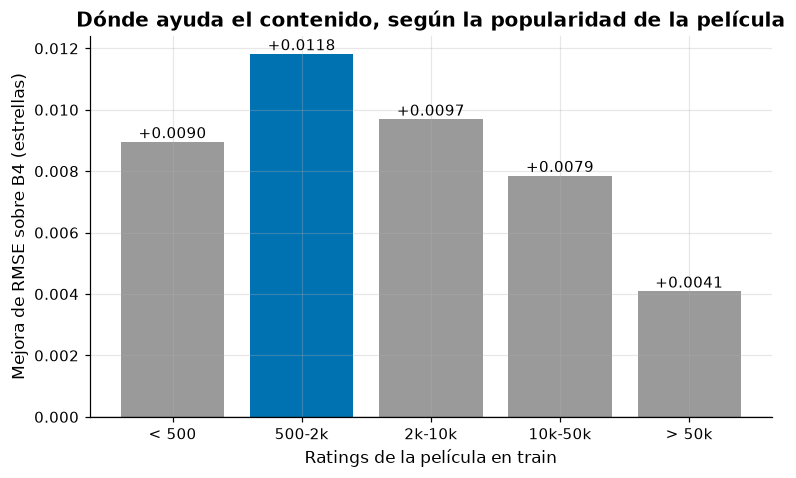

In [ ]:
error_b4 = (probe_A["ratings"] - prediccion_b4(probe_A)) ** 2
error_knn = (probe_A["ratings"] - pred_knn_A) ** 2
popularidad = n_por_pelicula[probe_A["peliculas"]]
tramos = [0, 500, 2_000, 10_000, 50_000, 300_000]
etiquetas = ["< 500", "500-2k", "2k-10k", "10k-50k", "> 50k"]
segmento = pd.cut(popularidad, tramos, labels=etiquetas)

por_tramo = pd.DataFrame({"segmento": segmento, "b4": error_b4, "knn": error_knn}).groupby("segmento", observed=True)
comparacion = pd.DataFrame({"filas": por_tramo.size(),
                            "rmse_b4": np.sqrt(por_tramo["b4"].mean()),
                            "rmse_knn_titulo": np.sqrt(por_tramo["knn"].mean())})
comparacion["mejora"] = comparacion["rmse_b4"] - comparacion["rmse_knn_titulo"]
print(comparacion.round(4))

fig, ax = plt.subplots()
colores = [COLOR_PRINCIPAL if valor == comparacion["mejora"].max() else COLOR_SECUNDARIO for valor in comparacion["mejora"]]
ax.bar(comparacion.index.astype(str), comparacion["mejora"], color=colores)
for x, valor in enumerate(comparacion["mejora"]):
    ax.text(x, valor, f"{valor:+.4f}", ha="center", va="bottom")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Ratings de la película en train")
ax.set_ylabel("Mejora de RMSE sobre B4 (estrellas)")
ax.set_title("Dónde ayuda el contenido, según la popularidad de la película")
guardar_figura(fig, "04_mejora_por_popularidad")
plt.show()

Partimos probe_A según cuántos ratings tiene la película en train. El contenido ayuda en todos los tramos, y más en las películas de nicho y medianas (mejora de 0.0118 entre 500 y 2,000 ratings y de 0.0090 debajo de 500) que en las muy populares (0.0041 con más de 50 mil ratings). Esto confirma la intuición. Cuando hay pocos ratings el sesgo b_i se estima peor y el parecido con otras películas que el usuario conoce aporta más.

El efecto no es tan grande como podría esperarse, porque en el Netflix Prize casi no hay películas realmente nuevas (en la Etapa 2 vimos que solo el 0.5% tiene menos de 50 ratings).

### 4. Un modelo de contenido por usuario

In [ ]:
rng = np.random.default_rng(SEMILLA)
ratings_por_usuario = np.diff(csr_usuario["inicio"])
probe_A_por_usuario = np.bincount(probe_A["usuarios"], minlength=N_USUARIOS)
candidatos = np.flatnonzero((ratings_por_usuario >= 50) & (probe_A_por_usuario >= 3))
usuarios_muestra = rng.choice(candidatos, 2_000, replace=False)
print(f"Usuarios candidatos (>= 50 ratings en train y >= 3 en probe_A): {len(candidatos):,}")

decada = np.where(anio_estreno > 0, (anio_estreno // 10) * 10, 0)
decadas = np.unique(decada)
matriz_decada = (decada[:, None] == decadas[None, :]).astype(np.float32)
from scipy.sparse import hstack, csr_matrix
caracteristicas = hstack([matriz_palabras, csr_matrix(matriz_decada)]).tocsr()
binarias = (caracteristicas > 0).astype(np.float32)
nombres_caracteristicas = list(tfidf_palabras.get_feature_names_out()) + [f"década {d}" for d in decadas]
print(f"Características por película: {caracteristicas.shape[1]:,} (palabras del título + década de estreno)")

Usuarios candidatos (>= 50 ratings en train y >= 3 en probe_A): 57,206
Características por película: 5,436 (palabras del título + década de estreno)


La teoría del filtrado basado en contenido plantea entrenar un modelo **por cada usuario**, que aprende de sus ratings qué características le gustan. Hacerlo para 480 mil usuarios no tiene sentido aquí, así que lo hacemos en una muestra de 2,000 usuarios tomada con semilla 42 entre los 57,206 que tienen al menos 50 ratings en train (para que haya de qué aprender) y al menos 3 en probe_A (para poder evaluar).

Cada película se describe con 5,436 características, que son las palabras del título (TF-IDF) y la década de estreno codificada como variables 0/1.

In [ ]:
indice_fila_A = {}
orden_A = np.argsort(probe_A["usuarios"], kind="stable")
inicio_A = np.searchsorted(probe_A["usuarios"][orden_A], np.arange(N_USUARIOS + 1))

reales, pred_ridge, pred_media, pred_b4_muestra = [], [], [], []
gusta_real, prob_nb, puntaje_b4 = [], [], []
modelos_ridge = {}
inicio = time.perf_counter()
for u in usuarios_muestra:
    a, b = csr_usuario["inicio"][u], csr_usuario["inicio"][u + 1]
    pelis_u = csr_usuario["peliculas"][a:b]
    ratings_u = csr_usuario["ratings"][a:b].astype(np.float32)
    filas = orden_A[inicio_A[u]:inicio_A[u + 1]]
    pelis_eval = probe_A["peliculas"][filas]

    ridge = Ridge(alpha=1.0).fit(caracteristicas[pelis_u], ratings_u)
    modelos_ridge[u] = ridge
    pred_ridge.append(np.clip(ridge.predict(caracteristicas[pelis_eval]), 1, 5))
    pred_media.append(np.full(len(filas), ratings_u.mean()))
    pred_b4_muestra.append(prediccion_b4({"usuarios": probe_A["usuarios"][filas], "peliculas": pelis_eval}))
    reales.append(probe_A["ratings"][filas])

    gusta = ratings_u >= 4
    if 0 < gusta.sum() < len(gusta):
        nb = BernoulliNB(alpha=1.0).fit(binarias[pelis_u], gusta)
        prob_nb.append(nb.predict_proba(binarias[pelis_eval])[:, 1])
    else:
        prob_nb.append(np.full(len(filas), float(gusta.mean())))
    gusta_real.append(probe_A["ratings"][filas] >= 4)

reales = np.concatenate(reales)
pred_ridge, pred_media, pred_b4_muestra = map(np.concatenate, (pred_ridge, pred_media, pred_b4_muestra))
gusta_real, prob_nb = np.concatenate(gusta_real), np.concatenate(prob_nb)
print(f"Modelos ajustados en {time.perf_counter() - inicio:.0f} s, {len(reales):,} filas de probe_A evaluadas")

Modelos ajustados en 11 s, 6,671 filas de probe_A evaluadas


Para cada usuario ajustamos dos modelos.
- **Regresión ridge**, que predice el rating como suma de pesos de las palabras y la década. La penalización ridge (alpha = 1) evita pesos enormes en palabras que el usuario vio una sola vez.
- **Naive Bayes Bernoulli**, que predice la probabilidad de "le gusta" (rating ≥ 4) según qué palabras aparecen en el título.

Ajustar los 4,000 modelos tomó 11 segundos, y se evaluaron 6,671 filas de probe_A.

In [ ]:
resumen_usuario = pd.DataFrame({
    "modelo": ["media del usuario", "ridge por usuario (contenido)", "B4 (colaborativo simple)"],
    "rmse": [rmse(reales, pred_media), rmse(reales, pred_ridge), rmse(reales, pred_b4_muestra)],
})
registrar_experimento("C_ridge_por_usuario", {"alpha": 1.0, "usuarios": 2000}, N_TRAIN,
                      resumen_usuario.loc[1, "rmse"], 0, "solo muestra de 2,000 usuarios, RMSE en sus filas de probe_A")
resumen_usuario.round(4)

,modelo,rmse
0,media del usuario,1.0372
1,ridge por usuario (contenido),1.0162
2,B4 (colaborativo simple),0.9563


El ridge por usuario (1.0162) mejora a la media del usuario (1.0372), lo que confirma que el título lleva algo de información sobre los gustos. Pero queda muy lejos de B4 (0.9563 en estas mismas filas). La razón es que B4 usa lo que **todos** los usuarios opinan de cada película a través de b_i, en cambio el ridge solo sabe lo que dice el título.

In [ ]:
puntajes = {"Naive Bayes por usuario (contenido)": prob_nb,
            "Ridge por usuario (contenido)": pred_ridge,
            "B4 (colaborativo simple)": pred_b4_muestra}
umbrales = {"Naive Bayes por usuario (contenido)": 0.5,
            "Ridge por usuario (contenido)": 3.5,
            "B4 (colaborativo simple)": 3.5}

clasificacion = []
for nombre, puntaje in puntajes.items():
    predicho = puntaje >= umbrales[nombre]
    clasificacion.append({"modelo": nombre,
                          "AUC": roc_auc_score(gusta_real, puntaje),
                          "precision": precision_score(gusta_real, predicho),
                          "recall": recall_score(gusta_real, predicho)})
clasificacion = pd.DataFrame(clasificacion)
print(f"Proporción real de 'le gusta' en estas filas: {gusta_real.mean():.3f}")
clasificacion.round(3)

Proporción real de 'le gusta' en estas filas: 0.602


,modelo,AUC,precision,recall
0,Naive Bayes por usuario (contenido),0.662,0.677,0.812
1,Ridge por usuario (contenido),0.704,0.709,0.741
2,B4 (colaborativo simple),0.767,0.741,0.783


También evaluamos como clasificación, con "le gusta" = rating ≥ 4. En estas filas el 60.2% son "le gusta".

- **AUC** es la probabilidad de que el modelo le dé mayor puntaje a una película que gustó que a una que no. 0.5 es azar y 1 es perfecto.
- **Precision** es, de las que el modelo dice que gustan, qué fracción gustó de verdad.
- **Recall** es, de las que gustaron, qué fracción detectó el modelo.

Para el ridge y B4 decimos "le gusta" si la predicción es al menos 3.5, y para Naive Bayes si la probabilidad es al menos 0.5. Naive Bayes tiene el recall más alto (0.812) pero la peor precisión (0.677), ya que tiende a decir que todo gusta.

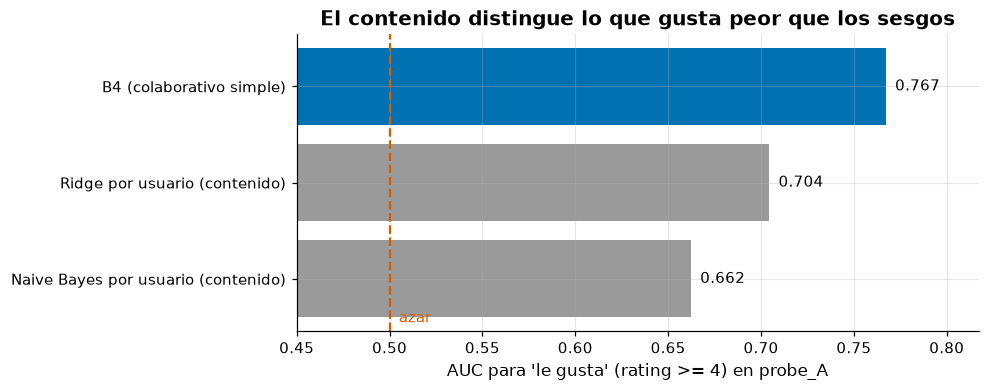

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
orden = clasificacion.sort_values("AUC")
colores = [COLOR_PRINCIPAL if "B4" in m else COLOR_SECUNDARIO for m in orden["modelo"]]
ax.barh(orden["modelo"], orden["AUC"], color=colores)
for y, valor in enumerate(orden["AUC"]):
    ax.text(valor + 0.005, y, f"{valor:.3f}", va="center")
ax.axvline(0.5, color=COLOR_RESALTE, linestyle="--")
ax.text(0.505, -0.45, "azar", color=COLOR_RESALTE)
ax.set_xlim(0.45, max(orden["AUC"]) + 0.05)
ax.set_xlabel("AUC para 'le gusta' (rating >= 4) en probe_A")
ax.set_title("El contenido distingue lo que gusta peor que los sesgos")
guardar_figura(fig, "04_auc_le_gusta")
plt.show()

Los tres modelos superan al azar, pero B4 (0.767) supera claramente a los dos modelos de contenido (0.704 y 0.662). Naive Bayes queda último porque supone que las palabras son independientes y, con títulos de 3 palabras, tiene muy poca información para estimar cada probabilidad.

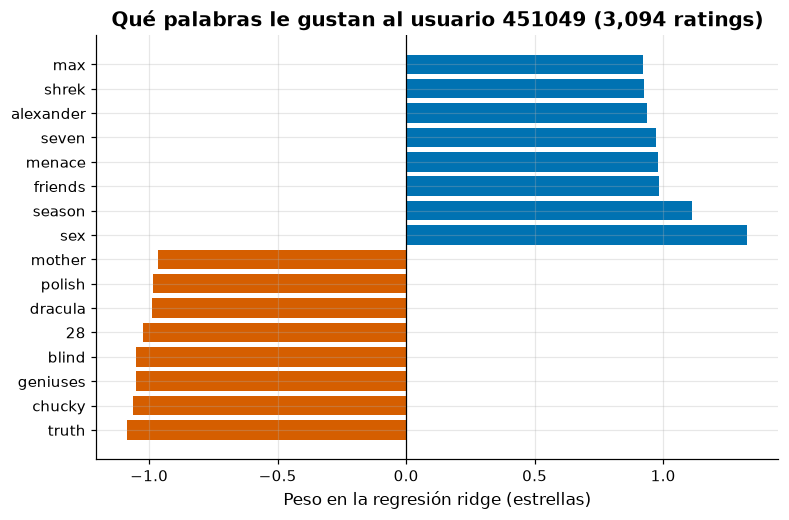

In [ ]:
# Un usuario de ejemplo: el de la muestra con más ratings
u_ejemplo = usuarios_muestra[np.argmax(ratings_por_usuario[usuarios_muestra])]
coeficientes = pd.Series(modelos_ridge[u_ejemplo].coef_, index=nombres_caracteristicas)
coeficientes = coeficientes[coeficientes != 0]
extremos = pd.concat([coeficientes.nsmallest(8), coeficientes.nlargest(8)])

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(extremos.index, extremos.values,
        color=np.where(extremos.values > 0, COLOR_PRINCIPAL, COLOR_RESALTE))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Peso en la regresión ridge (estrellas)")
ax.set_title(f"Qué palabras le gustan al usuario {u_ejemplo} ({ratings_por_usuario[u_ejemplo]:,} ratings)")
guardar_figura(fig, "04_ridge_usuario_ejemplo")
plt.show()

Para entender qué aprende el ridge miramos al usuario de la muestra con más ratings. Sus pesos positivos más altos son "sex", "season", "friends", "menace" y "shrek", lo que sugiere a alguien que disfruta las series de televisión (Sex and the City, Friends) y la animación. Los pesos negativos incluyen "chucky", "dracula" y "28", o sea, películas de terror.

Esto ilustra la ventaja del contenido, que es explicable. Podemos decir "te recomendamos esta temporada porque calificaste bien otras temporadas de Friends". Pero también su debilidad, pues palabras como "truth", "mother" o "blind" no describen ningún gusto real.

### 5. Selección supervisada de términos

In [ ]:
gustos_por_pelicula = np.bincount(train["peliculas"], weights=(train["ratings"] >= 4), minlength=N_PELICULAS)
presencia = (matriz_palabras > 0).astype(np.float64).tocsc()
peliculas_por_termino = np.asarray(presencia.sum(axis=0)).ravel()

gustos_con_termino = presencia.T @ gustos_por_pelicula
ratings_con_termino = presencia.T @ n_por_pelicula
total_gustos, total_ratings = gustos_por_pelicula.sum(), n_por_pelicula.sum()


def chi_cuadrada(a, n_con, total_a, total):
    """Chi cuadrada de la tabla 2x2 (tiene el término o no) x (le gusta o no)."""
    b = n_con - a
    c = total_a - a
    d = total - total_a - b
    numerador = total * (a * d - b * c) ** 2
    denominador = (a + b) * (c + d) * (a + c) * (b + d)
    return numerador / np.maximum(denominador, 1)


terminos = pd.DataFrame({
    "termino": tfidf_palabras.get_feature_names_out(),
    "peliculas": peliculas_por_termino,
    "idf": tfidf_palabras.idf_,
    "tasa_gusta": gustos_con_termino / np.maximum(ratings_con_termino, 1),
    "chi2": chi_cuadrada(gustos_con_termino, ratings_con_termino, total_gustos, total_ratings),
})
terminos = terminos[terminos["peliculas"] >= 5]
tasa_global = total_gustos / total_ratings
print(f"Tasa global de 'le gusta': {tasa_global:.3f}. Términos en al menos 5 películas: {len(terminos):,}")
print("\nTop 10 por chi cuadrada:")
print(terminos.nlargest(10, "chi2")[["termino", "peliculas", "tasa_gusta", "chi2"]].round(3).to_string(index=False))

Tasa global de 'le gusta': 0.566. Términos en al menos 5 películas: 2,100

Top 10 por chi cuadrada:
 termino  peliculas  tasa_gusta       chi2
  season      757.0       0.785 588165.891
   rings       17.0       0.889 292259.870
    lord       32.0       0.882 287796.665
 edition      148.0       0.724 235250.368
extended        9.0       0.943 136232.352
     the     5543.0       0.591 103468.924
  towers        6.0       0.892 102293.226
  return       61.0       0.783  83175.444
 special      104.0       0.690  81589.765
sopranos        6.0       0.887  74709.217


IDF mide qué tan raro es un término, pero no si predice el gusto. Para eso usamos chi cuadrada, que mide qué tanto se aleja la tasa de "le gusta" de las películas con ese término de la tasa global (0.566). Calculamos la prueba sobre todos los ratings de train, con la tabla de 2×2 (tiene el término o no) × (le gusta o no), y solo para los 2,100 términos que aparecen en al menos 5 películas.

Los términos más predictivos son "season" (757 películas, 78.5% de "le gusta"), los de El Señor de los Anillos ("rings", "lord", "towers", "return") y "edition" / "extended" de las ediciones especiales. Todos indican lo mismo, que los fans de una serie o saga califican muy bien las temporadas y ediciones que compran.

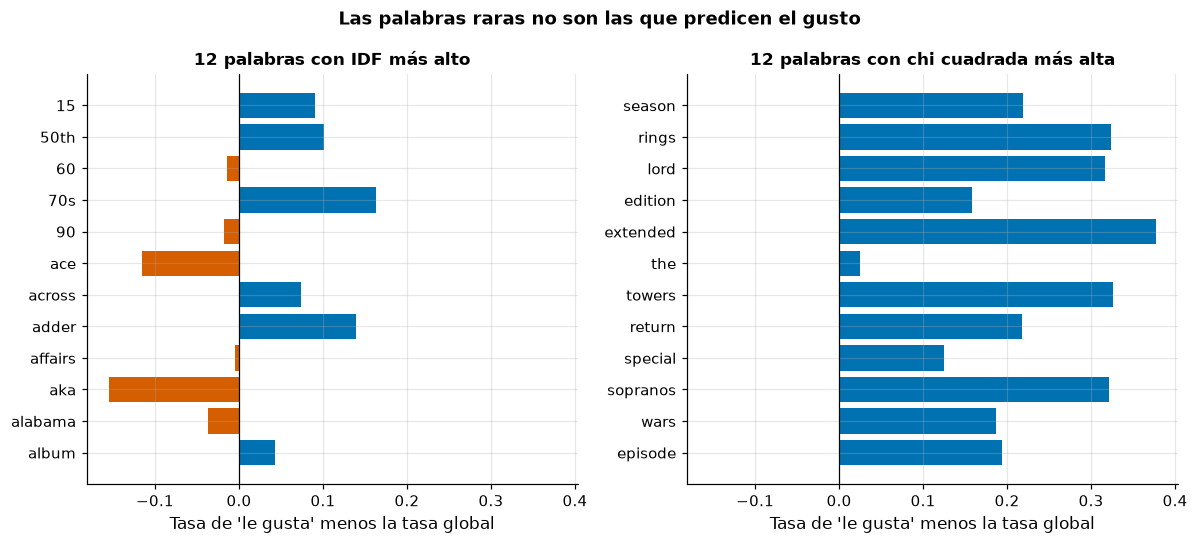

In [ ]:
top_idf = terminos.nlargest(12, "idf").iloc[::-1]
top_chi2 = terminos.nlargest(12, "chi2").iloc[::-1]

fig, ejes = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
for ax, tabla, titulo in [(ejes[0], top_idf, "12 palabras con IDF más alto"),
                          (ejes[1], top_chi2, "12 palabras con chi cuadrada más alta")]:
    diferencia = tabla["tasa_gusta"] - tasa_global
    ax.barh(tabla["termino"], diferencia,
            color=np.where(diferencia > 0, COLOR_PRINCIPAL, COLOR_RESALTE))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Tasa de 'le gusta' menos la tasa global")
fig.suptitle("Las palabras raras no son las que predicen el gusto", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "04_idf_vs_chi2")
plt.show()

A la izquierda están las 12 palabras con IDF más alto. Todas empatan en IDF, pues aparecen en exactamente 5 películas, el mínimo que pusimos, así que el orden es alfabético. Su efecto sobre el gusto va en ambas direcciones y es pequeño ("aka" -0.15, "70s" +0.16). A la derecha, las 12 con chi cuadrada más alta tienen todas un efecto positivo grande (hasta +0.38 para "extended").

**Decisión.** Si quisiéramos un modelo de contenido más compacto, convendría elegir los términos por chi cuadrada y no por IDF. La rareza de una palabra no dice nada de si gusta.

In [ ]:
gusta_A = probe_A["ratings"] >= 4
auc_global = pd.DataFrame({
    "modelo": ["B4", "B4 + edad", "kNN por título"],
    "AUC": [roc_auc_score(gusta_A, prediccion_b4(probe_A)), roc_auc_score(gusta_A, pred_edad_A),
            roc_auc_score(gusta_A, pred_knn_A)],
    "precision": [precision_score(gusta_A, p >= 3.5) for p in (prediccion_b4(probe_A), pred_edad_A, pred_knn_A)],
    "recall": [recall_score(gusta_A, p >= 3.5) for p in (prediccion_b4(probe_A), pred_edad_A, pred_knn_A)],
    "RMSE": [rmse_b4, rmse_edad, rmse_knn],
})
auc_global.round(4)

,modelo,AUC,precision,recall,RMSE
0,B4,0.7536,0.7391,0.7721,0.9838
1,B4 + edad,0.7539,0.7399,0.7704,0.9835
2,kNN por título,0.7579,0.7405,0.7753,0.9769


Por último comparamos los modelos de contenido sobre todo probe_A. El kNN por título tiene el mejor AUC (0.7579 contra 0.7536 de B4) y el mejor RMSE (0.9769). El efecto de la edad casi no cambia nada.

In [ ]:
pd.DataFrame({"C_edad": pred_edad_A.astype(np.float32), "C_knn_titulo": pred_knn_A.astype(np.float32)}).to_parquet(
    ARTEFACTOS / "predicciones" / "contenido_probe_A.parquet", index=False)
pd.DataFrame({"C_edad": prediccion_edad(probe_B).astype(np.float32), "C_knn_titulo": pred_knn_B.astype(np.float32)}).to_parquet(
    ARTEFACTOS / "predicciones" / "contenido_probe_B.parquet", index=False)
np.savez(ARTEFACTOS / "modelos" / "vecinos_titulo.npz", vecinos=MEJOR[0], similitud=MEJOR[1],
         efecto_edad=efecto_edad, k=K_TITULO, regularizacion=REG_TITULO)
print("Guardado: predicciones de contenido y vecinos por título")

Guardado: predicciones de contenido y vecinos por título


Guardamos las predicciones de los dos modelos de contenido (B4 + edad y kNN por título) para probe_A y probe_B, junto con los vecinos por título. La Etapa 6 los usa en el sistema híbrido.

### Resumen de la Etapa 4

- **Dónde ayuda el contenido.** El kNN por título baja el RMSE de B4 de 0.9838 a 0.9769. Toda la mejora sale del 19.4% de las filas donde el usuario ya calificó títulos parecidos, típicamente otras temporadas de una serie o partes de una saga. Ayuda más en películas de nicho y medianas (mejora de 0.0118 entre 500 y 2,000 ratings) que en las muy populares (0.0041).
- **Dónde no ayuda.** Para el 80.6% de las filas no hay vecinos de título, y la similitud de títulos confunde cosas sin relación ("Sorcerer" con Harry Potter, "The Ring" con El Señor de los Anillos). El año y la edad tienen un efecto real en películas viejas (hasta +0.1 estrellas), pero casi no cambian el RMSE (0.0004), porque son pocos ratings.
- **Modelos por usuario.** Ridge y Naive Bayes sobre títulos superan al azar (AUC 0.704 y 0.662) pero quedan por debajo de B4 (0.767). Su ventaja es que se pueden explicar.
- **Selección de términos.** Chi cuadrada encuentra términos realmente predictivos ("season", "extended", "rings"), en cambio un IDF alto solo señala términos raros.
- **Límite.** Con solo título y año, el contenido es un complemento y no un sustituto del filtrado colaborativo.

**Siguiente etapa.** Etapa 5, filtrado colaborativo con kNN, SVD, ALS, NMF, SVD++ y timeSVD++.

## Etapa 5. Filtrado colaborativo

El filtrado colaborativo no mira el contenido de las películas. Aprende solo de los patrones de ratings, con la idea de que si dos usuarios coincidieron en el pasado es probable que coincidan en el futuro. Es la familia de modelos que ganó el Netflix Prize.

En este notebook entrenamos sobre los 99 millones de ratings de train y comparamos, siempre en probe_A, los siguientes modelos.
1. **kNN ítem-ítem.** Predice con las películas parecidas que el usuario ya calificó.
2. **SVD estilo Funk.** Factoriza la matriz de ratings con descenso de gradiente estocástico (SGD).
3. **ALS.** La misma factorización, pero resolviendo mínimos cuadrados alternados.
4. **NMF.** Factorización con factores no negativos, más fácil de interpretar.
5. **SVD++.** SVD que además usa qué películas calificó cada usuario, sin importar la calificación.
6. **timeSVD++ simplificado.** SVD++ montado sobre el baseline temporal B7 de la Etapa 3.

Para cada modelo mostramos curvas de aprendizaje y, en la factorización, un mapa de los factores latentes.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.datos import (leer_train, leer_conjunto, cargar_csr, construir_csr_pelicula,
                       construir_implicito, guardar_csr, N_USUARIOS, N_PELICULAS)
from src.baselines import (sesgos_b4, lambdas_b4_desde_experimentos, SesgosTemporales,
                           periodo_del_dia, calcular_dev)
from src.metricas import rmse, registrar_experimento
from src import vecinos
from src.factorizacion import Factorizacion, ALS
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                                 COLOR_RESALTE, COLOR_CINEMATCH, COLOR_GANADOR, COLORES,
                                 RMSE_CINEMATCH_PROBE, RMSE_GANADOR_TEST)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
PREDICCIONES = ARTEFACTOS / "predicciones"
MODELOS = ARTEFACTOS / "modelos"
aplicar_estilo()

Las funciones pesadas están en `src/`. `factorizacion.py` tiene SVD, SVD++, NMF y ALS escritos con numba, que compila Python a código de máquina, y `vecinos.py` tiene el kNN. Elegimos numba en lugar de `surprise` porque `surprise` recorre los ratings en Python puro y tardaría horas por época con 99 millones de ratings, en cambio nuestras épocas tardan entre 13 y 23 segundos.

In [ ]:
train = leer_train()
probe_A = leer_conjunto("probe_A")
probe_B = leer_conjunto("probe_B")
qualifying = leer_conjunto("qualifying")
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx").reset_index(drop=True)
N_TRAIN = len(train["ratings"])

csr_usuario = cargar_csr("csr_usuario")
csr_pelicula = construir_csr_pelicula(train)
implicito = construir_implicito([train, probe_A, probe_B, qualifying], semilla=SEMILLA)
guardar_csr("implicito", implicito)

LAMBDA_I, LAMBDA_U = lambdas_b4_desde_experimentos(RAIZ / "experimentos.csv")
mu, b_i, b_u = sesgos_b4(train, N_USUARIOS, N_PELICULAS, LAMBDA_I, LAMBDA_U)
n_por_pelicula = np.bincount(train["peliculas"], minlength=N_PELICULAS)

n_implicito = np.diff(implicito["inicio"])
print(f"N(u): {len(implicito['peliculas']):,} pares, en promedio {n_implicito.mean():.0f} películas por usuario")
print(f"Pares implícitos que no están en train: {len(implicito['peliculas']) - N_TRAIN:,}")

N(u): 103,297,638 pares, en promedio 215 películas por usuario
Pares implícitos que no están en train: 4,225,526


Cargamos train agrupado por usuario y por película (formato CSR, explicado en `src/datos.py`) y los sesgos de B4.

El conjunto implícito N(u) junta, para cada usuario, todas las películas que calificó en train, probe y qualifying. Son 103,297,638 pares, unas 215 películas por usuario, y 4,225,526 de ellos no están en train. Usar estos pares **no es fuga de información**, pues solo dicen QUÉ película calificó el usuario y CUÁNDO, nunca CUÁNTO. Netflix publicó esta información junto con qualifying y los ganadores la usaron. En un sistema real equivale a saber qué películas rentó alguien aunque todavía no las califique. Que el usuario haya elegido una película ya dice algo de sus gustos.

In [ ]:
resultados = []


def evaluar(nombre, descripcion, pred_A, pred_B, hiperparametros, segundos, notas=""):
    """Registra la corrida, guarda las predicciones en disco y muestra el RMSE en probe_A."""
    error = rmse(probe_A["ratings"], pred_A)
    registrar_experimento(nombre, hiperparametros, N_TRAIN, error, segundos, notas)
    pd.DataFrame({nombre: np.clip(pred_A, 1, 5).astype(np.float32)}).to_parquet(PREDICCIONES / f"{nombre}_probe_A.parquet")
    pd.DataFrame({nombre: np.clip(pred_B, 1, 5).astype(np.float32)}).to_parquet(PREDICCIONES / f"{nombre}_probe_B.parquet")
    resultados.append({"modelo": nombre, "descripcion": descripcion, "rmse_probe_A": error,
                       "minutos": segundos / 60})
    print(f"{nombre} ({descripcion}): RMSE probe_A = {error:.4f} en {segundos / 60:.1f} min")
    return error

La función `evaluar` hace tres cosas cada vez que terminamos un modelo. Mide el RMSE en probe_A, registra la corrida en `experimentos.csv` y guarda las predicciones de probe_A y probe_B en `artifacts/predicciones/`. Las de probe_B se guardan sin mirarlas, ya que solo se usan en la Etapa 7.

### 1. kNN ítem-ítem con similitud ajustada por sesgos

Para predecir el rating del usuario u a la película i, el kNN busca las k películas más parecidas a i que u ya calificó y promedia lo que u opinó de ellas. Dos detalles hacen que funcione bien.
- **Similitud sobre residuos.** No comparamos ratings crudos sino r - (μ + b_u + b_i), lo que queda después de quitar los sesgos de B4. Así dos películas no parecen similares solo porque ambas son buenas.
- **Shrinkage.** Una similitud calculada con 3 usuarios en común es poco confiable. La multiplicamos por n / (n + 100), donde n es el número de usuarios en común, y así las similitudes con poca evidencia se encogen hacia cero.

In [ ]:
inicio = time.perf_counter()
normas = vecinos.normas_por_pelicula(csr_pelicula["inicio"], csr_pelicula["usuarios"], csr_pelicula["ratings"],
                                     vecinos.MODO_RESIDUO, mu, b_u, b_i)
SHRINKAGE = 100
K_MAXIMO = 50
sin_extra = np.full((N_PELICULAS, 1), -1, np.int32), np.zeros((N_PELICULAS, 1), np.float32)
vecinos_cf, similitud_cf = vecinos.similitudes_top_k(
    csr_pelicula["inicio"], csr_pelicula["usuarios"], csr_pelicula["ratings"],
    csr_usuario["inicio"], csr_usuario["peliculas"], csr_usuario["ratings"],
    vecinos.MODO_RESIDUO, mu, b_u, b_i, normas, SHRINKAGE, K_MAXIMO, sin_extra[0], sin_extra[1], 0.0)
segundos_similitud = time.perf_counter() - inicio
print(f"Similitudes calculadas en {segundos_similitud / 60:.1f} min")
print(f"Similitud media del vecino 1: {similitud_cf[:, 0].mean():.3f}, del vecino 50: {similitud_cf[:, -1].mean():.3f}")

Similitudes calculadas en 0.8 min
Similitud media del vecino 1: 0.103, del vecino 50: 0.021


Calcular la similitud entre las 17,770 películas (unos 158 millones de pares) tomó menos de un minuto. Guardamos solo los 50 vecinos más parecidos de cada película. Las similitudes son bajas en valor absoluto (0.103 en promedio para el vecino más cercano y 0.021 para el vecino 50) debido al shrinkage y a que los residuos tienen mucho ruido.

In [ ]:
def mostrar_vecinos(texto, n=6):
    candidatas = peliculas[peliculas["titulo"].str.contains(texto, case=False, regex=False)]
    i = int(candidatas.loc[candidatas["movie_idx"].map(lambda m: n_por_pelicula[m]).idxmax(), "movie_idx"])
    print(f"\n=== {peliculas.loc[i, 'titulo']}")
    for j, s in zip(vecinos_cf[i, :n], similitud_cf[i, :n]):
        print(f"   {s:.3f}  {peliculas.loc[j, 'titulo']}")


for texto in ["Harry Potter and the Sorcerer", "Pulp Fiction", "Finding Nemo", "Friends: Season 1"]:
    mostrar_vecinos(texto)


=== Harry Potter and the Sorcerer's Stone
   0.477  Harry Potter and the Chamber of Secrets
   0.259  Harry Potter and the Prisoner of Azkaban
   0.089  Lord of the Rings: The Fellowship of the Ring
   0.087  Star Wars: Episode I: The Phantom Menace
   0.085  Pirates of the Caribbean: The Curse of the Black Pearl
   0.082  Star Wars: Episode II: Attack of the Clones

=== Pulp Fiction
   0.214  American Beauty
   0.214  Reservoir Dogs
   0.186  Fight Club
   0.176  Kill Bill: Vol. 1
   0.159  Apocalypse Now
   0.156  The Royal Tenenbaums

=== Finding Nemo (Widescreen)
   0.231  Monsters, Inc.
   0.147  Shrek (Full-screen)
   0.132  The Incredibles
   0.125  Toy Story
   0.124  A Bug's Life
   0.123  Shrek 2

=== Friends: Season 1
   0.443  The Best of Friends: Season 2
   0.438  Friends: Season 3
   0.400  Friends: Season 4
   0.371  The Best of Friends: Season 1
   0.346  The Best of Friends: Vol. 1
   0.345  The Best of Friends: Season 3


Los vecinos tienen mucho sentido, aunque el modelo nunca vio un título ni un género.
- **Harry Potter 1** tiene como vecinos a sus secuelas (0.477 y 0.259) y después a otras sagas de fantasía y aventura como El Señor de los Anillos, Star Wars y Piratas del Caribe.
- **Pulp Fiction** queda junto a Reservoir Dogs, Kill Bill y Fight Club, es decir cine de autor de los noventa con violencia estilizada.
- **Finding Nemo** se agrupa con las películas animadas de Pixar y DreamWorks.
- **Friends** encuentra sus otras temporadas.

Esta es la gran diferencia con el contenido de la Etapa 4. Ahí "Sorcerer" quedaba junto a Harry Potter por una palabra del título, aquí los vecinos salen del comportamiento de millones de usuarios.

In [ ]:
busqueda_knn = []
for k in [10, 20, 50]:
    for regularizacion in [0.05, 0.2, 1.0]:
        inicio = time.perf_counter()
        pred, _ = vecinos.predecir(probe_A, csr_usuario, vecinos_cf[:, :k].copy(), similitud_cf[:, :k].copy(),
                                   mu, b_u, b_i, regularizacion)
        error = rmse(probe_A["ratings"], pred)
        hiper = {"k": k, "regularizacion": regularizacion, "shrinkage": SHRINKAGE}
        registrar_experimento("CF_knn_busqueda", hiper, N_TRAIN, error, time.perf_counter() - inicio,
                              "kNN ítem-ítem sobre residuos de B4")
        busqueda_knn.append({**hiper, "rmse_probe_A": error})
busqueda_knn = pd.DataFrame(busqueda_knn)
mejor_knn = busqueda_knn.loc[busqueda_knn["rmse_probe_A"].idxmin()]
K_CF, REG_CF = int(mejor_knn["k"]), float(mejor_knn["regularizacion"])
busqueda_knn.pivot(index="k", columns="regularizacion", values="rmse_probe_A").round(4)

regularizacion,0.05,0.20,1.00
k,,,
10,0.9685,0.9477,0.9571
20,0.9575,0.9407,0.9519
50,0.9448,0.9343,0.9469


Probamos k (número de vecinos) y la regularización, que es un término en el denominador del promedio ponderado. Con poca evidencia (pocos vecinos calificados o similitudes bajas) la regularización empuja la predicción hacia el baseline B4.

Más vecinos siempre ayuda en este rango (de 0.9477 con k = 10 a 0.9343 con k = 50, usando regularización 0.2). La regularización tiene un punto óptimo. Con 0.05 confía demasiado en pocos vecinos y con 1.0 se queda demasiado cerca de B4.

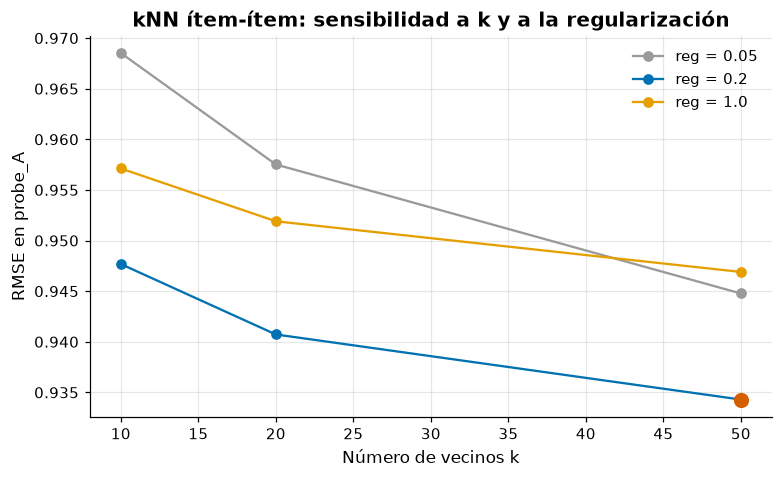

CF_knn (kNN ítem-ítem): RMSE probe_A = 0.9343 en 0.8 min


In [ ]:
fig, ax = plt.subplots()
for regularizacion, color in zip([0.05, 0.2, 1.0], [COLOR_SECUNDARIO, COLOR_PRINCIPAL, COLOR_CINEMATCH]):
    filas = busqueda_knn[busqueda_knn["regularizacion"] == regularizacion]
    ax.plot(filas["k"], filas["rmse_probe_A"], marker="o", color=color, label=f"reg = {regularizacion}")
ax.scatter([K_CF], [mejor_knn["rmse_probe_A"]], color=COLOR_RESALTE, s=80, zorder=3)
ax.set_xlabel("Número de vecinos k")
ax.set_ylabel("RMSE en probe_A")
ax.set_title("kNN ítem-ítem: sensibilidad a k y a la regularización")
ax.legend()
guardar_figura(fig, "05_knn_sensibilidad")
plt.show()

inicio = time.perf_counter()
pred_A, _ = vecinos.predecir(probe_A, csr_usuario, vecinos_cf[:, :K_CF].copy(), similitud_cf[:, :K_CF].copy(), mu, b_u, b_i, REG_CF)
pred_B, _ = vecinos.predecir(probe_B, csr_usuario, vecinos_cf[:, :K_CF].copy(), similitud_cf[:, :K_CF].copy(), mu, b_u, b_i, REG_CF)
evaluar("CF_knn", "kNN ítem-ítem", pred_A, pred_B, {"k": K_CF, "regularizacion": REG_CF, "shrinkage": SHRINKAGE},
        segundos_similitud + time.perf_counter() - inicio)
np.savez(MODELOS / "vecinos_cf.npz", vecinos=vecinos_cf, similitud=similitud_cf, k=K_CF, regularizacion=REG_CF)

El kNN final (k = 50, regularización 0.2) logra 0.9343 en probe_A, 0.0495 menos que B4 (0.9838) y mejor que Cinematch en probe (0.9474). Es un modelo fácil de explicar, porque cada predicción viene de películas concretas que el usuario calificó.

### 2. SVD estilo Funk

La factorización de matrices supone que cada película se puede describir con k números (sus **factores latentes**) y cada usuario con otros k números que dicen cuánto le gusta cada factor. La predicción es

r̂_ui = μ + b_u + b_i + q_i · p_u

donde q_i son los factores de la película y p_u los del usuario. Un factor puede terminar significando algo como "comedia contra drama" o "cine de arte contra taquillero", pero el modelo lo descubre solo.

Simon Funk popularizó en 2006 entrenar esto con SGD. Por cada rating se calcula el error y se mueven un poco p_u, q_i y los sesgos en la dirección que lo reduce. La regularización castiga factores grandes para no sobreajustar a usuarios con pocos ratings. La tasa de aprendizaje se multiplica por 0.9 en cada época para que el modelo se asiente.

In [ ]:
N_EPOCAS = 15
HIPER_SVD = {"n_factores": 50, "lr": 0.007, "reg": 0.02, "lr_sesgo": 0.007, "reg_sesgo": 0.005, "decaimiento": 0.9}

inicio = time.perf_counter()
svd = Factorizacion(N_USUARIOS, N_PELICULAS, **HIPER_SVD, semilla=SEMILLA)
historial_svd = svd.ajustar(csr_usuario, implicito, mu, evaluacion=(probe_A, None), n_epocas=N_EPOCAS)
segundos = time.perf_counter() - inicio
evaluar("CF_svd", "SVD estilo Funk", svd.predecir(probe_A, implicito), svd.predecir(probe_B, implicito),
        HIPER_SVD, segundos, f"{N_EPOCAS} épocas")

  época  1: train 0.9281, probe_A 0.9886 (16 s)


  época  2: train 0.8901, probe_A 0.9688 (14 s)


  época  3: train 0.8744, probe_A 0.9583 (14 s)


  época  4: train 0.8626, probe_A 0.9512 (14 s)


  época  5: train 0.8524, probe_A 0.9454 (14 s)


  época  6: train 0.8446, probe_A 0.9416 (14 s)


... (7 outputs left out)

  época 14: train 0.8135, probe_A 0.9268 (13 s)


  época 15: train 0.8114, probe_A 0.9259 (13 s)


CF_svd (SVD estilo Funk): RMSE probe_A = 0.9259 en 3.5 min


0.9259411122916832

Con 50 factores y regularización 0.02, el SVD llega a 0.9259 en probe_A tras 15 épocas, unos 3.5 minutos. Es la primera vez que bajamos de 0.93.

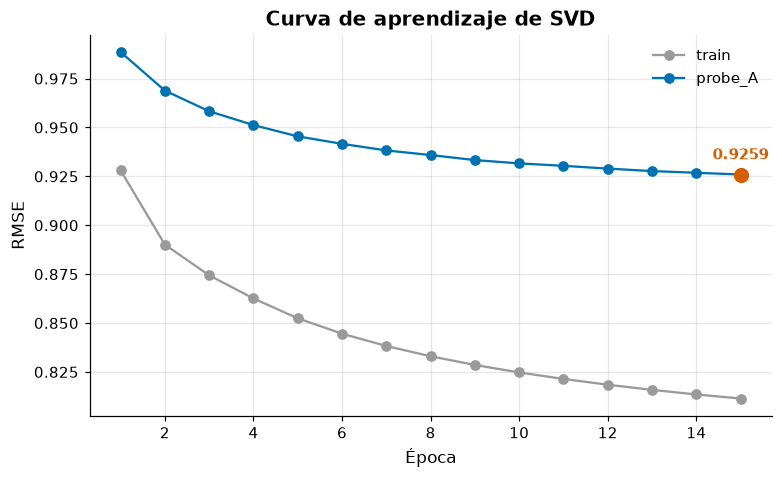

In [ ]:
def curva(historial, nombre, archivo):
    fig, ax = plt.subplots()
    ax.plot(historial["epoca"], historial["rmse_train"], marker="o", color=COLOR_SECUNDARIO, label="train")
    ax.plot(historial["epoca"], historial["rmse_probe_A"], marker="o", color=COLOR_PRINCIPAL, label="probe_A")
    mejor = historial["rmse_probe_A"].idxmin()
    ax.scatter([historial.loc[mejor, "epoca"]], [historial.loc[mejor, "rmse_probe_A"]], color=COLOR_RESALTE, s=80, zorder=3)
    ax.annotate(f"{historial.loc[mejor, 'rmse_probe_A']:.4f}", (historial.loc[mejor, "epoca"], historial.loc[mejor, "rmse_probe_A"]),
                xytext=(0, 10), textcoords="offset points", ha="center", color=COLOR_RESALTE, fontweight="bold")
    ax.set_xlabel("Época")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Curva de aprendizaje de {nombre}")
    ax.legend()
    guardar_figura(fig, archivo)
    plt.show()


curva(historial_svd, "SVD", "05_curva_svd")

La curva de aprendizaje muestra que el RMSE de train (0.8114 al final) baja mucho más que el de probe_A (0.9259). La brecha de 0.11 indica que el modelo memoriza parte del ruido de train. Aun así probe_A sigue bajando en cada época, así que no hay sobreajuste dañino todavía, pero cada época aporta menos (0.0009 entre las épocas 14 y 15).

In [ ]:
N_EPOCAS_SENSIBILIDAD = 8
sensibilidad = []
referencia = historial_svd.loc[N_EPOCAS_SENSIBILIDAD - 1, "rmse_probe_A"]
sensibilidad.append({"parametro": "n_factores", "valor": 50, "rmse_probe_A": referencia})
sensibilidad.append({"parametro": "reg", "valor": 0.02, "rmse_probe_A": referencia})

for parametro, valores in [("n_factores", [10, 100]), ("reg", [0.005, 0.05])]:
    for valor in valores:
        hiper = {**HIPER_SVD, parametro: valor}
        inicio = time.perf_counter()
        modelo = Factorizacion(N_USUARIOS, N_PELICULAS, **hiper, semilla=SEMILLA)
        historial = modelo.ajustar(csr_usuario, implicito, mu, evaluacion=(probe_A, None),
                                   n_epocas=N_EPOCAS_SENSIBILIDAD, verbose=False)
        error = historial["rmse_probe_A"].iloc[-1]
        registrar_experimento("CF_svd_sensibilidad", hiper, N_TRAIN, error, time.perf_counter() - inicio,
                              f"{N_EPOCAS_SENSIBILIDAD} épocas")
        sensibilidad.append({"parametro": parametro, "valor": valor, "rmse_probe_A": error})
        print(f"{parametro} = {valor}: RMSE probe_A {error:.4f}")
        del modelo

sensibilidad = pd.DataFrame(sensibilidad).sort_values(["parametro", "valor"])
sensibilidad

n_factores = 10: RMSE probe_A 0.9374


n_factores = 100: RMSE probe_A 0.9354


reg = 0.005: RMSE probe_A 0.9143


reg = 0.05: RMSE probe_A 0.9583


,parametro,valor,rmse_probe_A
2,n_factores,10.000,0.937438
0,n_factores,50.000,0.935903
3,n_factores,100.000,0.935445
4,reg,0.005,0.914341
1,reg,0.020,0.935903
5,reg,0.050,0.958276


Para medir la sensibilidad cambiamos un hiperparámetro a la vez y entrenamos 8 épocas, que es suficiente para comparar y cuesta la mitad.

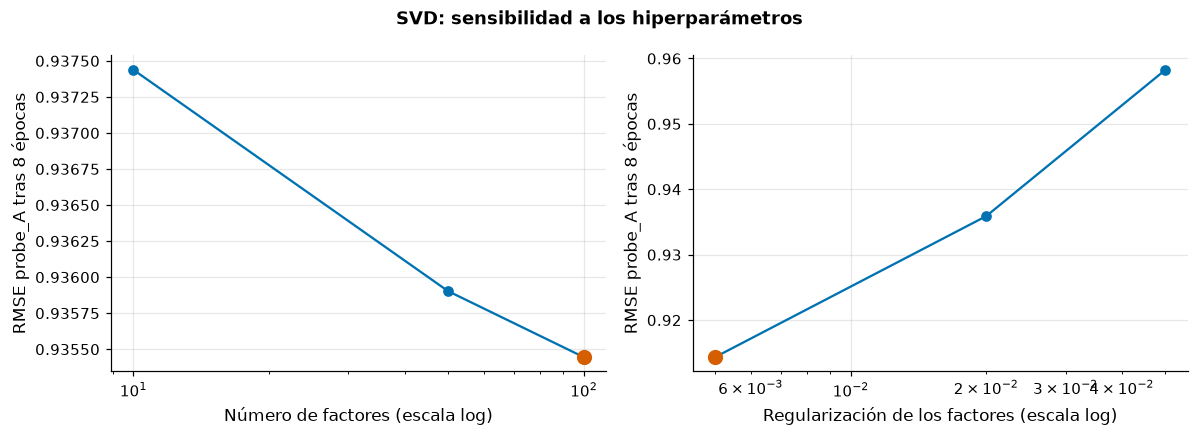

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, parametro, etiqueta in [(ejes[0], "n_factores", "Número de factores"),
                                (ejes[1], "reg", "Regularización de los factores")]:
    filas = sensibilidad[sensibilidad["parametro"] == parametro]
    ax.plot(filas["valor"], filas["rmse_probe_A"], marker="o", color=COLOR_PRINCIPAL)
    mejor = filas.loc[filas["rmse_probe_A"].idxmin()]
    ax.scatter([mejor["valor"]], [mejor["rmse_probe_A"]], color=COLOR_RESALTE, s=80, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel(f"{etiqueta} (escala log)")
    ax.set_ylabel(f"RMSE probe_A tras {N_EPOCAS_SENSIBILIDAD} épocas")
fig.suptitle("SVD: sensibilidad a los hiperparámetros", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "05_svd_sensibilidad")
plt.show()

- **Número de factores.** Pasar de 10 a 100 factores mejora apenas 0.002 (de 0.9374 a 0.9354). Con 8 épocas y regularización 0.02 los factores extra casi no se usan.
- **Regularización.** Es el hiperparámetro que más importa. Bajarla de 0.02 a 0.005 mejora 0.0216 (de 0.9359 a 0.9143), en cambio subirla a 0.05 empeora 0.022.

Esto nos dice que 0.02 regulariza de más. Lo tomamos en cuenta al final del proyecto, donde reentrenamos SVD++ y timeSVD++ con menos regularización y más factores (ver la sección siguiente).

### 3. ALS (mínimos cuadrados alternados)

ALS resuelve la misma factorización de otra forma. Si fijamos los factores de las películas, encontrar los factores de cada usuario es una regresión ridge pequeña con solución exacta. Luego se fijan los de los usuarios y se resuelven los de las películas, y así se alterna. Aquí factorizamos los residuos de B4 (los sesgos quedan fijos) y la regularización crece con el número de ratings de cada fila, como en la versión ALS-WR de Zhou et al. (2008).

La ventaja de ALS es que cada paso es paralelo y no necesita tasa de aprendizaje. La desventaja es que cada iteración resuelve 498 mil sistemas lineales de 50 × 50, y eso tarda unos 5 minutos.

  iteración 1: probe_A 1.0095 (314 s)


  iteración 2: probe_A 0.9817 (312 s)


  iteración 3: probe_A 0.9656 (306 s)


  iteración 4: probe_A 0.9560 (309 s)


  iteración 5: probe_A 0.9501 (315 s)


  iteración 6: probe_A 0.9468 (317 s)


... (3 outputs left out)

  iteración 4: probe_A 0.9417 (299 s)


  iteración 5: probe_A 0.9394 (311 s)


  iteración 6: probe_A 0.9383 (306 s)


CF_als (ALS sobre residuos de B4): RMSE probe_A = 0.9383 en 30.5 min


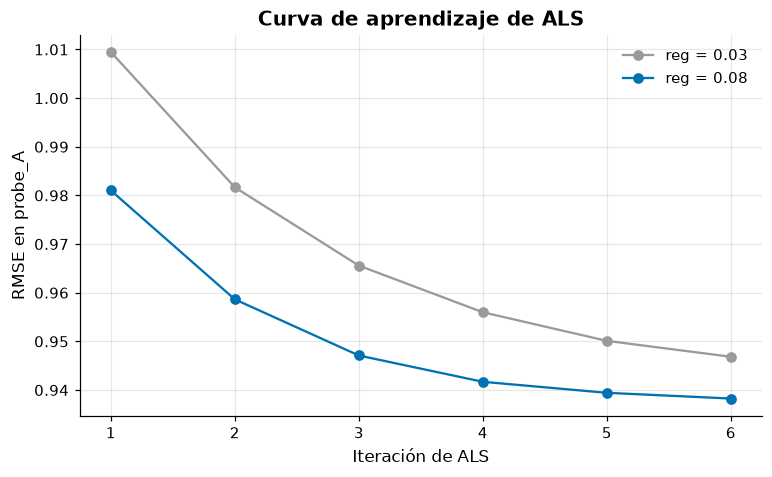

In [ ]:
historiales_als = {}
mejor_als = None
for reg in [0.03, 0.08]:
    inicio = time.perf_counter()
    als = ALS(N_USUARIOS, N_PELICULAS, n_factores=50, reg=reg, semilla=SEMILLA)
    historial = als.ajustar(csr_usuario, csr_pelicula, mu, b_u, b_i, evaluacion=probe_A, n_iteraciones=6)
    segundos = time.perf_counter() - inicio
    error = historial["rmse_probe_A"].iloc[-1]
    registrar_experimento("CF_als_busqueda", {"n_factores": 50, "reg": reg}, N_TRAIN, error, segundos, "6 iteraciones")
    historiales_als[reg] = historial
    if mejor_als is None or error < mejor_als[0]:
        mejor_als = (error, reg, segundos, als.predecir(probe_A), als.predecir(probe_B))
    del als

_, REG_ALS, segundos, pred_A, pred_B = mejor_als
evaluar("CF_als", "ALS sobre residuos de B4", pred_A, pred_B, {"n_factores": 50, "reg": REG_ALS}, segundos)

fig, ax = plt.subplots()
for (reg, historial), color in zip(historiales_als.items(), [COLOR_SECUNDARIO, COLOR_PRINCIPAL]):
    ax.plot(historial["iteracion"], historial["rmse_probe_A"], marker="o", color=color, label=f"reg = {reg}")
ax.set_xlabel("Iteración de ALS")
ax.set_ylabel("RMSE en probe_A")
ax.set_title("Curva de aprendizaje de ALS")
ax.legend()
guardar_figura(fig, "05_curva_als")
plt.show()

Con regularización 0.08, ALS llega a 0.9383 tras 6 iteraciones, mejor que con 0.03 (0.9468). La curva todavía baja, pero cada iteración cuesta 5 minutos y la mejora entre la quinta y la sexta ya es de solo 0.001. Queda por detrás del SVD con SGD (0.9259), con una diferencia de 0.012, y tarda 9 veces más (30 minutos contra 3.5). En este problema SGD es la mejor opción.

### 4. NMF (factorización no negativa)

NMF obliga a que todos los factores sean mayores o iguales a cero. La idea es que cada película se describa como una suma de "ingredientes" en lugar de una mezcla de positivos y negativos, lo que facilita interpretarlos. Para que la comparación sea limpia no usamos sesgos, pues el modelo tiene que explicar todo el rating con los factores.

  época  1: train 0.9537, probe_A 1.0130 (14 s)


  época  2: train 0.9267, probe_A 0.9983 (13 s)


  época  3: train 0.9138, probe_A 0.9898 (13 s)


  época  4: train 0.9018, probe_A 0.9829 (14 s)


  época  5: train 0.8942, probe_A 0.9781 (13 s)


  época  6: train 0.8888, probe_A 0.9743 (13 s)


... (6 outputs left out)

  época 13: train 0.8649, probe_A 0.9625 (13 s)


  época 14: train 0.8628, probe_A 0.9617 (13 s)


  época 15: train 0.8609, probe_A 0.9607 (13 s)


CF_nmf (NMF): RMSE probe_A = 0.9607 en 3.4 min


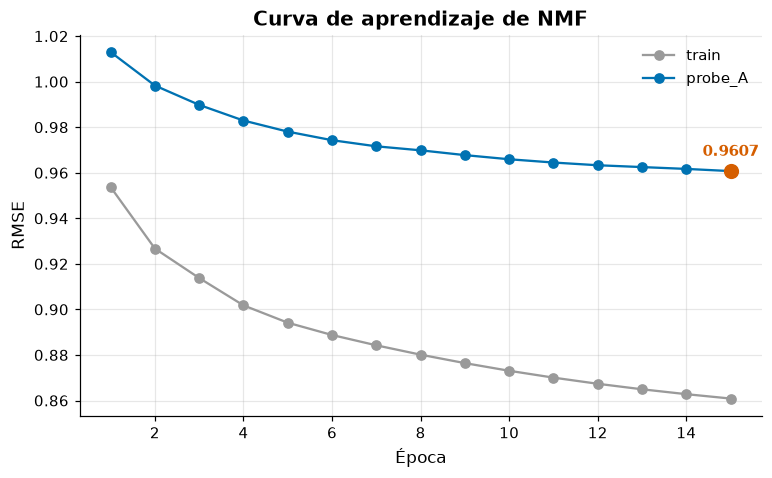

Fracción de factores exactamente en cero: P 0.00, Q 0.00


In [ ]:
HIPER_NMF = {"n_factores": 50, "lr": 0.003, "reg": 0.02, "decaimiento": 0.9}
inicio = time.perf_counter()
nmf = Factorizacion(N_USUARIOS, N_PELICULAS, **HIPER_NMF, usar_sesgos=False, no_negativo=True, semilla=SEMILLA)
historial_nmf = nmf.ajustar(csr_usuario, implicito, 0.0, evaluacion=(probe_A, None), n_epocas=N_EPOCAS)
evaluar("CF_nmf", "NMF", nmf.predecir(probe_A, implicito), nmf.predecir(probe_B, implicito),
        HIPER_NMF, time.perf_counter() - inicio, f"{N_EPOCAS} épocas, sin sesgos, factores >= 0")
curva(historial_nmf, "NMF", "05_curva_nmf")
print(f"Fracción de factores exactamente en cero: P {np.mean(nmf.P == 0):.2f}, Q {np.mean(nmf.Q == 0):.2f}")

NMF llega a 0.9607, el peor de los modelos colaborativos y apenas mejor que B7 (0.9650). La restricción de no negatividad y la falta de sesgos le quitan flexibilidad. Por ejemplo, para expresar que una película es mala en general necesita factores pequeños en todo, mientras que SVD lo resuelve con un b_i negativo.

In [ ]:
def titulos_extremos(Q, factor, n=5):
    populares = np.flatnonzero(n_por_pelicula >= 5_000)
    valores = Q[populares, factor]
    orden = np.argsort(valores)
    return (peliculas.loc[populares[orden[-n:][::-1]], "titulo"].tolist(),
            peliculas.loc[populares[orden[:n]], "titulo"].tolist())


for factor in range(3):
    altos, _ = titulos_extremos(nmf.Q, factor)
    print(f"NMF factor {factor}: {' | '.join(altos)}")
del nmf

NMF factor 0: Vanilla Sky | What Dreams May Come | Permanent Midnight | The Boondock Saints | Six Feet Under: Season 4
NMF factor 1: Stargate SG-1: Season 3 | Stargate SG-1: Season 6 | Stargate SG-1: Season 5 | Highlander 4: Endgame | Stargate SG-1: Season 4
NMF factor 2: Iron Jawed Angels | The United States of Leland | Dogma | P.S. | Dangerous Beauty


Las películas con mayor valor en cada factor muestran la interpretabilidad prometida, al menos en parte. El factor 1 agrupa casi solo temporadas de Stargate SG-1 junto con Highlander, es decir ciencia ficción de culto. El factor 0 mezcla dramas oscuros y existenciales (Vanilla Sky, What Dreams May Come, Six Feet Under). El factor 2 es más difícil de nombrar. Que los factores no siempre tengan un nombre claro es normal, ya que el modelo los elige para reducir el error y no para que los entendamos.

### 5. SVD++ (información implícita)

SVD++ agrega al usuario un término que depende solo de QUÉ películas calificó:

r̂_ui = μ + b_u + b_i + q_i · (p_u + |N(u)|^(-1/2) Σ_{j ∈ N(u)} y_j)

Cada película j tiene un vector y_j, y el usuario se describe también por la suma de los y_j de las películas que eligió ver. Esto ayuda sobre todo con usuarios que tienen pocos ratings en train pero muchas películas en probe y qualifying, ya que esas películas sí nos dicen algo de sus gustos aunque no conozcamos la calificación.

  época  1: train 0.8765, probe_A 0.9540 (23 s)


  época  2: train 0.8376, probe_A 0.9363 (23 s)


  época  3: train 0.8204, probe_A 0.9263 (23 s)


  época  4: train 0.8083, probe_A 0.9207 (23 s)


  época  5: train 0.7990, probe_A 0.9160 (23 s)


  época  6: train 0.7917, probe_A 0.9127 (23 s)


... (6 outputs left out)

  época 13: train 0.7645, probe_A 0.9034 (23 s)


  época 14: train 0.7624, probe_A 0.9028 (23 s)


  época 15: train 0.7606, probe_A 0.9023 (23 s)


CF_svdpp (SVD++): RMSE probe_A = 0.9023 en 6.3 min


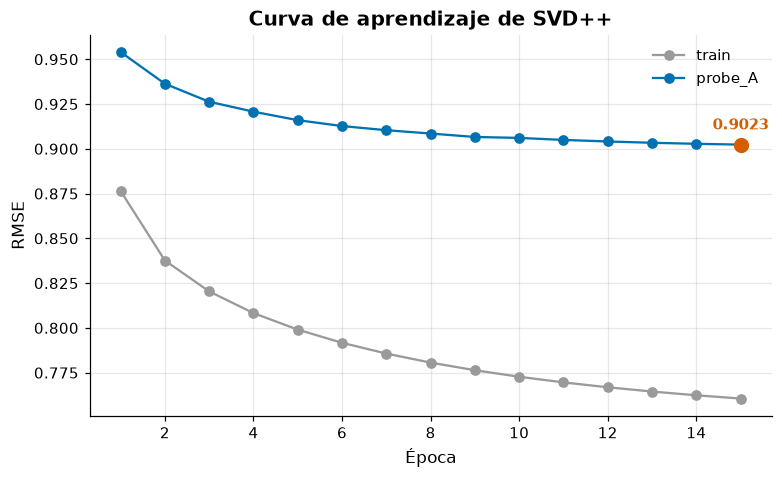

In [ ]:
HIPER_SVDPP = {"n_factores": 50, "lr": 0.007, "reg": 0.02, "lr_sesgo": 0.007, "reg_sesgo": 0.005, "decaimiento": 0.9}
inicio = time.perf_counter()
svdpp = Factorizacion(N_USUARIOS, N_PELICULAS, **HIPER_SVDPP, usar_implicito=True, semilla=SEMILLA)
historial_svdpp = svdpp.ajustar(csr_usuario, implicito, mu, evaluacion=(probe_A, None), n_epocas=N_EPOCAS)
evaluar("CF_svdpp", "SVD++", svdpp.predecir(probe_A, implicito), svdpp.predecir(probe_B, implicito),
        HIPER_SVDPP, time.perf_counter() - inicio, f"{N_EPOCAS} épocas, N(u) con train + probe + qualifying")
curva(historial_svdpp, "SVD++", "05_curva_svdpp")
del svdpp

SVD++ baja a 0.9023, una mejora de 0.0236 sobre SVD con los mismos hiperparámetros. Es el salto más grande entre modelos de factorización y confirma lo que encontraron los ganadores, pues saber qué calificó un usuario vale casi tanto como saber cuánto. El costo es que cada época tarda 23 segundos en lugar de 14.

### 6. timeSVD++ simplificado

El timeSVD++ completo de Koren modela que los sesgos y los factores cambian en el tiempo. Nuestra versión simplificada toma la parte temporal más rentable, que son los sesgos, y la resuelve con el baseline B7 de la Etapa 3. B7 ya incluye el sesgo de película por periodo, la deriva del sesgo del usuario y el sesgo de usuario por día. El modelo queda así

r̂_ui = B7(u, i, t) + b_u + b_i + q_i · (p_u + |N(u)|^(-1/2) Σ y_j)

Es decir, SVD++ aprende lo que B7 no explica. No modelamos factores que cambian con el tiempo (p_u(t)), lo que sería el siguiente paso.

In [ ]:
# Predicción de B7 (baseline temporal de la Etapa 3) para cada rating
with np.load(MODELOS / "baseline_B7.npz") as archivo:
    parametros_b7 = {clave: archivo[clave] for clave in archivo.files}
dia_medio_usuario = parametros_b7["dia_medio_usuario"]


def preparar_b7(datos, nombre):
    return {"usuarios": datos["usuarios"], "peliculas": datos["peliculas"],
            "periodos": periodo_del_dia(datos["dias"]),
            "devs": calcular_dev(datos["usuarios"], datos["dias"], dia_medio_usuario),
            "usuario_dia": np.load(ARTEFACTOS / f"usuario_dia_{nombre}.npy")}


b7 = SesgosTemporales(float(parametros_b7["mu"]), N_USUARIOS, N_PELICULAS, len(parametros_b7["b_ut"]), [], {})
for clave in ["b_u", "b_i", "b_ibin", "alpha", "b_ut"]:
    setattr(b7, clave, parametros_b7[clave])

base_train = b7.predecir(preparar_b7(train, "train"))[csr_usuario["fila_original"]].astype(np.float32)
base_A = b7.predecir(preparar_b7(probe_A, "probe_A")).astype(np.float32)
base_B = b7.predecir(preparar_b7(probe_B, "probe_B")).astype(np.float32)
print(f"B7 en probe_A: {rmse(probe_A['ratings'], base_A):.4f}")

B7 en probe_A: 0.9650


Reconstruimos las predicciones de B7 con los parámetros guardados en la Etapa 3 y verificamos que dan lo mismo en probe_A, 0.9650.

  época  1: train 0.8128, probe_A 0.9295 (23 s)


  época  2: train 0.7945, probe_A 0.9226 (23 s)


  época  3: train 0.7832, probe_A 0.9173 (23 s)


  época  4: train 0.7744, probe_A 0.9148 (23 s)


  época  5: train 0.7672, probe_A 0.9112 (23 s)


  época  6: train 0.7612, probe_A 0.9089 (23 s)


... (6 outputs left out)

  época 13: train 0.7379, probe_A 0.9013 (23 s)


  época 14: train 0.7361, probe_A 0.9007 (23 s)


  época 15: train 0.7345, probe_A 0.9003 (23 s)


CF_timesvdpp (timeSVD++ simplificado): RMSE probe_A = 0.9003 en 6.3 min


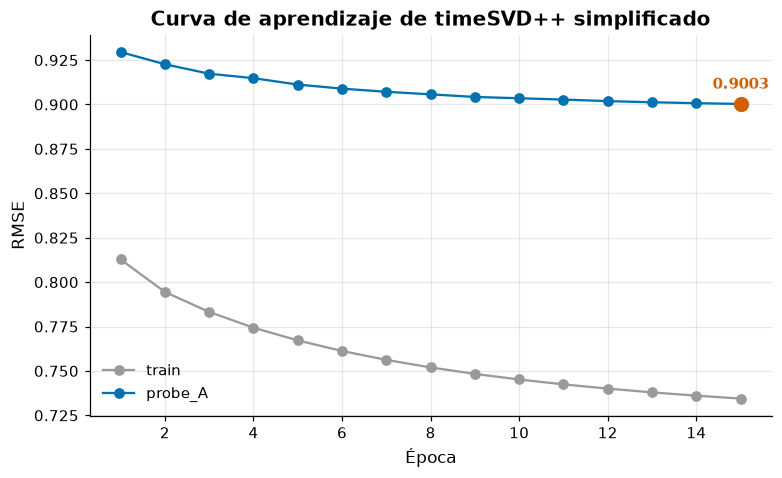

In [ ]:
HIPER_TSVDPP = {**HIPER_SVDPP, "reg_sesgo": 0.02}
inicio = time.perf_counter()
tsvdpp = Factorizacion(N_USUARIOS, N_PELICULAS, **HIPER_TSVDPP, usar_implicito=True, semilla=SEMILLA)
historial_tsvdpp = tsvdpp.ajustar(csr_usuario, implicito, mu, base_train=base_train,
                                  evaluacion=(probe_A, base_A), n_epocas=N_EPOCAS)
evaluar("CF_timesvdpp", "timeSVD++ simplificado", tsvdpp.predecir(probe_A, implicito, base_A),
        tsvdpp.predecir(probe_B, implicito, base_B), HIPER_TSVDPP, time.perf_counter() - inicio,
        f"{N_EPOCAS} épocas, SVD++ sobre la predicción de B7")
curva(historial_tsvdpp, "timeSVD++ simplificado", "05_curva_timesvdpp")

np.savez(MODELOS / "timesvdpp.npz", P=tsvdpp.P.astype(np.float32), Q=tsvdpp.Q.astype(np.float32),
         Y=tsvdpp.Y.astype(np.float32), b_u=tsvdpp.b_u, b_i=tsvdpp.b_i, mu=mu)
del base_train

timeSVD++ llega a 0.9003, el mejor modelo de esta etapa, aunque la mejora sobre SVD++ es pequeña (0.0020). La curva muestra por qué. Arranca mucho más abajo (0.9295 en la época 1 contra 0.9540 de SVD++) porque B7 ya resuelve los sesgos, pero las dos curvas convergen. Con 15 épocas, SVD++ termina aprendiendo con sus propios sesgos buena parte de lo que B7 le regala. La parte temporal que queda es el sesgo por día, que SVD++ no puede capturar.

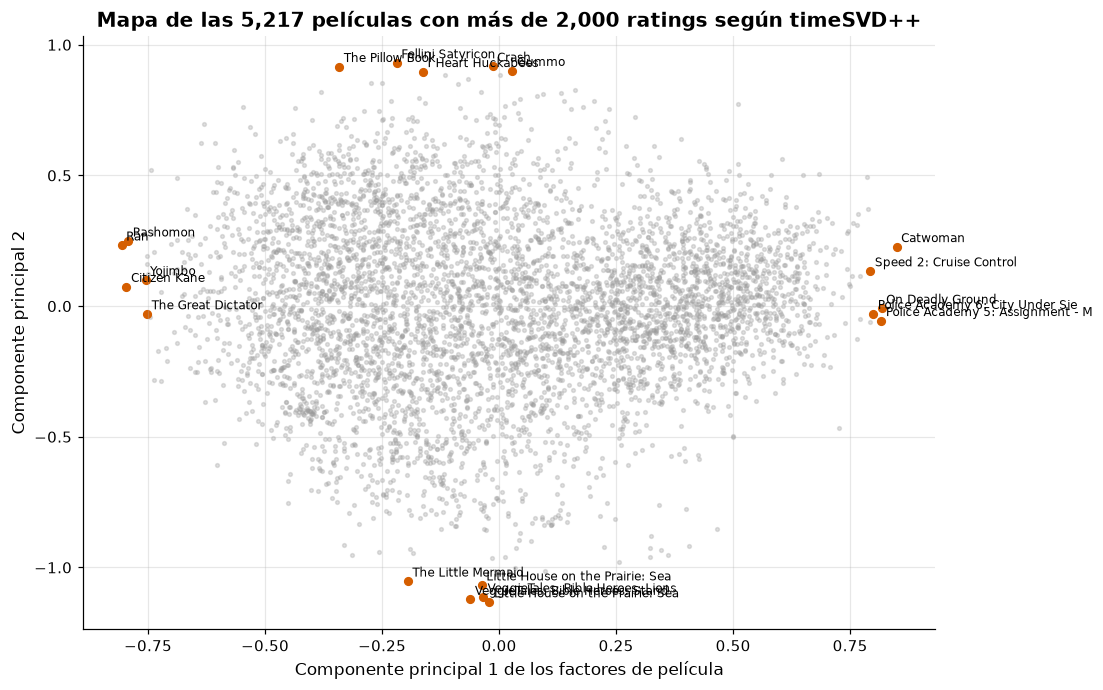


Componente 1, extremo negativo: Ran | Citizen Kane | Rashomon | Yojimbo | The Great Dictator | The Cabinet of Dr. Caligari
Componente 1, extremo positivo: The Glimmer Man | Speed 2: Cruise Control | Police Academy 6: City Under Siege | Police Academy 5: Assignment - Miami Beach | On Deadly Ground | Catwoman

Componente 2, extremo negativo: Little House on the Prairie: Season 2 | VeggieTales: Bible Heroes: Stand Up! Stand Tall! Stand Strong! | VeggieTales: Bible Heroes: Lions, Shepherds and Queens | Little House on the Prairie: Season 1 | The Little Mermaid | Little House on the Prairie: Season 3
Componente 2, extremo positivo: The Dreamers | I Heart Huckabees | Gummo | The Pillow Book | Crash | Fellini Satyricon


In [ ]:
from sklearn.decomposition import PCA

populares = np.flatnonzero(n_por_pelicula >= 2_000)
proyeccion = PCA(n_components=2, random_state=SEMILLA).fit_transform(tsvdpp.Q[populares])

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(proyeccion[:, 0], proyeccion[:, 1], s=6, alpha=0.3, color=COLOR_SECUNDARIO)
extremos = np.concatenate([np.argsort(proyeccion[:, 0])[:5], np.argsort(proyeccion[:, 0])[-5:],
                           np.argsort(proyeccion[:, 1])[:5], np.argsort(proyeccion[:, 1])[-5:]])
for m in np.unique(extremos):
    titulo = peliculas.loc[populares[m], "titulo"]
    ax.scatter(*proyeccion[m], s=25, color=COLOR_RESALTE)
    ax.annotate(titulo[:32], proyeccion[m], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Componente principal 1 de los factores de película")
ax.set_ylabel("Componente principal 2")
ax.set_title(f"Mapa de las {len(populares):,} películas con más de 2,000 ratings según timeSVD++")
guardar_figura(fig, "05_mapa_factores")
plt.show()

for eje in range(2):
    orden = np.argsort(proyeccion[:, eje])
    print(f"\nComponente {eje + 1}, extremo negativo: " + " | ".join(peliculas.loc[populares[orden[:6]], "titulo"]))
    print(f"Componente {eje + 1}, extremo positivo: " + " | ".join(peliculas.loc[populares[orden[-6:]], "titulo"]))

Proyectamos los 50 factores de las 5,217 películas con más de 2,000 ratings a dos dimensiones con PCA (análisis de componentes principales, que busca las dos direcciones que más varían) y marcamos las películas de los extremos.
- **Eje horizontal.** A la izquierda están clásicos del cine de arte (Ran, Rashomon, Yojimbo, Citizen Kane, The Great Dictator). A la derecha, acción y comedias taquilleras con muy mala crítica (Police Academy 5 y 6, Speed 2, Catwoman). Este eje separa "cine de crítica" de "cine de palomitas".
- **Eje vertical.** Abajo hay contenido familiar y religioso (La Casa de la Pradera, VeggieTales, La Sirenita). Arriba, cine independiente y provocador (The Dreamers, Gummo, The Pillow Book, Crash).

Nadie le dijo al modelo qué es un clásico o qué es contenido familiar. Lo descubrió porque los usuarios a los que les gusta Rashomon tienden a odiar Police Academy, y viceversa.

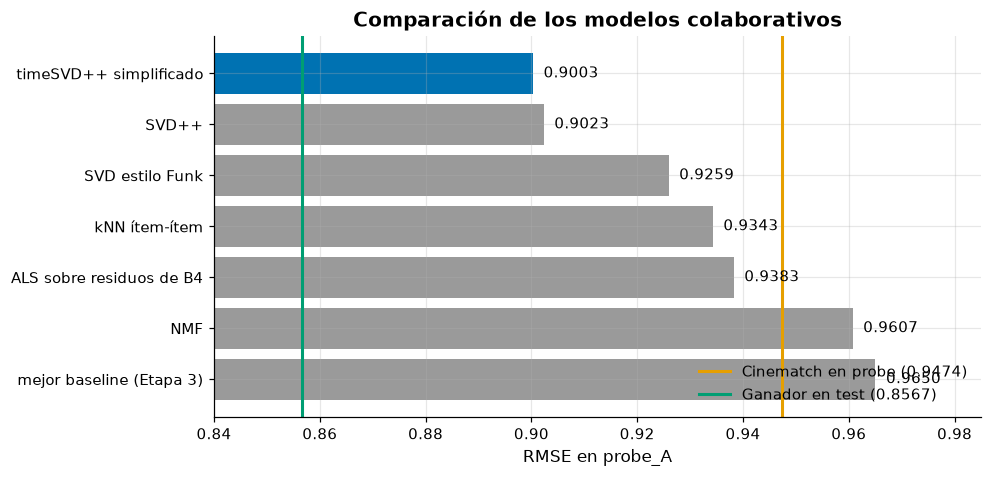

,modelo,descripcion,rmse_probe_A,minutos
0,B7,mejor baseline (Etapa 3),0.9650,NaN
1,CF_nmf,NMF,0.9607,3.3654
2,CF_als,ALS sobre residuos de B4,0.9383,30.4773
3,CF_knn,kNN ítem-ítem,0.9343,0.8449
4,CF_svd,SVD estilo Funk,0.9259,3.5368
5,CF_svdpp,SVD++,0.9023,6.3319
6,CF_timesvdpp,timeSVD++ simplificado,0.9003,6.2667


In [ ]:
tabla = pd.DataFrame(resultados)
anteriores = pd.read_csv(RAIZ / "experimentos.csv")
mejor_baseline = anteriores[anteriores["modelo"] == "B7"]["rmse_probe_A"].iloc[-1]
tabla = pd.concat([pd.DataFrame([{"modelo": "B7", "descripcion": "mejor baseline (Etapa 3)",
                                  "rmse_probe_A": mejor_baseline, "minutos": np.nan}]), tabla], ignore_index=True)
tabla = tabla.sort_values("rmse_probe_A", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [COLOR_PRINCIPAL if i == len(tabla) - 1 else COLOR_SECUNDARIO for i in range(len(tabla))]
ax.barh(tabla["descripcion"], tabla["rmse_probe_A"], color=colores)
for y, valor in enumerate(tabla["rmse_probe_A"]):
    ax.text(valor + 0.002, y, f"{valor:.4f}", va="center")
ax.axvline(RMSE_CINEMATCH_PROBE, color=COLOR_CINEMATCH, linewidth=2, label=f"Cinematch en probe ({RMSE_CINEMATCH_PROBE})")
ax.axvline(RMSE_GANADOR_TEST, color=COLOR_GANADOR, linewidth=2, label=f"Ganador en test ({RMSE_GANADOR_TEST})")
ax.set_xlim(0.84, tabla["rmse_probe_A"].max() + 0.02)
ax.set_xlabel("RMSE en probe_A")
ax.set_title("Comparación de los modelos colaborativos")
ax.legend(loc="lower right")
guardar_figura(fig, "05_comparacion")
plt.show()
tabla.round(4)

La tabla ordena los modelos de peor a mejor en probe_A. Todos mejoran a B7 (0.9650), pero con diferencias grandes. NMF apenas lo supera (0.9607), ALS y kNN quedan cerca de 0.935, SVD en 0.926, y los dos modelos con información implícita bajan de 0.903. timeSVD++ (0.9003) ya está 0.047 por debajo de Cinematch en probe (0.9474).

### Resumen de la Etapa 5

- **Mejor modelo.** timeSVD++ simplificado con 0.9003 en probe_A, seguido de SVD++ con 0.9023. Ambos están unas 0.047 por debajo de Cinematch.
- **Lo que más ayudó.** La información implícita (QUÉ calificó cada usuario) bajó el RMSE en 0.0236, de SVD a SVD++. Los sesgos temporales de B7 sumaron 0.0020 más.
- **Lo que menos ayudó.** NMF (0.9607) pierde flexibilidad por la no negatividad, y ALS (0.9383) es 9 veces más lento que SGD para un resultado peor.
- **kNN.** Con 0.9343 es menos preciso que la factorización, pero sus vecinos son muy fáciles de explicar ("te recomendamos X porque te gustó Y").
- **Pendiente.** La sensibilidad muestra que regularizamos de más (0.02 contra 0.005 cuesta 0.02 de RMSE). Antes del híbrido reentrenamos SVD++ y timeSVD++ con menos regularización y más factores en la sección siguiente.
- **Factores latentes.** El mapa 2D separa cine de crítica contra taquillero y contenido familiar contra independiente, sin que el modelo vea un solo título.

**Siguiente etapa.** Etapa 6, sistema híbrido que combina todos estos modelos con los de contenido.

## Etapa 5b. Ajuste final de la factorización

En la Etapa 5 la sensibilidad del SVD mostró que la regularización de 0.02 era demasiado alta, pues bajarla a 0.005 mejoraba el RMSE en 0.02 tras 8 épocas. Aquí aplicamos esa lección a los dos mejores modelos, SVD++ y timeSVD++ simplificado. Usamos 100 factores en lugar de 50, ya que con menos regularización los factores extra sí se pueden aprovechar, y entrenamos 20 épocas con un decaimiento de la tasa de aprendizaje de 0.92.

Todas las decisiones se toman en probe_A, igual que antes.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.datos import leer_train, leer_conjunto, cargar_csr, N_USUARIOS, N_PELICULAS
from src.baselines import SesgosTemporales, periodo_del_dia, calcular_dev
from src.metricas import rmse, registrar_experimento
from src.factorizacion import Factorizacion
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                                 COLOR_RESALTE, COLOR_CINEMATCH, RMSE_CINEMATCH_PROBE)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
PREDICCIONES = ARTEFACTOS / "predicciones"
MODELOS = ARTEFACTOS / "modelos"
aplicar_estilo()

Usamos las mismas funciones de `src/factorizacion.py` que en la Etapa 5. Solo cambian los hiperparámetros.

In [ ]:
train = leer_train()
probe_A = leer_conjunto("probe_A")
probe_B = leer_conjunto("probe_B")
N_TRAIN = len(train["ratings"])
mu = float(train["ratings"].mean())
csr_usuario = cargar_csr("csr_usuario")
implicito = cargar_csr("implicito")

# Predicción de B7 para cada rating, igual que en la Etapa 5
with np.load(MODELOS / "baseline_B7.npz") as archivo:
    parametros_b7 = {clave: archivo[clave] for clave in archivo.files}


def preparar_b7(datos, nombre):
    return {"usuarios": datos["usuarios"], "peliculas": datos["peliculas"],
            "periodos": periodo_del_dia(datos["dias"]),
            "devs": calcular_dev(datos["usuarios"], datos["dias"], parametros_b7["dia_medio_usuario"]),
            "usuario_dia": np.load(ARTEFACTOS / f"usuario_dia_{nombre}.npy")}


b7 = SesgosTemporales(float(parametros_b7["mu"]), N_USUARIOS, N_PELICULAS, len(parametros_b7["b_ut"]), [], {})
for clave in ["b_u", "b_i", "b_ibin", "alpha", "b_ut"]:
    setattr(b7, clave, parametros_b7[clave])
base_train = b7.predecir(preparar_b7(train, "train"))[csr_usuario["fila_original"]].astype(np.float32)
base_A = b7.predecir(preparar_b7(probe_A, "probe_A")).astype(np.float32)
base_B = b7.predecir(preparar_b7(probe_B, "probe_B")).astype(np.float32)
del train
print(f"B7 en probe_A: {rmse(probe_A['ratings'], base_A):.4f}")

B7 en probe_A: 0.9650


Cargamos train agrupado por usuario, el conjunto implícito N(u) y reconstruimos las predicciones de B7, que son la base del timeSVD++. B7 da 0.9650 en probe_A, igual que en la Etapa 3, lo que confirma que los parámetros se cargaron bien. Después borramos train de la memoria, porque ya no lo necesitamos.

In [ ]:
N_EPOCAS = 20
HIPER_BASE = {"n_factores": 100, "lr": 0.007, "lr_sesgo": 0.007, "reg_sesgo": 0.005, "decaimiento": 0.92}
historiales = {}
for reg in [0.005, 0.01]:
    hiper = {**HIPER_BASE, "reg": reg}
    print(f"SVD++ con reg = {reg}")
    inicio = time.perf_counter()
    modelo = Factorizacion(N_USUARIOS, N_PELICULAS, **hiper, usar_implicito=True, semilla=SEMILLA)
    historial = modelo.ajustar(csr_usuario, implicito, mu, evaluacion=(probe_A, None), n_epocas=N_EPOCAS)
    segundos = time.perf_counter() - inicio
    registrar_experimento("CF_svdpp_ajuste", hiper, N_TRAIN, historial["rmse_probe_A"].iloc[-1], segundos,
                          f"{N_EPOCAS} épocas")
    historiales[reg] = historial
    if reg == min(historiales, key=lambda r: historiales[r]["rmse_probe_A"].iloc[-1]):
        mejor_svdpp = (reg, hiper, segundos, modelo.predecir(probe_A, implicito), modelo.predecir(probe_B, implicito))
    del modelo

SVD++ con reg = 0.005


  época  1: train 0.8706, probe_A 0.9516 (50 s)


  época  2: train 0.8225, probe_A 0.9296 (46 s)


  época  3: train 0.7943, probe_A 0.9156 (43 s)


  época  4: train 0.7718, probe_A 0.9083 (43 s)


  época  5: train 0.7529, probe_A 0.9039 (44 s)


... (32 outputs left out)

  época 17: train 0.6961, probe_A 0.8960 (44 s)


  época 18: train 0.6934, probe_A 0.8959 (44 s)


  época 19: train 0.6910, probe_A 0.8960 (43 s)


  época 20: train 0.6888, probe_A 0.8960 (44 s)


Probamos dos valores de regularización, 0.005 y 0.01, con 100 factores y 20 épocas. Cada corrida tarda unos 16 minutos (cerca de 47 segundos por época, el doble que con 50 factores).

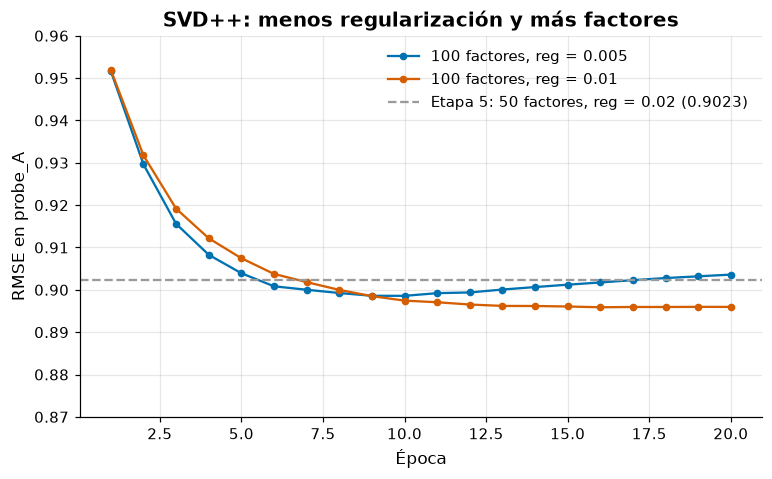

,reg = 0.005,reg = 0.01
epoca,,
1,0.9516,0.9519
5,0.9039,0.9075
10,0.8986,0.8975
15,0.9012,0.8961
20,0.9036,0.8960


In [ ]:
RMSE_SVDPP_ETAPA5 = 0.9023  # SVD++ con 50 factores y reg = 0.02 (Etapa 5)
fig, ax = plt.subplots()
for (reg, historial), color in zip(historiales.items(), [COLOR_PRINCIPAL, COLOR_RESALTE]):
    ax.plot(historial["epoca"], historial["rmse_probe_A"], marker="o", markersize=4, color=color,
            label=f"100 factores, reg = {reg}")
ax.axhline(RMSE_SVDPP_ETAPA5, color=COLOR_SECUNDARIO, linestyle="--",
           label=f"Etapa 5: 50 factores, reg = 0.02 ({RMSE_SVDPP_ETAPA5})")
ax.set_ylim(0.87, 0.96)
ax.set_xlabel("Época")
ax.set_ylabel("RMSE en probe_A")
ax.set_title("SVD++: menos regularización y más factores")
ax.legend()
guardar_figura(fig, "05b_svdpp_ajuste")
plt.show()
pd.DataFrame({f"reg = {r}": h["rmse_probe_A"].to_numpy() for r, h in historiales.items()},
             index=historiales[0.005]["epoca"]).iloc[[0, 4, 9, 14, 19]].round(4)

Las dos curvas cuentan historias distintas.
- **reg = 0.005** baja más rápido (0.9039 en la época 5 contra 0.9075) y toca su mínimo de 0.8986 en la época 10. Después **sube** hasta 0.9036 en la época 20. Este es sobreajuste clásico, pues el modelo sigue mejorando en train pero empieza a memorizar ruido y empeora en datos nuevos.
- **reg = 0.01** baja más despacio pero no se detiene. Termina en 0.8960, 0.0063 mejor que el SVD++ de la Etapa 5 (0.9023).

La lección es que la sensibilidad con 8 épocas engañaba un poco. Con 8 épocas 0.005 parecía mejor, pero con más épocas el modelo menos regularizado se pasa. Elegimos reg = 0.01.

In [ ]:
REG, HIPER_SVDPP, segundos, pred_A, pred_B = mejor_svdpp


def guardar_predicciones(nombre, pred_A, pred_B):
    pd.DataFrame({nombre: np.clip(pred_A, 1, 5).astype(np.float32)}).to_parquet(PREDICCIONES / f"{nombre}_probe_A.parquet")
    pd.DataFrame({nombre: np.clip(pred_B, 1, 5).astype(np.float32)}).to_parquet(PREDICCIONES / f"{nombre}_probe_B.parquet")


guardar_predicciones("CF_svdpp_aj", pred_A, pred_B)
registrar_experimento("CF_svdpp_aj", HIPER_SVDPP, N_TRAIN, rmse(probe_A["ratings"], pred_A), segundos,
                      f"{N_EPOCAS} épocas, mejor de la búsqueda")
print(f"SVD++ ajustado (reg = {REG}): RMSE probe_A = {rmse(probe_A['ratings'], pred_A):.4f}")

SVD++ ajustado (reg = 0.01): RMSE probe_A = 0.8960


Guardamos las predicciones del SVD++ ajustado como `CF_svdpp_aj`. No reemplazamos las de la Etapa 5, así el blending de la Etapa 6 puede usar ambas versiones.

In [ ]:
HIPER_TSVDPP = {**HIPER_SVDPP, "reg_sesgo": 0.02}
inicio = time.perf_counter()
tsvdpp = Factorizacion(N_USUARIOS, N_PELICULAS, **HIPER_TSVDPP, usar_implicito=True, semilla=SEMILLA)
historial_tsvdpp = tsvdpp.ajustar(csr_usuario, implicito, mu, base_train=base_train,
                                  evaluacion=(probe_A, base_A), n_epocas=N_EPOCAS)
segundos = time.perf_counter() - inicio
pred_A = tsvdpp.predecir(probe_A, implicito, base_A)
pred_B = tsvdpp.predecir(probe_B, implicito, base_B)
guardar_predicciones("CF_timesvdpp_aj", pred_A, pred_B)
registrar_experimento("CF_timesvdpp_aj", HIPER_TSVDPP, N_TRAIN, rmse(probe_A["ratings"], pred_A), segundos,
                      f"{N_EPOCAS} épocas, SVD++ ajustado sobre la predicción de B7")
np.savez(MODELOS / "timesvdpp_aj.npz", P=tsvdpp.P.astype(np.float32), Q=tsvdpp.Q.astype(np.float32),
         Y=tsvdpp.Y.astype(np.float32), b_u=tsvdpp.b_u, b_i=tsvdpp.b_i, mu=mu)
print(f"timeSVD++ ajustado: RMSE probe_A = {rmse(probe_A['ratings'], pred_A):.4f} en {segundos / 60:.1f} min")

  época  1: train 0.8096, probe_A 0.9266 (44 s)


  época  2: train 0.7869, probe_A 0.9181 (48 s)


  época  3: train 0.7708, probe_A 0.9121 (50 s)


  época  4: train 0.7572, probe_A 0.9074 (48 s)


  época  5: train 0.7456, probe_A 0.9038 (47 s)


  época  6: train 0.7354, probe_A 0.9007 (47 s)


... (11 outputs left out)

  época 18: train 0.6743, probe_A 0.8930 (46 s)


  época 19: train 0.6720, probe_A 0.8928 (46 s)


  época 20: train 0.6699, probe_A 0.8926 (46 s)


timeSVD++ ajustado: RMSE probe_A = 0.8926 en 16.6 min


Con los mismos hiperparámetros sobre la base de B7, el timeSVD++ ajustado llega a **0.8926** en probe_A, el mejor modelo individual del proyecto. Su curva ya casi no se mueve al final (0.0002 entre las épocas 19 y 20), así que más épocas no aportarían. El RMSE de train llega a 0.6699, muy por debajo del de probe_A, lo que muestra cuánto puede memorizar un modelo con 100 factores por usuario y por película.

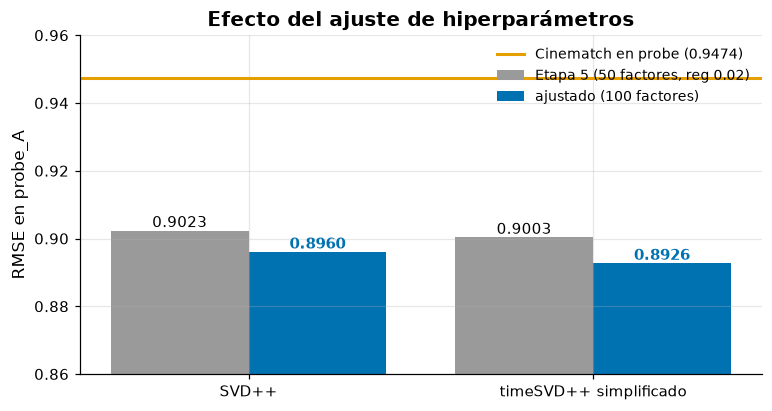

,"Etapa 5 (50 factores, reg 0.02)",ajustado (100 factores)
modelo,,
SVD++,0.9023,0.8960
timeSVD++ simplificado,0.9003,0.8926


In [ ]:
comparacion = pd.DataFrame({
    "modelo": ["SVD++", "timeSVD++ simplificado"],
    "Etapa 5 (50 factores, reg 0.02)": [0.9023, 0.9003],
    "ajustado (100 factores)": [rmse(probe_A["ratings"], pd.read_parquet(PREDICCIONES / "CF_svdpp_aj_probe_A.parquet").iloc[:, 0].to_numpy()),
                                rmse(probe_A["ratings"], pred_A)],
}).set_index("modelo")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(comparacion))
ax.bar(x - 0.2, comparacion.iloc[:, 0], width=0.4, color=COLOR_SECUNDARIO, label=comparacion.columns[0])
ax.bar(x + 0.2, comparacion.iloc[:, 1], width=0.4, color=COLOR_PRINCIPAL, label=comparacion.columns[1])
for i, (a, b) in enumerate(comparacion.to_numpy()):
    ax.text(i - 0.2, a, f"{a:.4f}", ha="center", va="bottom")
    ax.text(i + 0.2, b, f"{b:.4f}", ha="center", va="bottom", color=COLOR_PRINCIPAL, fontweight="bold")
ax.axhline(RMSE_CINEMATCH_PROBE, color=COLOR_CINEMATCH, linewidth=2, label=f"Cinematch en probe ({RMSE_CINEMATCH_PROBE})")
ax.set_xticks(x, comparacion.index)
ax.set_ylim(0.86, 0.96)
ax.set_ylabel("RMSE en probe_A")
ax.set_title("Efecto del ajuste de hiperparámetros")
ax.legend(loc="upper right", fontsize=9)
guardar_figura(fig, "05b_comparacion")
plt.show()
comparacion.round(4)

El ajuste mejora a los dos modelos en una cantidad parecida, 0.0063 en SVD++ (de 0.9023 a 0.8960) y 0.0077 en timeSVD++ (de 0.9003 a 0.8926). Ahora la ventaja de los sesgos temporales es de 0.0034, mayor que antes, porque con más capacidad el SVD++ aprovecha mejor una base que ya resolvió los efectos del tiempo.

### Resumen de la Etapa 5b

- **Mejor modelo individual.** timeSVD++ ajustado, con 0.8926 en probe_A, 0.0548 por debajo de Cinematch en probe (0.9474).
- **Lo que cambió.** 100 factores en lugar de 50 y regularización de 0.01 en lugar de 0.02. Mejora de 0.0077.
- **Lo que no funcionó.** Regularización de 0.005, que sobreajusta a partir de la época 10 y termina en 0.9036.
- **Costo.** Cada modelo tarda unos 16 minutos, el doble que con 50 factores.

**Siguiente etapa.** El sistema híbrido, que combina estos modelos con todos los anteriores.

## Etapa 6. Sistema híbrido

Un sistema híbrido combina varios recomendadores para cubrir las debilidades de cada uno. Probamos las cuatro formas clásicas de hacerlo.
1. **Combinación de características.** Describir cada película por quién la calificó y cómo ("Juan#Like", "Ana#Dislike") y mezclar eso con el contenido del título en un solo modelo.
2. **Conmutación.** Usar el contenido cuando hay poco historial y el colaborativo en el resto.
3. **Ponderado.** Una regresión lineal sobre las predicciones de todos los modelos.
4. **Blending no lineal.** Un LightGBM que recibe las predicciones y además variables que describen la situación (cuántos ratings tiene el usuario, la película, la fecha, etc.). Así fue como los ganadores del Netflix Prize juntaron cientos de modelos.

Los modelos de las Etapas 3 a 5 se entrenaron solo con train, así que sus predicciones en probe_A son "honestas" (no vieron esos ratings). Eso permite entrenar el blender sobre probe_A. Para medir su error usamos validación cruzada de 5 pliegues dentro de probe_A, y probe_B sigue sin tocarse hasta la Etapa 7.

In [ ]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.datos import (leer_train, leer_conjunto, cargar_csr, construir_csr_pelicula, N_USUARIOS, N_PELICULAS)
from src.baselines import sesgos_b4, lambdas_b4_desde_experimentos
from src.metricas import rmse, registrar_experimento
from src import vecinos
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                                 COLOR_RESALTE, COLOR_CINEMATCH, COLOR_GANADOR,
                                 RMSE_CINEMATCH_PROBE, RMSE_GANADOR_TEST)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
PREDICCIONES = ARTEFACTOS / "predicciones"
MODELOS = ARTEFACTOS / "modelos"
aplicar_estilo()

Usamos LightGBM para el blending no lineal y SHAP para explicarlo. Los cálculos de vecinos vienen de `src/vecinos.py`, el mismo módulo de las Etapas 4 y 5.

In [ ]:
train = leer_train()
probe_A = leer_conjunto("probe_A")
probe_B = leer_conjunto("probe_B")
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx").reset_index(drop=True)
N_TRAIN = len(train["ratings"])

csr_usuario = cargar_csr("csr_usuario")
csr_pelicula = construir_csr_pelicula(train)
LAMBDA_I, LAMBDA_U = lambdas_b4_desde_experimentos(RAIZ / "experimentos.csv")
mu, b_i, b_u = sesgos_b4(train, N_USUARIOS, N_PELICULAS, LAMBDA_I, LAMBDA_U)
n_por_usuario = np.bincount(train["usuarios"], minlength=N_USUARIOS)
n_por_pelicula = np.bincount(train["peliculas"], minlength=N_PELICULAS)


def cargar_predicciones(conjunto):
    """Junta en una tabla las predicciones de todos los modelos de las Etapas 3 a 5."""
    partes = [pd.read_parquet(PREDICCIONES / f"baselines_{conjunto}.parquet")[["B4", "B7"]],
              pd.read_parquet(PREDICCIONES / f"contenido_{conjunto}.parquet")]
    for nombre in ["CF_knn", "CF_svd", "CF_als", "CF_nmf", "CF_svdpp", "CF_timesvdpp", "CF_svdpp_aj", "CF_timesvdpp_aj"]:
        partes.append(pd.read_parquet(PREDICCIONES / f"{nombre}_{conjunto}.parquet"))
    return pd.concat(partes, axis=1)


predicciones_A = cargar_predicciones("probe_A")
predicciones_B = cargar_predicciones("probe_B")
rmse_individual = predicciones_A.apply(lambda columna: rmse(probe_A["ratings"], columna.to_numpy()))
rmse_individual.sort_values().round(4)

CF_timesvdpp_aj    0.8926
CF_svdpp_aj        0.8960
CF_timesvdpp       0.9003
CF_svdpp           0.9023
CF_svd             0.9259
CF_knn             0.9343
CF_als             0.9383
CF_nmf             0.9607
B7                 0.9650
C_knn_titulo       0.9769
C_edad             0.9835
B4                 0.9838
dtype: float64

Juntamos en una sola tabla las predicciones en probe_A de los 12 modelos de las Etapas 3 a 5b y medimos el RMSE de cada uno. El orden confirma lo que vimos antes. Los dos modelos ajustados de la Etapa 5b van primero (0.8926 y 0.8960), luego las versiones de 50 factores, los demás colaborativos, y al final los baselines y el contenido (de 0.9650 a 0.9838).

### 1. Combinación de características: usuario#Like más título

La teoría propone describir cada ítem por quién lo calificó y cómo. Por ejemplo, Titanic tendría las características "Juan#Like" y "Ana#Dislike", y dos películas se parecen si les gustaron y disgustaron a las mismas personas. Esta descripción colaborativa se puede unir con las características de contenido (los n-gramas del título) en un solo vector.

En la práctica construimos la similitud entre películas con valores +1 (rating ≥ 4) y -1 (rating < 4) por usuario, y la mezclamos con la similitud de títulos con un peso de 0, 0.1 o 0.3. Luego predecimos con el mismo kNN de la Etapa 5.

In [ ]:
with np.load(MODELOS / "vecinos_titulo.npz") as archivo:
    vecinos_titulo_todos, similitud_titulo_todos = archivo["vecinos"], archivo["similitud"]

normas_like = vecinos.normas_por_pelicula(csr_pelicula["inicio"], csr_pelicula["usuarios"], csr_pelicula["ratings"],
                                          vecinos.MODO_LIKE, mu, b_u, b_i)
resultados_combinacion = []
modelos_combinacion = {}
for peso_titulo in [0.0, 0.1, 0.3]:
    inicio = time.perf_counter()
    vecinos_h, similitud_h = vecinos.similitudes_top_k(
        csr_pelicula["inicio"], csr_pelicula["usuarios"], csr_pelicula["ratings"],
        csr_usuario["inicio"], csr_usuario["peliculas"], csr_usuario["ratings"],
        vecinos.MODO_LIKE, mu, b_u, b_i, normas_like, 100, 50,
        vecinos_titulo_todos, similitud_titulo_todos, peso_titulo)
    segundos_similitud = time.perf_counter() - inicio
    for k in [20, 50]:
        for regularizacion in [0.05, 0.3]:
            pred, _ = vecinos.predecir(probe_A, csr_usuario, vecinos_h[:, :k].copy(), similitud_h[:, :k].copy(),
                                       mu, b_u, b_i, regularizacion)
            error = rmse(probe_A["ratings"], pred)
            hiper = {"peso_titulo": peso_titulo, "k": k, "regularizacion": regularizacion}
            registrar_experimento("H_like_titulo_busqueda", hiper, N_TRAIN, error, segundos_similitud,
                                  "ítem descrito por usuario#Like/Dislike + n-gramas del título")
            resultados_combinacion.append({**hiper, "rmse_probe_A": error})
    modelos_combinacion[peso_titulo] = (vecinos_h, similitud_h, segundos_similitud)
    print(f"peso del título {peso_titulo}: similitudes en {segundos_similitud / 60:.1f} min")

resultados_combinacion = pd.DataFrame(resultados_combinacion)
resultados_combinacion.round(4)

peso del título 0.0: similitudes en 0.8 min


peso del título 0.1: similitudes en 0.7 min


peso del título 0.3: similitudes en 0.7 min


,peso_titulo,k,regularizacion,rmse_probe_A
0,0.0,20,0.05,0.9739
1,0.0,20,0.30,0.9489
2,0.0,50,0.05,0.9617
3,0.0,50,0.30,0.9443
4,0.1,20,0.05,0.9748
5,0.1,20,0.30,0.9491
6,0.1,50,0.05,0.9624
7,0.1,50,0.30,0.9443
8,0.3,20,0.05,0.9943
9,0.3,20,0.30,0.9619


El resultado es claro. Agregar el título no ayuda, y con peso 0.3 empeora bastante (de 0.9443 a 0.9537 con k = 50). Con peso 0.1 queda igual que sin título. Como en la Etapa 4, la similitud de títulos mete vecinos falsos ("Sorcerer" con Harry Potter) que contaminan a los vecinos colaborativos, que ya son buenos.

In [ ]:
mejor = resultados_combinacion.loc[resultados_combinacion["rmse_probe_A"].idxmin()]
vecinos_h, similitud_h, segundos = modelos_combinacion[mejor["peso_titulo"]]
k, regularizacion = int(mejor["k"]), float(mejor["regularizacion"])
pred_A, usados_A = vecinos.predecir(probe_A, csr_usuario, vecinos_h[:, :k].copy(), similitud_h[:, :k].copy(), mu, b_u, b_i, regularizacion)
pred_B, usados_B = vecinos.predecir(probe_B, csr_usuario, vecinos_h[:, :k].copy(), similitud_h[:, :k].copy(), mu, b_u, b_i, regularizacion)
predicciones_A["H_like_titulo"] = pred_A
predicciones_B["H_like_titulo"] = pred_B
registrar_experimento("H_like_titulo", mejor.drop("rmse_probe_A").to_dict(), N_TRAIN, rmse(probe_A["ratings"], pred_A),
                      segundos, "combinación de características")
print(f"Mejor combinación de características: {mejor.to_dict()}")


def mostrar_vecinos(texto, vecinos_m, similitud_m, n=6):
    candidatas = peliculas[peliculas["titulo"].str.contains(texto, case=False, regex=False)]
    i = int(candidatas.loc[candidatas["movie_idx"].map(lambda m: n_por_pelicula[m]).idxmax(), "movie_idx"])
    print(f"\n=== {peliculas.loc[i, 'titulo']}")
    for j, s in zip(vecinos_m[i, :n], similitud_m[i, :n]):
        print(f"   {s:.3f}  {peliculas.loc[j, 'titulo']}")


for texto in ["Harry Potter and the Sorcerer", "Rocky"]:
    mostrar_vecinos(texto, vecinos_h, similitud_h)
del modelos_combinacion

Mejor combinación de características: {'peso_titulo': 0.0, 'k': 50.0, 'regularizacion': 0.3, 'rmse_probe_A': 0.9442771517909493}

=== Harry Potter and the Sorcerer's Stone
   0.590  Harry Potter and the Chamber of Secrets
   0.442  Harry Potter and the Prisoner of Azkaban
   0.327  Shrek (Full-screen)
   0.322  Finding Nemo (Widescreen)
   0.321  Lord of the Rings: The Fellowship of the Ring
   0.318  Monsters, Inc.

=== Rocky
   0.235  Jaws
   0.225  Rocky II
   0.216  Die Hard
   0.214  The Terminator
   0.189  Rambo: First Blood: Ultimate Edition
   0.188  The Godfather


La mejor versión no usa el título (peso 0, k = 50, regularización 0.3) y logra 0.9443. Es peor que el kNN de la Etapa 5 (0.9343), que usaba residuos en lugar de Like/Dislike. La razón es que convertir el rating en +1 o -1 tira información, pues un 5 y un 4 valen lo mismo, y un 3 cuenta igual que un 1.

Los vecinos sí tienen sentido. Harry Potter 1 se parece a sus secuelas (0.590 y 0.442) y luego a Shrek, Finding Nemo y El Señor de los Anillos, es decir, películas familiares de taquilla. La conclusión es que la combinación de características funciona como idea, pero la representación binaria pierde precisión frente a los residuos.

### 2. Conmutación: contenido para quien tiene poco historial

La intuición es que el colaborativo necesita historial y el contenido no tanto. Probamos una regla simple. Si el usuario (o la película) tiene menos de N ratings en train, usamos el kNN por título de la Etapa 4, y si no, el mejor colaborativo (timeSVD++ ajustado). Movemos N y graficamos el RMSE.

Modelo colaborativo usado en la conmutación: CF_timesvdpp_aj


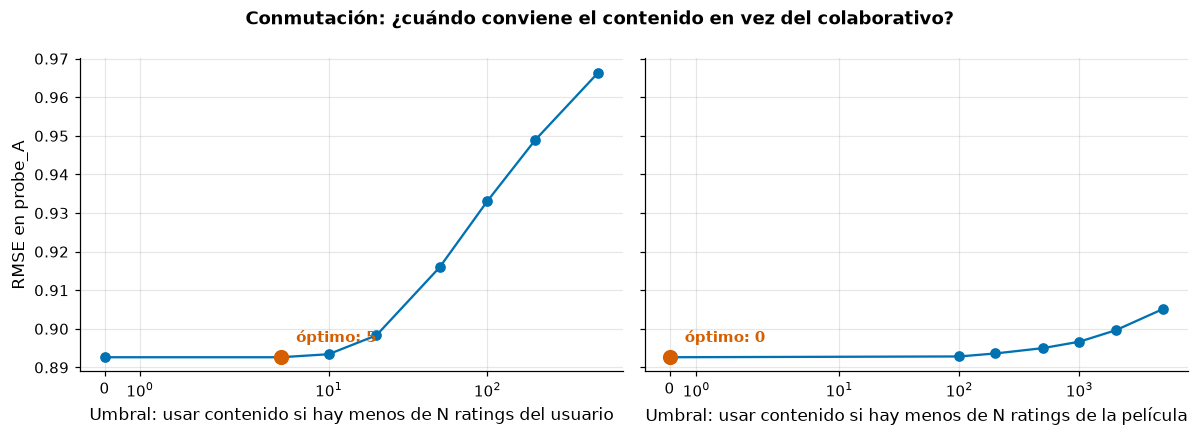

Por usuario: {0: np.float64(0.8926), 5: np.float64(0.8926), 10: np.float64(0.8934), 20: np.float64(0.8983), 50: np.float64(0.9159), 100: np.float64(0.9331), 200: np.float64(0.9489), 500: np.float64(0.9664)}
Por película: {0: np.float64(0.8926), 100: np.float64(0.8928), 200: np.float64(0.8936), 500: np.float64(0.895), 1000: np.float64(0.8967), 2000: np.float64(0.8996), 5000: np.float64(0.9052)}


In [ ]:
reales_A = probe_A["ratings"].astype(np.float64)
contenido = predicciones_A["C_knn_titulo"].to_numpy()
MEJOR_CF = rmse_individual[[c for c in rmse_individual.index if c.startswith("CF_")]].idxmin()
colaborativo = predicciones_A[MEJOR_CF].to_numpy()
print(f"Modelo colaborativo usado en la conmutación: {MEJOR_CF}")
n_u_A = n_por_usuario[probe_A["usuarios"]]
n_i_A = n_por_pelicula[probe_A["peliculas"]]

umbrales_usuario = [0, 5, 10, 20, 50, 100, 200, 500]
umbrales_pelicula = [0, 100, 200, 500, 1_000, 2_000, 5_000]
curva_usuario = [rmse(reales_A, np.where(n_u_A < t, contenido, colaborativo)) for t in umbrales_usuario]
curva_pelicula = [rmse(reales_A, np.where(n_i_A < t, contenido, colaborativo)) for t in umbrales_pelicula]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, umbrales, curva, etiqueta in [(ejes[0], umbrales_usuario, curva_usuario, "ratings del usuario"),
                                      (ejes[1], umbrales_pelicula, curva_pelicula, "ratings de la película")]:
    ax.plot(umbrales, curva, marker="o", color=COLOR_PRINCIPAL)
    mejor_t = int(np.argmin(curva))
    ax.scatter([umbrales[mejor_t]], [curva[mejor_t]], color=COLOR_RESALTE, s=80, zorder=3)
    ax.annotate(f"óptimo: {umbrales[mejor_t]}", (umbrales[mejor_t], curva[mejor_t]), xytext=(10, 10),
                textcoords="offset points", color=COLOR_RESALTE, fontweight="bold")
    ax.set_xscale("symlog", linthresh=5)
    ax.set_xlabel(f"Umbral: usar contenido si hay menos de N {etiqueta}")
ejes[0].set_ylabel("RMSE en probe_A")
fig.suptitle("Conmutación: ¿cuándo conviene el contenido en vez del colaborativo?", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "06_conmutacion")
plt.show()
print("Por usuario:", dict(zip(umbrales_usuario, np.round(curva_usuario, 4))))
print("Por película:", dict(zip(umbrales_pelicula, np.round(curva_pelicula, 4))))

El umbral óptimo es prácticamente **no conmutar nunca**. Por usuario, usar contenido con menos de 5 ratings deja el RMSE igual (0.8926), y con 20 ya empeora a 0.8983. Por película el óptimo es 0, y con 5,000 sube a 0.9052. El punto naranja marca el mínimo de cada curva.

Esto contradice la intuición, pero tiene una explicación. Nuestro modelo de contenido no es "puro", sino un kNN que se apoya en B4 y en los títulos que el usuario ya calificó. Para un usuario con pocos ratings ese contenido tampoco tiene información. En cambio timeSVD++ usa la información implícita de probe y qualifying, que le dice qué películas eligió el usuario aunque tenga pocos ratings en train.

In [ ]:
por_usuario = pd.DataFrame({"tramo": pd.cut(n_u_A, [0, 20, 50, 200, 1_000, 20_000]),
                            "contenido": (reales_A - contenido) ** 2,
                            "colaborativo": (reales_A - colaborativo) ** 2})
por_usuario = np.sqrt(por_usuario.groupby("tramo", observed=True)[["contenido", "colaborativo"]].mean())
por_usuario.round(4)

,contenido,colaborativo
tramo,,
"(0, 20]",1.0495,1.0025
"(20, 50]",1.0320,0.9545
"(50, 200]",0.9796,0.8891
"(200, 1000]",0.9093,0.8112
"(1000, 20000]",0.8754,0.7662


La tabla lo confirma por tramos de actividad del usuario. El colaborativo gana en todos, incluso entre los usuarios con 20 ratings o menos (1.0025 contra 1.0495). La diferencia crece con el historial y llega a 0.11 en los usuarios con más de 1,000 ratings (0.7662 contra 0.8754). Con solo título y año, el contenido no le gana al colaborativo en ningún segmento.

### 3. Metavariables para el blending

Además de las predicciones, el blender recibe variables que describen la situación de cada predicción, sin usar el rating.
- `log_ratings_usuario` y `log_ratings_pelicula`. Cuánto historial hay (en logaritmo, porque van de 1 a miles).
- `dia`. La fecha del rating, en días desde el inicio del dataset.
- `anio_estreno`. El año de la película.
- `vecinos_titulo_calificados`. Cuántos de los 10 vecinos por título calificó el usuario. Es la "similitud de contenido" del enunciado, pues indica si el modelo de contenido tiene de dónde agarrarse.
- `vecinos_cf_calificados`. Lo mismo para los 50 vecinos colaborativos.

La idea es que el blender aprenda reglas como "si el usuario tiene pocos ratings, confía menos en el modelo X".

In [ ]:
with np.load(MODELOS / "vecinos_cf.npz") as archivo:
    vecinos_cf = archivo["vecinos"][:, :int(archivo["k"])].copy()
    similitud_cf = archivo["similitud"][:, :int(archivo["k"])].copy()


def metavariables(datos, predicciones):
    """Variables que describen la situación de cada predicción, no el rating."""
    _, vecinos_titulo_usados = vecinos.predecir(datos, csr_usuario, vecinos_titulo_todos[:, :10].copy(),
                                                similitud_titulo_todos[:, :10].copy(), mu, b_u, b_i, 1.0)
    _, vecinos_cf_usados = vecinos.predecir(datos, csr_usuario, vecinos_cf, similitud_cf, mu, b_u, b_i, 1.0)
    anio = peliculas["anio"].fillna(peliculas["anio"].median()).to_numpy()
    tabla = predicciones.copy()
    tabla["log_ratings_usuario"] = np.log1p(n_por_usuario[datos["usuarios"]])
    tabla["log_ratings_pelicula"] = np.log1p(n_por_pelicula[datos["peliculas"]])
    tabla["dia"] = datos["dias"]
    tabla["anio_estreno"] = anio[datos["peliculas"]]
    tabla["vecinos_titulo_calificados"] = vecinos_titulo_usados
    tabla["vecinos_cf_calificados"] = vecinos_cf_usados
    return tabla


X_A = metavariables(probe_A, predicciones_A)
X_B = metavariables(probe_B, predicciones_B)
columnas_modelos = list(predicciones_A.columns)
columnas_meta = [c for c in X_A.columns if c not in columnas_modelos]
print("Modelos:", columnas_modelos)
print("Metavariables:", columnas_meta)
X_A[columnas_meta].describe().round(2)

Modelos: ['B4', 'B7', 'C_edad', 'C_knn_titulo', 'CF_knn', 'CF_svd', 'CF_als', 'CF_nmf', 'CF_svdpp', 'CF_timesvdpp', 'CF_svdpp_aj', 'CF_timesvdpp_aj', 'H_like_titulo']
Metavariables: ['log_ratings_usuario', 'log_ratings_pelicula', 'dia', 'anio_estreno', 'vecinos_titulo_calificados', 'vecinos_cf_calificados']


,log_ratings_usuario,log_ratings_pelicula,dia,anio_estreno,vecinos_titulo_calificados,vecinos_cf_calificados
count,704197.00,704197.00,704197.00,704197.00,704197.00,704197.00
mean,4.61,10.07,2108.62,1997.30,0.30,8.56
std,1.26,1.65,169.84,11.75,0.79,8.48
min,0.69,1.95,56.00,1909.00,0.00,0.00
25%,3.66,9.20,2059.00,1995.00,0.00,2.00
50%,4.60,10.53,2169.00,2002.00,0.00,6.00
75%,5.58,11.39,2216.00,2004.00,0.00,13.00
max,9.78,12.34,2242.00,2005.00,10.00,50.00


La tabla resume las metavariables en probe_A. La mediana de usuario tiene unos 100 ratings (e^4.6) y la película mediana unos 37 mil (e^10.5), pues las películas populares dominan probe. El 75% de las filas no tiene ningún vecino por título calificado, lo que confirma que el contenido solo opina en una minoría de casos. En cambio la mediana de vecinos colaborativos calificados es 6 de 50.

### 4. Híbrido ponderado: regresión lineal

La forma más simple de combinar es una suma ponderada, r̂ = w_0 + Σ w_m · r̂_m, con los pesos w_m ajustados por mínimos cuadrados en probe_A. Medimos el error con validación cruzada de 5 pliegues. Entrenamos con 4/5 de probe_A, predecimos el quinto restante, y repetimos hasta cubrirlo todo. Así ninguna predicción viene de un modelo que vio ese rating.

In [ ]:
pliegues = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
oof_lineal = np.zeros(len(reales_A))
for entrenar, validar in pliegues.split(X_A):
    modelo = LinearRegression().fit(X_A.iloc[entrenar][columnas_modelos], reales_A[entrenar])
    oof_lineal[validar] = modelo.predict(X_A.iloc[validar][columnas_modelos])
rmse_lineal = rmse(reales_A, oof_lineal)

inicio = time.perf_counter()
lineal = LinearRegression().fit(X_A[columnas_modelos], reales_A)
registrar_experimento("H_lineal", {"modelos": columnas_modelos}, len(reales_A), rmse_lineal,
                      time.perf_counter() - inicio, "regresión lineal entrenada en probe_A, RMSE por validación cruzada 5 pliegues")
pesos = pd.Series(lineal.coef_, index=columnas_modelos).sort_values()
print(f"RMSE por validación cruzada en probe_A: {rmse_lineal:.4f}")
print(f"Intercepto: {lineal.intercept_:.3f}, suma de pesos: {pesos.sum():.3f}")

RMSE por validación cruzada en probe_A: 0.8860
Intercepto: -0.082, suma de pesos: 1.014


La combinación lineal logra 0.8860 en validación cruzada, 0.0066 mejor que el mejor modelo solo (0.8926). Los pesos suman 1.014 y el intercepto es -0.082, así que la predicción final queda en la escala correcta de 1 a 5.

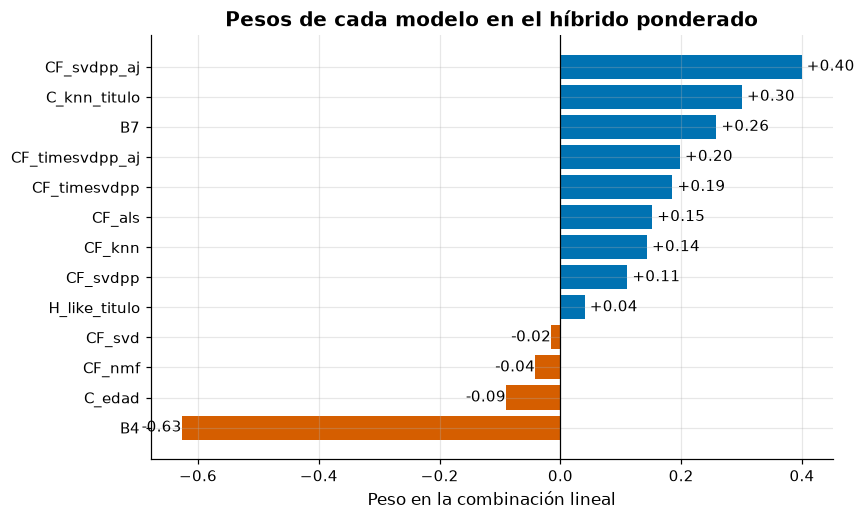

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pesos.index, pesos.values, color=np.where(pesos.values > 0, COLOR_PRINCIPAL, COLOR_RESALTE))
for y, valor in enumerate(pesos.values):
    ax.text(valor, y, f" {valor:+.2f}", va="center", ha="left" if valor > 0 else "right")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Peso en la combinación lineal")
ax.set_title("Pesos de cada modelo en el híbrido ponderado")
guardar_figura(fig, "06_pesos_lineal")
plt.show()

Los pesos no se leen como "importancia" directa, porque los modelos están muy correlacionados entre sí. Aun así dicen cosas interesantes.
- **SVD++ ajustado** tiene el peso más alto (+0.40), más que timeSVD++ ajustado (+0.20), aunque este sea mejor solo. Como ambos se parecen mucho, la regresión reparte el peso entre los dos.
- **B4 tiene peso de -0.63.** La regresión le resta B4 a la suma. Esto pasa porque casi todos los modelos contienen a B4 por dentro (los sesgos). Al sumarlos, B4 quedaría contado muchas veces, y el peso negativo lo corrige.
- **El kNN por título tiene +0.30**, un peso alto para un modelo que solo logra 0.9769. Aporta algo que los demás no tienen, la información de sagas y temporadas.

### 5. Blending no lineal con LightGBM

LightGBM entrena muchos árboles de decisión pequeños, cada uno corrigiendo el error de los anteriores (gradient boosting). A diferencia de la regresión lineal, puede aprender que el peso de un modelo depende de la situación, por ejemplo confiar más en el kNN cuando el usuario calificó muchos vecinos de la película.

Probamos dos tamaños de árbol (15 y 63 hojas) con validación cruzada de 5 pliegues y parada temprana. La parada temprana detiene el entrenamiento cuando el pliegue de validación deja de mejorar durante 50 árboles.

In [ ]:
columnas_lgbm = columnas_modelos + columnas_meta


def validar_lgbm(parametros):
    """Validación cruzada de 5 pliegues en probe_A con parada temprana."""
    oof = np.zeros(len(reales_A))
    iteraciones = []
    for entrenar, validar in pliegues.split(X_A):
        modelo = lgb.LGBMRegressor(**parametros)
        modelo.fit(X_A.iloc[entrenar][columnas_lgbm], reales_A[entrenar],
                   eval_set=[(X_A.iloc[validar][columnas_lgbm], reales_A[validar])],
                   callbacks=[lgb.early_stopping(50, verbose=False)])
        oof[validar] = modelo.predict(X_A.iloc[validar][columnas_lgbm])
        iteraciones.append(modelo.best_iteration_)
    return oof, int(np.mean(iteraciones))


base_lgbm = {"n_estimators": 3000, "learning_rate": 0.05, "min_child_samples": 200, "subsample": 0.8,
             "subsample_freq": 1, "colsample_bytree": 0.8, "reg_lambda": 1.0, "random_state": SEMILLA,
             "verbose": -1, "n_jobs": 8}
busqueda_lgbm = []
mejor_lgbm = None
for hojas in [15, 63]:
    inicio = time.perf_counter()
    parametros = {**base_lgbm, "num_leaves": hojas}
    oof, iteraciones = validar_lgbm(parametros)
    error = rmse(reales_A, oof)
    segundos = time.perf_counter() - inicio
    registrar_experimento("H_lgbm_busqueda", {"num_leaves": hojas, "iteraciones": iteraciones}, len(reales_A),
                          error, segundos, "validación cruzada 5 pliegues en probe_A")
    busqueda_lgbm.append({"num_leaves": hojas, "iteraciones": iteraciones, "rmse_cv": error, "minutos": segundos / 60})
    if mejor_lgbm is None or error < mejor_lgbm[0]:
        mejor_lgbm = (error, hojas, iteraciones, oof)
pd.DataFrame(busqueda_lgbm).round(4)

,num_leaves,iteraciones,rmse_cv,minutos
0,15,889,0.883,0.9308
1,63,344,0.883,0.6311


Los dos tamaños empatan en 0.8830. Los árboles de 15 hojas necesitan 889 iteraciones y los de 63 solo 344, pues cada árbol grande aprende más. Nos quedamos con 15 hojas (0.883007 contra 0.883010), una diferencia despreciable. Cada búsqueda completa toma menos de un minuto.

In [ ]:
rmse_lgbm, HOJAS, ITERACIONES, oof_lgbm = mejor_lgbm
inicio = time.perf_counter()
blender = lgb.LGBMRegressor(**{**base_lgbm, "num_leaves": HOJAS, "n_estimators": ITERACIONES})
blender.fit(X_A[columnas_lgbm], reales_A)
registrar_experimento("H_lgbm", {"num_leaves": HOJAS, "n_estimators": ITERACIONES}, len(reales_A), rmse_lgbm,
                      time.perf_counter() - inicio, "blender final entrenado en todo probe_A, RMSE = validación cruzada")
blender.booster_.save_model(str(MODELOS / "blender_lgbm.txt"))

comparacion = pd.Series({
    "mejor modelo individual (" + rmse_individual.idxmin() + ")": rmse_individual.min(),
    "híbrido ponderado (lineal)": rmse_lineal,
    "blending LightGBM": rmse_lgbm,
})
comparacion.round(4)

mejor modelo individual (CF_timesvdpp_aj)    0.8926
híbrido ponderado (lineal)                   0.8860
blending LightGBM                            0.8830
dtype: float64

Entrenamos el blender final con todo probe_A y el número de árboles que encontró la validación cruzada. El blending no lineal logra **0.8830**, 0.0030 mejor que el lineal (0.8860) y 0.0096 mejor que el mejor modelo individual (0.8926). Es el mejor resultado del proyecto en probe_A.

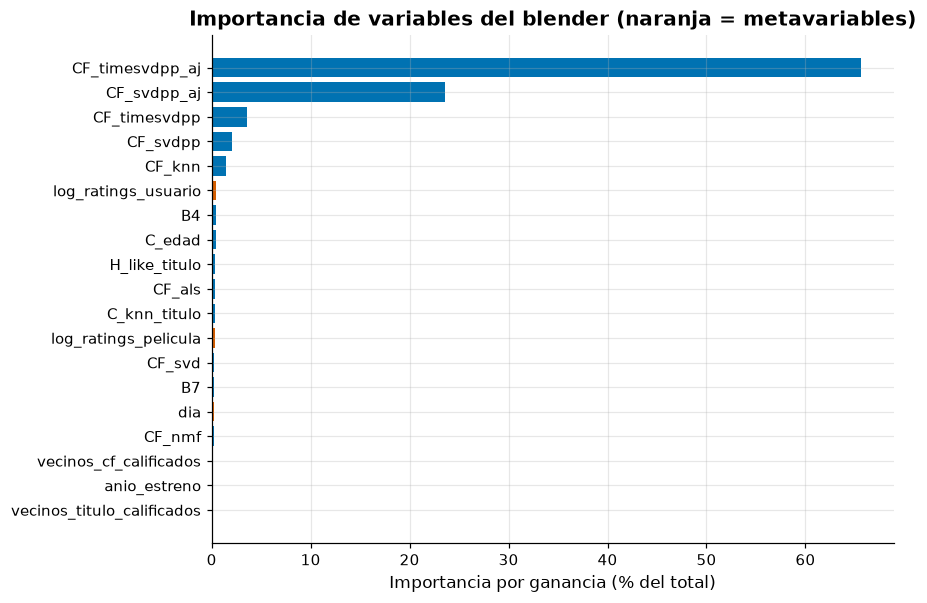

In [ ]:
importancia = pd.Series(blender.booster_.feature_importance(importance_type="gain"), index=columnas_lgbm)
importancia = (importancia / importancia.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importancia.index, 100 * importancia.values,
        color=[COLOR_RESALTE if c in columnas_meta else COLOR_PRINCIPAL for c in importancia.index])
ax.set_xlabel("Importancia por ganancia (% del total)")
ax.set_title("Importancia de variables del blender (naranja = metavariables)")
guardar_figura(fig, "06_importancia_lgbm")
plt.show()

La importancia por ganancia mide cuánto reduce el error cada variable al usarse en los cortes de los árboles. timeSVD++ ajustado concentra el 65.6% y SVD++ ajustado el 23.5%, así que el blender se apoya casi por completo en los dos mejores modelos. Las metavariables (en naranja) suman menos del 2%. Los árboles usan las metavariables para ajustes finos y no como base de la predicción.

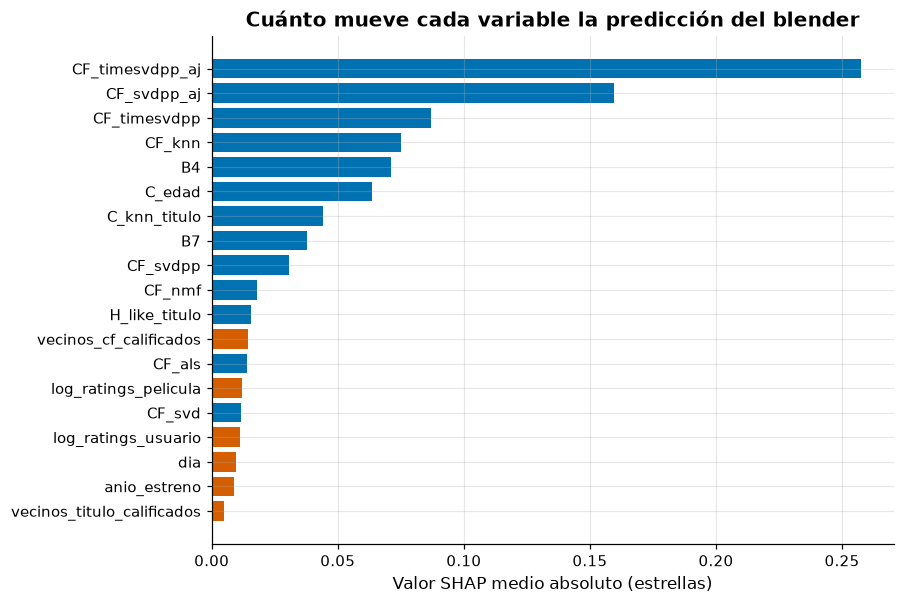

In [ ]:
muestra = X_A.sample(5_000, random_state=SEMILLA)[columnas_lgbm]
valores_shap = shap.TreeExplainer(blender).shap_values(muestra)
shap_medio = pd.Series(np.abs(valores_shap).mean(axis=0), index=columnas_lgbm).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_medio.index, shap_medio.values,
        color=[COLOR_RESALTE if c in columnas_meta else COLOR_PRINCIPAL for c in shap_medio.index])
ax.set_xlabel("Valor SHAP medio absoluto (estrellas)")
ax.set_title("Cuánto mueve cada variable la predicción del blender")
guardar_figura(fig, "06_shap_medio")
plt.show()

SHAP reparte cada predicción entre las variables, de forma que la suma de las contribuciones más un valor base da la predicción. El valor medio absoluto dice cuántas estrellas mueve cada variable en promedio, calculado en una muestra de 5,000 filas.

El orden es parecido a la importancia, pero menos extremo. timeSVD++ ajustado mueve 0.26 estrellas en promedio y SVD++ ajustado 0.16. Después aparecen timeSVD++ (0.09), kNN (0.07), B4 (0.07) y B4 + edad (0.06). Estas variables mueven la predicción en sentidos opuestos y se compensan, igual que el peso negativo de B4 en la regresión lineal. Entre las metavariables la más útil es `vecinos_cf_calificados`, con 0.015 estrellas.

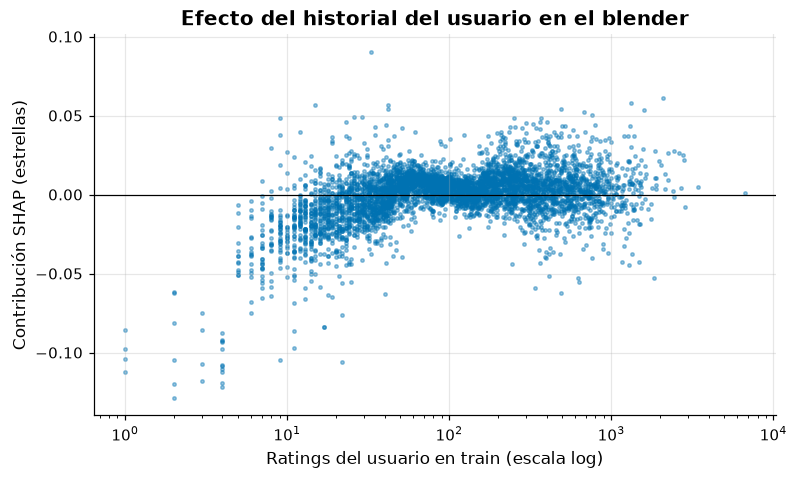

In [ ]:
posicion = columnas_lgbm.index("log_ratings_usuario")
fig, ax = plt.subplots()
ax.scatter(np.expm1(muestra["log_ratings_usuario"]), valores_shap[:, posicion], s=5, alpha=0.4, color=COLOR_PRINCIPAL)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Ratings del usuario en train (escala log)")
ax.set_ylabel("Contribución SHAP (estrellas)")
ax.set_title("Efecto del historial del usuario en el blender")
guardar_figura(fig, "06_shap_ratings_usuario")
plt.show()

Este es el efecto de una metavariable en particular. Cada punto es una predicción, y el eje vertical es cuánto la movió el historial del usuario. Con menos de 10 ratings la contribución es negativa, de hasta -0.13 estrellas, y desde unos 50 ratings oscila alrededor de cero.

El blender aprendió que, para usuarios con muy poco historial, los modelos predicen demasiado alto y hay que bajarlos. Tiene sentido, ya que con pocos ratings los sesgos de usuario se encogen hacia cero y la predicción queda cerca del promedio de la película, que en películas populares es alto.

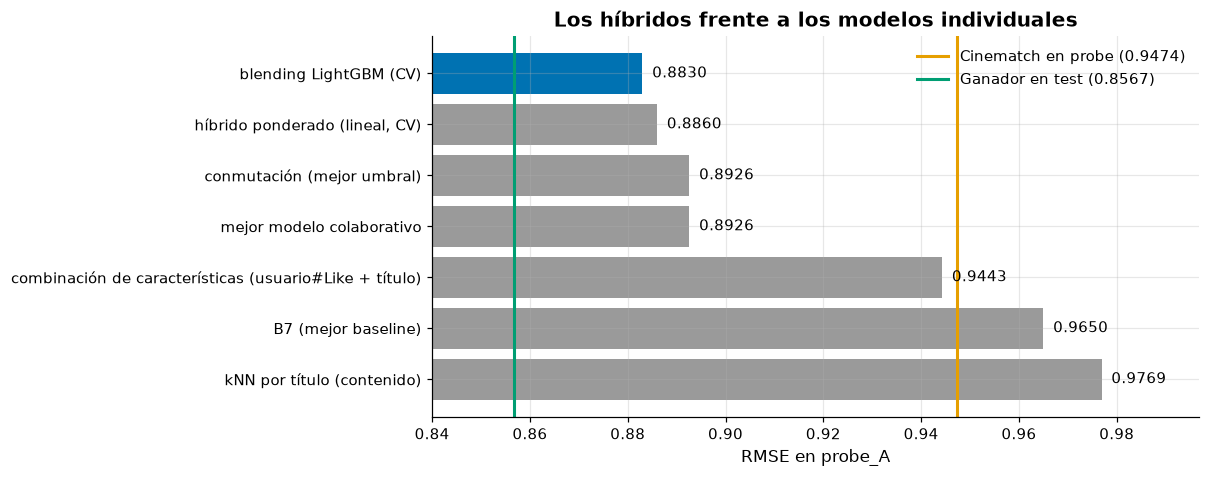

kNN por título (contenido)                                0.9769
B7 (mejor baseline)                                       0.9650
combinación de características (usuario#Like + título)    0.9443
mejor modelo colaborativo                                 0.8926
conmutación (mejor umbral)                                0.8926
híbrido ponderado (lineal, CV)                            0.8860
blending LightGBM (CV)                                    0.8830
dtype: float64

In [ ]:
rmse_conmutacion = min(curva_usuario + curva_pelicula)
predicciones_A["H_lineal"] = oof_lineal
predicciones_A["H_lgbm"] = oof_lgbm
predicciones_B["H_lineal"] = lineal.predict(X_B[columnas_modelos])
predicciones_B["H_lgbm"] = blender.predict(X_B[columnas_lgbm])
for nombre in ["H_lineal", "H_lgbm"]:
    predicciones_A[nombre] = np.clip(predicciones_A[nombre], 1, 5)
    predicciones_B[nombre] = np.clip(predicciones_B[nombre], 1, 5)

columnas_hibridos = ["H_like_titulo", "H_lineal", "H_lgbm"]
predicciones_A[columnas_hibridos].astype(np.float32).to_parquet(PREDICCIONES / "hibridos_probe_A.parquet", index=False)
predicciones_B[columnas_hibridos].astype(np.float32).to_parquet(PREDICCIONES / "hibridos_probe_B.parquet", index=False)
X_B[columnas_meta].to_parquet(PREDICCIONES / "metavariables_probe_B.parquet", index=False)

resumen = pd.Series({
    "B7 (mejor baseline)": rmse_individual["B7"],
    "kNN por título (contenido)": rmse_individual["C_knn_titulo"],
    "combinación de características (usuario#Like + título)": rmse(reales_A, predicciones_A["H_like_titulo"]),
    "mejor modelo colaborativo": rmse_individual.drop(["B4", "B7", "C_edad", "C_knn_titulo"]).min(),
    "conmutación (mejor umbral)": rmse_conmutacion,
    "híbrido ponderado (lineal, CV)": rmse_lineal,
    "blending LightGBM (CV)": rmse_lgbm,
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(resumen.index, resumen.values,
        color=[COLOR_PRINCIPAL if v == resumen.min() else COLOR_SECUNDARIO for v in resumen.values])
for y, valor in enumerate(resumen.values):
    ax.text(valor + 0.002, y, f"{valor:.4f}", va="center")
ax.axvline(RMSE_CINEMATCH_PROBE, color=COLOR_CINEMATCH, linewidth=2, label=f"Cinematch en probe ({RMSE_CINEMATCH_PROBE})")
ax.axvline(RMSE_GANADOR_TEST, color=COLOR_GANADOR, linewidth=2, label=f"Ganador en test ({RMSE_GANADOR_TEST})")
ax.set_xlim(0.84, resumen.max() + 0.02)
ax.set_xlabel("RMSE en probe_A")
ax.set_title("Los híbridos frente a los modelos individuales")
ax.legend(loc="upper right")
guardar_figura(fig, "06_comparacion_hibridos")
plt.show()
resumen.round(4)

La gráfica resume la etapa. El contenido (0.9769) y la combinación usuario#Like + título (0.9443) quedan lejos. La conmutación empata con el mejor colaborativo (0.8926) porque su mejor umbral es no conmutar. Los dos métodos de blending son los únicos que mejoran al mejor modelo, el lineal con 0.8860 y LightGBM con 0.8830.

Aún no llegamos a la línea verde del ganador (0.8567 en test), pero el blending acortó la distancia de 0.036 a 0.026. Recordemos que probe y test no son el mismo conjunto, así que la comparación es aproximada.

### Resumen de la Etapa 6

- **Mejor híbrido.** Blending con LightGBM, 0.8830 en probe_A por validación cruzada. Mejora 0.0096 al mejor modelo individual.
- **Ponderado lineal.** 0.8860. Captura dos tercios de la mejora con un modelo de 14 números. Los pesos muestran que B4 se resta (-0.63) para no contar los sesgos varias veces.
- **Conmutación.** No sirve aquí, pues el umbral óptimo es no usar nunca el contenido. El colaborativo gana incluso a usuarios con menos de 20 ratings (1.0025 contra 1.0495), gracias a la información implícita.
- **Combinación de características.** La idea "usuario#Like" da vecinos razonables (0.9443), pero el título no le suma nada y binarizar el rating pierde precisión frente a los residuos.
- **Qué usa el blender.** Más del 89% de la importancia está en timeSVD++ y SVD++ ajustados. Las metavariables aportan correcciones pequeñas pero claras, como bajar hasta 0.13 estrellas a los usuarios con menos de 10 ratings.

**Siguiente etapa.** Etapa 7, evaluación final en probe_B, que usamos una sola vez.

## Etapa 7. Evaluación final e interpretación

Hasta ahora todas las decisiones se tomaron mirando probe_A. En esta etapa usamos **probe_B por primera y única vez** para medir el error final de cada modelo. Como ningún hiperparámetro, peso ni árbol se eligió con probe_B, este número es una estimación honesta de cómo se comportarían los modelos con datos nuevos.

Además del RMSE revisamos tres cosas.
1. El error por segmentos (usuarios y películas con mucho o poco historial).
2. Métricas de ranking, porque un recomendador real no predice estrellas sino que arma una lista de 10 películas.
3. Ejemplos de usuarios reales con su top 10 y la explicación de cada recomendación.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from src.datos import leer_train, leer_conjunto, cargar_csr, N_USUARIOS, N_PELICULAS
from src.baselines import N_BINS
from src.metricas import rmse
from src.estilo_graficas import (aplicar_estilo, guardar_figura, COLOR_PRINCIPAL, COLOR_SECUNDARIO,
                                 COLOR_RESALTE, COLOR_CINEMATCH, COLOR_GANADOR, COLORES,
                                 RMSE_CINEMATCH_PROBE, RMSE_GANADOR_TEST)

SEMILLA = 42
ARTEFACTOS = RAIZ / "artifacts"
PREDICCIONES = ARTEFACTOS / "predicciones"
MODELOS = ARTEFACTOS / "modelos"
aplicar_estilo()

probe_A = leer_conjunto("probe_A")
probe_B = leer_conjunto("probe_B")
peliculas = pd.read_parquet(ARTEFACTOS / "peliculas.parquet").sort_values("movie_idx").reset_index(drop=True)
csr_usuario = cargar_csr("csr_usuario")
n_por_usuario = np.diff(csr_usuario["inicio"])
n_por_pelicula = np.bincount(csr_usuario["peliculas"], minlength=N_PELICULAS)

Esta etapa no entrena nada. Carga las predicciones guardadas en `artifacts/predicciones/` y los parámetros del timeSVD++ ajustado y de B7 para armar las listas de recomendación.

In [ ]:
NOMBRES = {
    "B4": "Sesgos regularizados (B4)",
    "B7": "Sesgos temporales (B7)",
    "C_knn_titulo": "Contenido: kNN por título",
    "CF_knn": "kNN ítem-ítem",
    "CF_svd": "SVD (Funk)",
    "CF_als": "ALS",
    "CF_nmf": "NMF",
    "CF_svdpp": "SVD++",
    "CF_timesvdpp": "timeSVD++ simplificado",
    "CF_svdpp_aj": "SVD++ ajustado",
    "CF_timesvdpp_aj": "timeSVD++ ajustado",
    "H_like_titulo": "Híbrido: usuario#Like + título",
    "H_lineal": "Híbrido ponderado (lineal)",
    "H_lgbm": "Blending LightGBM",
}


def cargar(conjunto):
    partes = [pd.read_parquet(PREDICCIONES / f"baselines_{conjunto}.parquet")[["B4", "B7"]],
              pd.read_parquet(PREDICCIONES / f"contenido_{conjunto}.parquet")[["C_knn_titulo"]]]
    for nombre in ["CF_knn", "CF_svd", "CF_als", "CF_nmf", "CF_svdpp", "CF_timesvdpp", "CF_svdpp_aj", "CF_timesvdpp_aj"]:
        partes.append(pd.read_parquet(PREDICCIONES / f"{nombre}_{conjunto}.parquet"))
    partes.append(pd.read_parquet(PREDICCIONES / f"hibridos_{conjunto}.parquet"))
    return pd.concat(partes, axis=1)[list(NOMBRES)]


pred_A = cargar("probe_A")
pred_B = cargar("probe_B")

finales = pd.DataFrame({
    "modelo": [NOMBRES[c] for c in NOMBRES],
    "rmse_probe_A": [rmse(probe_A["ratings"], pred_A[c].to_numpy()) for c in NOMBRES],
    "rmse_probe_B": [rmse(probe_B["ratings"], pred_B[c].to_numpy()) for c in NOMBRES],
})
finales["diferencia_B_menos_A"] = finales["rmse_probe_B"] - finales["rmse_probe_A"]
finales["vs_cinematch_%"] = 100 * (finales["rmse_probe_B"] - RMSE_CINEMATCH_PROBE) / RMSE_CINEMATCH_PROBE
finales = finales.sort_values("rmse_probe_B").reset_index(drop=True)
finales.to_csv(ARTEFACTOS / "resultados_probe_B.csv", index=False)
finales.round(4)

,modelo,rmse_probe_A,rmse_probe_B,diferencia_B_menos_A,vs_cinematch_%
0,Blending LightGBM,0.8830,0.8830,0.0000,-6.7947
1,Híbrido ponderado (lineal),0.8860,0.8863,0.0003,-6.4521
2,timeSVD++ ajustado,0.8926,0.8931,0.0005,-5.7287
3,SVD++ ajustado,0.8960,0.8960,0.0000,-5.4263
4,timeSVD++ simplificado,0.9003,0.9010,0.0007,-4.9009
5,SVD++,0.9023,0.9023,-0.0000,-4.7591
6,SVD (Funk),0.9259,0.9262,0.0002,-2.2405
7,kNN ítem-ítem,0.9343,0.9352,0.0009,-1.2877
8,ALS,0.9383,0.9387,0.0004,-0.9227
9,Híbrido: usuario#Like + título,0.9443,0.9452,0.0009,-0.2306


La tabla compara el RMSE en probe_A (donde ajustamos todo) con el de probe_B (datos nunca vistos). La columna `diferencia_B_menos_A` es la noticia más importante, pues en ningún modelo pasa de 0.0014. El blending LightGBM da 0.8830 en las dos mitades (diferencia de 0.00002). Esto confirma que no sobreajustamos a probe_A, ni siquiera con el blender, que se entrenó directamente sobre esos ratings.

La última columna mide la mejora relativa contra Cinematch en probe (0.9474). El mejor modelo queda 6.79% por debajo. Como referencia, el Gran Premio exigía una mejora del 10% sobre Cinematch en test.

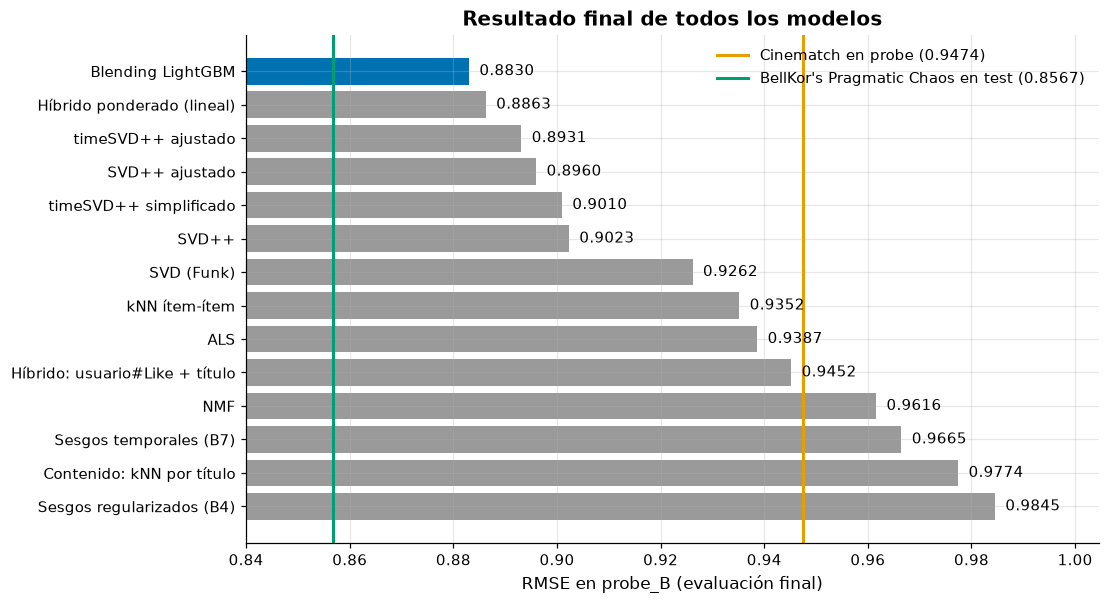

In [ ]:
orden = finales.sort_values("rmse_probe_B", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
colores = [COLOR_PRINCIPAL if v == finales["rmse_probe_B"].min() else COLOR_SECUNDARIO for v in orden["rmse_probe_B"]]
ax.barh(orden["modelo"], orden["rmse_probe_B"], color=colores)
for y, valor in enumerate(orden["rmse_probe_B"]):
    ax.text(valor + 0.002, y, f"{valor:.4f}", va="center")
ax.axvline(RMSE_CINEMATCH_PROBE, color=COLOR_CINEMATCH, linewidth=2, label=f"Cinematch en probe ({RMSE_CINEMATCH_PROBE})")
ax.axvline(RMSE_GANADOR_TEST, color=COLOR_GANADOR, linewidth=2, label=f"BellKor's Pragmatic Chaos en test ({RMSE_GANADOR_TEST})")
ax.set_xlim(0.84, orden["rmse_probe_B"].max() + 0.02)
ax.set_xlabel("RMSE en probe_B (evaluación final)")
ax.set_title("Resultado final de todos los modelos")
ax.legend(loc="upper right")
guardar_figura(fig, "07_rmse_final")
plt.show()

La gráfica ordena los 14 modelos finales por su RMSE en probe_B. La línea naranja es Cinematch en probe (0.9474) y la verde es el ganador en test (0.8567).

- Todos los modelos colaborativos, salvo NMF, superan a Cinematch.
- Los baselines y el contenido quedan a la derecha de Cinematch. Solo con sesgos y títulos no se le gana.
- El blending (0.8830) queda a **0.0263** del ganador. Recordemos que probe y test no son el mismo conjunto, así que la distancia es aproximada. Aun así, sirve como orden de magnitud.

### 1. Error por segmentos

Partimos probe_B según cuántos ratings tienen en train el usuario y la película, y comparamos tres modelos. B7 es el mejor baseline, timeSVD++ ajustado el mejor modelo individual, y el blending el modelo final.

In [ ]:
MEJOR = finales.loc[0, "modelo"]
clave_mejor = [c for c, n in NOMBRES.items() if n == MEJOR][0]
clave_cf = finales[finales["modelo"].isin([NOMBRES[c] for c in NOMBRES if c.startswith("CF_")])].iloc[0]["modelo"]
clave_cf = [c for c, n in NOMBRES.items() if n == clave_cf][0]
comparar = ["B7", clave_cf, clave_mejor]
reales_B = probe_B["ratings"].astype(np.float64)


def rmse_por_tramo(tramo):
    tabla = pd.DataFrame({"tramo": tramo})
    for c in comparar:
        tabla[NOMBRES[c]] = (reales_B - pred_B[c].to_numpy()) ** 2
    agrupado = tabla.groupby("tramo", observed=True)
    resultado = np.sqrt(agrupado.mean())
    resultado.insert(0, "filas", agrupado.size())
    return resultado


tramo_usuario = pd.cut(n_por_usuario[probe_B["usuarios"]], [0, 20, 50, 200, 1_000, 20_000],
                       labels=["1-20", "21-50", "51-200", "201-1000", "> 1000"])
tramo_pelicula = pd.cut(n_por_pelicula[probe_B["peliculas"]], [0, 500, 2_000, 10_000, 50_000, 300_000],
                        labels=["< 500", "500-2k", "2k-10k", "10k-50k", "> 50k"])
segmento_usuario = rmse_por_tramo(tramo_usuario)
segmento_pelicula = rmse_por_tramo(tramo_pelicula)
print("Por número de ratings del usuario en train:")
print(segmento_usuario.round(4))
print("\nPor número de ratings de la película en train:")
print(segmento_pelicula.round(4))

Por número de ratings del usuario en train:
           filas  Sesgos temporales (B7)  timeSVD++ ajustado  \
tramo                                                          
1-20       83840                  1.0416              1.0001   
21-50     146099                  1.0237              0.9511   
51-200    251824                  0.9710              0.8918   
201-1000  202673                  0.8940              0.8121   
> 1000     19762                  0.8505              0.7714   

          Blending LightGBM  
tramo                        
1-20                 0.9852  
21-50                0.9404  
51-200               0.8846  
201-1000             0.8017  
> 1000               0.7531  

Por número de ratings de la película en train:
          filas  Sesgos temporales (B7)  timeSVD++ ajustado  Blending LightGBM
tramo                                                                         
< 500     25137                  1.0339              0.9970             0.9852
500-2k    44

Los números muestran dos patrones.
- **Por usuario el efecto es enorme.** El blending va de 0.9852 para usuarios con 20 ratings o menos a 0.7531 para los que tienen más de 1,000. Una diferencia de 0.23 estrellas.
- **Por película es menor.** El blending va de 0.9852 en películas con menos de 500 ratings a 0.8700 en las de más de 50,000.

Hay un detalle curioso. B7 se equivoca más en las películas muy populares (0.9637) que en las de 10k a 50k ratings (0.9543), pues las películas famosas dividen opiniones y un sesgo único no las describe. Los modelos colaborativos corrigen esto, porque saben a qué tipo de usuario le gusta cada película.

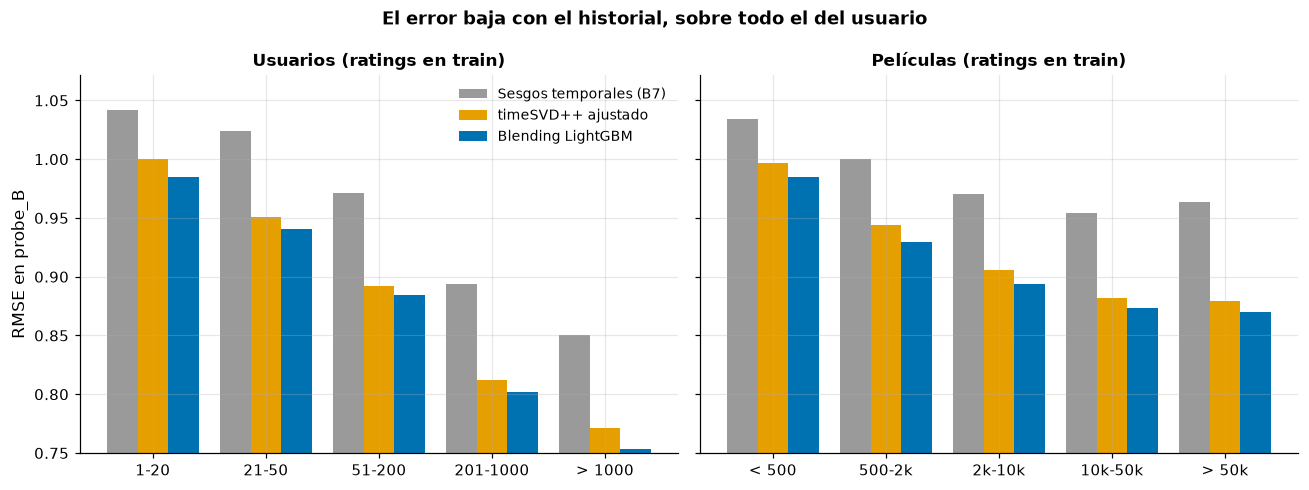

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
colores_modelos = [COLOR_SECUNDARIO, COLOR_CINEMATCH, COLOR_PRINCIPAL]
for ax, tabla, titulo in [(ejes[0], segmento_usuario, "Usuarios (ratings en train)"),
                          (ejes[1], segmento_pelicula, "Películas (ratings en train)")]:
    x = np.arange(len(tabla))
    for desplazamiento, (c, color) in enumerate(zip(comparar, colores_modelos)):
        ax.bar(x + (desplazamiento - 1) * 0.27, tabla[NOMBRES[c]], width=0.27, color=color, label=NOMBRES[c])
    ax.set_xticks(x, tabla.index.astype(str))
    ax.set_title(titulo, fontsize=11)
    ax.set_ylim(0.75, max(segmento_usuario.iloc[:, 1:].max().max(), segmento_pelicula.iloc[:, 1:].max().max()) + 0.03)
ejes[0].set_ylabel("RMSE en probe_B")
ejes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("El error baja con el historial, sobre todo el del usuario", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "07_rmse_por_segmento")
plt.show()

El blending (azul) mejora al timeSVD++ (naranja) en todos los segmentos, entre 0.007 y 0.018 estrellas. Las mejoras más grandes están en los extremos, con 0.015 en usuarios con 20 ratings o menos y 0.018 en usuarios con más de 1,000. En los primeros el blender corrige las predicciones demasiado altas (lo vimos con SHAP en la Etapa 6). En los segundos probablemente aprovecha el kNN, que funciona mejor cuando el usuario calificó muchos vecinos.

La lección para un sistema real es que el problema difícil son los usuarios nuevos. Con pocos ratings ningún modelo baja de 0.98, y ahí es donde más valdría tener información extra (géneros, sinopsis, preguntas al registrarse), que este dataset no trae.

### 2. Métricas de ranking

Un buen RMSE no garantiza buenas listas. Para medir el ranking armamos, para una muestra de usuarios, un top 10 con tres estrategias.
- **Popularidad.** Las películas con más ratings, igual para todos.
- **Sesgo de película (B7).** Las películas con mejor sesgo, también igual para todos.
- **timeSVD++ ajustado.** El puntaje personalizado b_i + q_i · (p_u + |N(u)|^(-1/2) Σ y_j).

Las métricas son las siguientes.
- **Precision@10.** Qué fracción de las 10 recomendadas le gustó (rating ≥ 4 en probe_B).
- **Recall@10.** Qué fracción de las que le gustaron en probe_B aparece en el top 10.
- **Cobertura.** Qué porcentaje del catálogo aparece en al menos una lista.
- **Diversidad.** 1 menos la similitud coseno media entre las películas de una lista, usando los factores del timeSVD++. Más alto significa películas más distintas entre sí.

In [ ]:
with np.load(MODELOS / "timesvdpp_aj.npz") as archivo:
    tsvd = {clave: archivo[clave] for clave in archivo.files}
with np.load(MODELOS / "baseline_B7.npz") as archivo:
    b7_b_i, b7_b_ibin = archivo["b_i"], archivo["b_ibin"].reshape(N_PELICULAS, N_BINS)
implicito = cargar_csr("implicito")

# Puntaje de cada película para un usuario. Los términos que solo dependen del usuario
# (b_u, deriva, sesgo del día) no cambian el orden, así que se omiten.
puntaje_pelicula = (b7_b_i + b7_b_ibin[:, -1] + tsvd["b_i"]).astype(np.float32)
Q = tsvd["Q"]


def factor_efectivo(u):
    a, b = implicito["inicio"][u], implicito["inicio"][u + 1]
    return tsvd["P"][u] + tsvd["Y"][implicito["peliculas"][a:b]].sum(axis=0) / np.sqrt(max(1, b - a))


# Agrupamos probe_B por usuario
orden_B = np.argsort(probe_B["usuarios"], kind="stable")
inicio_B = np.searchsorted(probe_B["usuarios"][orden_B], np.arange(N_USUARIOS + 1))

rng = np.random.default_rng(SEMILLA)
gustos_B = np.bincount(probe_B["usuarios"], weights=probe_B["ratings"] >= 4, minlength=N_USUARIOS)
usuarios_ranking = rng.choice(np.flatnonzero(gustos_B >= 1), 10_000, replace=False)
print(f"Usuarios con al menos un 'le gusta' en probe_B: {(gustos_B >= 1).sum():,}. Muestra: 10,000")

Usuarios con al menos un 'le gusta' en probe_B: 280,320. Muestra: 10,000


Tomamos 10,000 usuarios al azar entre los 280,320 que tienen al menos un "le gusta" en probe_B. Las candidatas son todas las películas que el usuario no calificó en train, probe_A ni qualifying, más las de probe_B, que son las que podemos evaluar.

Hay una advertencia importante. Las películas de probe_B forman parte de N(u), así que el timeSVD++ "sabe" que el usuario las eligió aunque no conozca el rating. Eso le da ventaja frente a las otras estrategias, y en un sistema real esa información no existiría antes de recomendar. Por eso estas métricas sirven para comparar estrategias entre sí, y no como estimación de lo que se lograría en producción.

In [ ]:
def top_10(u, puntajes):
    """Las 10 mejores películas que el usuario no ha visto (o que están en probe_B)."""
    puntajes = puntajes.copy()
    a, b = implicito["inicio"][u], implicito["inicio"][u + 1]
    vistas = implicito["peliculas"][a:b]
    filas_B = orden_B[inicio_B[u]:inicio_B[u + 1]]
    guardar = puntajes[probe_B["peliculas"][filas_B]].copy()
    puntajes[vistas] = -np.inf                      # ya vistas en train, probe_A o qualifying
    puntajes[probe_B["peliculas"][filas_B]] = guardar  # las de probe_B sí son candidatas
    return np.argpartition(-puntajes, 10)[:10]


popularidad = n_por_pelicula.astype(np.float32)
estrategias = {"Popularidad (más vistas)": lambda u: popularidad,
               "Sesgo de película (B7)": lambda u: puntaje_pelicula,
               "timeSVD++ ajustado": lambda u: puntaje_pelicula + Q @ factor_efectivo(u)}

Q_normalizado = Q / np.linalg.norm(Q, axis=1, keepdims=True)
metricas = []
listas = {}
for nombre, puntaje in estrategias.items():
    aciertos, relevantes_total, recomendadas, diversidad = [], [], set(), []
    listas[nombre] = {}
    for u in usuarios_ranking:
        lista = top_10(u, puntaje(u))
        listas[nombre][u] = lista
        filas_B = orden_B[inicio_B[u]:inicio_B[u + 1]]
        relevantes = set(probe_B["peliculas"][filas_B][probe_B["ratings"][filas_B] >= 4])
        aciertos.append(len(relevantes & set(lista)))
        relevantes_total.append(len(relevantes))
        recomendadas.update(lista)
        similitudes = Q_normalizado[lista] @ Q_normalizado[lista].T
        diversidad.append(1 - similitudes[np.triu_indices(10, 1)].mean())
    aciertos, relevantes_total = np.array(aciertos), np.array(relevantes_total)
    metricas.append({"estrategia": nombre,
                     "precision@10": aciertos.mean() / 10,
                     "recall@10": np.mean(aciertos / relevantes_total),
                     "usuarios_con_acierto_%": 100 * np.mean(aciertos > 0),
                     "cobertura_catalogo_%": 100 * len(recomendadas) / N_PELICULAS,
                     "diversidad": np.mean(diversidad)})
metricas = pd.DataFrame(metricas)
metricas.round(4)

,estrategia,precision@10,recall@10,usuarios_con_acierto_%,cobertura_catalogo_%,diversidad
0,Popularidad (más vistas),0.0038,0.0251,3.74,1.3337,0.8895
1,Sesgo de película (B7),0.0008,0.0053,0.82,0.1013,0.8137
2,timeSVD++ ajustado,0.0068,0.0443,6.36,16.0833,0.7556


El timeSVD++ gana en aciertos. Su recall@10 es 0.0443 contra 0.0251 de popularidad, y el 6.36% de los usuarios tiene al menos un acierto contra 3.74%. Los números absolutos son bajos porque cada usuario tiene en promedio muy pocas películas en probe_B y el catálogo tiene 17,770 opciones, así que acertar es como encontrar dos o tres agujas en un pajar.

El sesgo B7 es la peor estrategia (recall 0.0053). Sus películas mejor calificadas son de nicho (series de culto, documentales, ediciones especiales) que pocos usuarios ven.

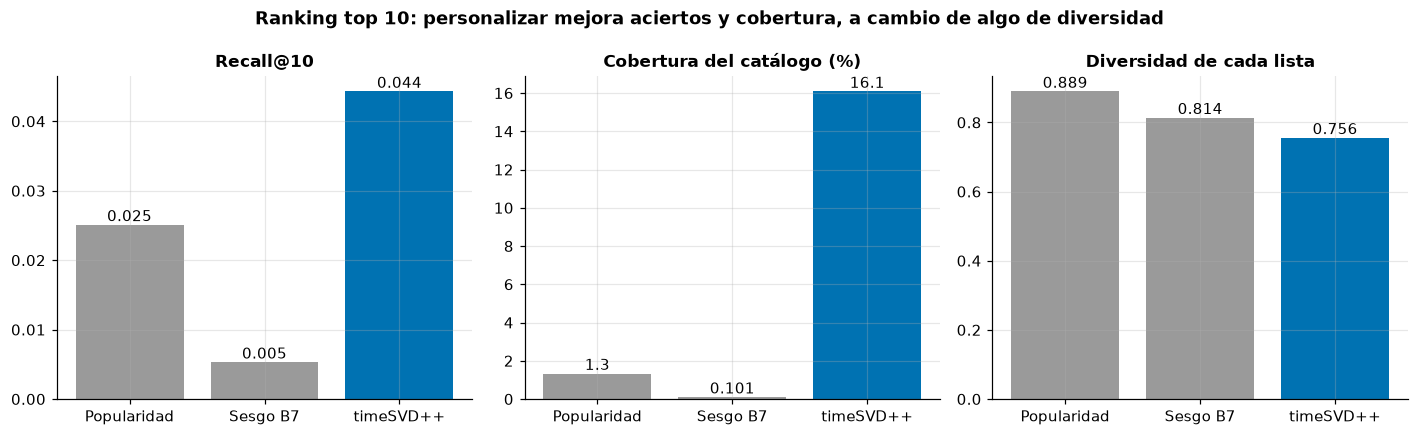

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for ax, columna, titulo in [(ejes[0], "recall@10", "Recall@10"),
                            (ejes[1], "cobertura_catalogo_%", "Cobertura del catálogo (%)"),
                            (ejes[2], "diversidad", "Diversidad de cada lista")]:
    colores = [COLOR_PRINCIPAL if "SVD" in e else COLOR_SECUNDARIO for e in metricas["estrategia"]]
    ax.bar(range(len(metricas)), metricas[columna], color=colores)
    ax.set_xticks(range(len(metricas)), ["Popularidad", "Sesgo B7", "timeSVD++"])
    for x, valor in enumerate(metricas[columna]):
        ax.text(x, valor, f"{valor:.3f}" if valor < 1 else f"{valor:.1f}", ha="center", va="bottom")
    ax.set_title(titulo, fontsize=11)
fig.suptitle("Ranking top 10: personalizar mejora aciertos y cobertura, a cambio de algo de diversidad", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "07_ranking")
plt.show()

- **Recall.** El timeSVD++ casi duplica a la popularidad.
- **Cobertura.** El timeSVD++ recomienda el 16.1% del catálogo, unas 2,860 películas distintas, contra el 1.3% de popularidad y el 0.1% de B7, que dan la misma lista a todos.
- **Diversidad.** Aquí el timeSVD++ pierde (0.756 contra 0.889 de popularidad). Personalizar significa recomendar películas parecidas a las que le gustan al usuario, y por eso se parecen entre sí. Es el costo conocido de los sistemas personalizados, la "burbuja" de recomendación.

### 3. Ejemplos de recomendaciones explicadas

In [ ]:
with np.load(MODELOS / "vecinos_cf.npz") as archivo:
    vecinos_cf, similitud_cf = archivo["vecinos"], archivo["similitud"]
with np.load(MODELOS / "vecinos_titulo.npz") as archivo:
    vecinos_titulo, similitud_titulo = archivo["vecinos"][:, :10], archivo["similitud"][:, :10]


def explicar(u, n_gustadas=5):
    a, b = csr_usuario["inicio"][u], csr_usuario["inicio"][u + 1]
    vistas = dict(zip(csr_usuario["peliculas"][a:b], csr_usuario["ratings"][a:b]))
    favoritas = sorted(vistas, key=lambda j: (-vistas[j], -n_por_pelicula[j]))[:n_gustadas]
    print(f"Usuario {u}: {len(vistas):,} ratings en train. Algunas que calificó con 5:")
    for j in favoritas:
        print(f"   {vistas[j]}  {peliculas.loc[j, 'titulo']}")

    efectivo = factor_efectivo(u)
    lista = listas["timeSVD++ ajustado"][u]
    lista = lista[np.argsort(-(puntaje_pelicula[lista] + Q[lista] @ efectivo))]
    filas = []
    for i in lista:
        razon_cf, razon_titulo = "", ""
        candidatos = [(s, j) for j, s in zip(vecinos_cf[i], similitud_cf[i]) if j in vistas and vistas[j] >= 4]
        if candidatos:
            s, j = max(candidatos)
            razon_cf = f"{peliculas.loc[j, 'titulo'][:35]} ({vistas[j]}★, sim {s:.2f})"
        candidatos = [(s, j) for j, s in zip(vecinos_titulo[i], similitud_titulo[i]) if j in vistas and vistas[j] >= 4]
        if candidatos:
            s, j = max(candidatos)
            razon_titulo = f"{peliculas.loc[j, 'titulo'][:35]} ({vistas[j]}★)"
        filas.append({"recomendada": peliculas.loc[i, "titulo"][:40],
                      "calidad_general": round(float(puntaje_pelicula[i]), 2),
                      "afinidad_personal": round(float(Q[i] @ efectivo), 2),
                      "vecina_que_le_gusto": razon_cf, "titulo_parecido": razon_titulo})
    return pd.DataFrame(filas)


# Tres perfiles: poco, medio y muy activo
activos = n_por_usuario[usuarios_ranking]
ejemplos = [usuarios_ranking[np.argmin(np.abs(activos - objetivo))] for objetivo in (30, 300, 2000)]

La función `explicar` muestra, para un usuario, algunas películas que calificó con 5 y su top 10 del timeSVD++. Para cada recomendación da cuatro pistas.
- **calidad_general.** El sesgo de la película (b_i de B7 en el último periodo más el b_i del timeSVD++). Es positivo si la película gusta en general.
- **afinidad_personal.** El producto q_i · p_u efectivo, o sea cuánto encaja la película con los gustos del usuario según los factores.
- **vecina_que_le_gusto.** La película más parecida (kNN de la Etapa 5) que el usuario calificó con 4 o 5.
- **titulo_parecido.** Lo mismo con la similitud de títulos de la Etapa 4.

Elegimos tres usuarios de la muestra con unos 30, 300 y 2,000 ratings en train.

In [ ]:
explicar(ejemplos[0])

Usuario 275549: 30 ratings en train. Algunas que calificó con 5:
   5  Pulp Fiction
   5  Jackie Brown: Collector's Series
   5  Kalifornia
   5  Big Top Pee-Wee
   5  The Andy Griffith Show: Vol 2: The Big House / A Wife for Andy


,recomendada,calidad_general,afinidad_personal,vecina_que_le_gusto,titulo_parecido
0,Seinfeld: Season 4,0.78,0.55,"The Sopranos: Season 4 (4★, sim 0.04)",
1,A Christmas Story,0.60,0.65,,
2,Seinfeld: Seasons 1 & 2,0.71,0.45,"The Sopranos: Season 4 (4★, sim 0.04)",
3,Seinfeld: Season 3,0.72,0.44,"The Sopranos: Season 4 (4★, sim 0.04)",
4,The Wizard of Oz: Collector's Edition,0.70,0.45,"Citizen Kane (4★, sim 0.05)",
5,The Andy Griffith Show: Season 1,0.20,0.94,"The Andy Griffith Show: Vol 1: High (5★, sim 0...",The Best of the Andy Griffith Show (5★)
6,Dr. Seuss' How the Grinch Stole Christma,0.54,0.54,,
7,The Andy Griffith Show: Vol 4: The Mount,-0.07,1.11,"The Andy Griffith Show: Vol 2: The (5★, sim 0...",The Andy Griffith Show: Vol 2: The (5★)
8,The Andy Griffith Show: Vol 5: Rafe Holl,-0.02,1.05,"The Andy Griffith Show: Vol 2: The (5★, sim 0...",The Andy Griffith Show: Vol 2: The (5★)
9,King of the Hill: Season 4,0.29,0.74,,


**Usuario con 30 ratings.** Le gustan Pulp Fiction y Jackie Brown, pero también comedias clásicas de televisión como The Andy Griffith Show y Big Top Pee-Wee. El top 10 refleja la segunda parte. Hay tres temporadas de Seinfeld, tres volúmenes de Andy Griffith, King of the Hill y clásicos navideños (A Christmas Story, El Grinch).

Las explicaciones se reparten. Los volúmenes de Andy Griffith tienen calidad general casi nula (-0.07 y -0.02) pero la afinidad personal más alta (1.11 y 1.05), y las respaldan tanto el kNN como el título, ya que el usuario calificó con 5 otro volumen de la serie. Seinfeld y A Christmas Story vienen sobre todo de la calidad general (0.60 a 0.78) más una afinidad moderada. Con solo 30 ratings el modelo combina "lo que gusta a todos" con la señal de comedia televisiva.

In [ ]:
explicar(ejemplos[1])

Usuario 109641: 300 ratings en train. Algunas que calificó con 5:
   5  The Day After Tomorrow
   5  How to Lose a Guy in 10 Days
   5  I, Robot
   5  Double Jeopardy
   5  Mystic River


,recomendada,calidad_general,afinidad_personal,vecina_que_le_gusto,titulo_parecido
0,Nip/Tuck: Season 2,0.50,0.93,,
1,Lost: Season 1,0.94,0.46,"Sin City (4★, sim 0.02)",
2,Desperate Housewives: Season 1,0.51,0.75,,
3,Carlos Mencia: Not for the Easily Offend,0.33,0.91,"Saw (5★, sim 0.01)",
4,Nip/Tuck: Season 1,0.52,0.72,,
5,The Sixth Sense,0.48,0.76,"Forrest Gump (4★, sim 0.10)",
6,Dead Like Me: Season 2,0.88,0.33,,
7,Charmed: Season 2,0.12,1.08,,
8,Gilmore Girls: Season 3,0.60,0.61,,
9,Smallville: Season 4,0.50,0.70,,


**Usuario con 300 ratings.** Sus favoritas son películas comerciales de la época (The Day After Tomorrow, I, Robot, How to Lose a Guy in 10 Days). El top 10 es casi todo series de televisión de 2004 y 2005 (Nip/Tuck, Lost, Desperate Housewives, Gilmore Girls, Smallville, Charmed).

Aquí el kNN casi no explica nada. Solo 3 de las 10 tienen una vecina que le gustó, y con similitudes muy bajas (0.01 a 0.10). Las recomendaciones salen de los factores latentes. Por ejemplo, Charmed tiene una calidad general baja (0.12) pero la afinidad más alta (1.08). El modelo detectó que este usuario se parece a quienes ven series de drama de la televisión abierta, algo que ningún vecino individual muestra. Esta es la ventaja de la factorización y también su costo, pues la explicación es menos concreta que "porque te gustó X".

In [ ]:
explicar(ejemplos[2])

Usuario 289280: 1,997 ratings en train. Algunas que calificó con 5:
   5  The Green Mile
   5  Ocean's Eleven
   5  Lord of the Rings: The Two Towers
   5  Gladiator
   5  Indiana Jones and the Last Crusade


,recomendada,calidad_general,afinidad_personal,vecina_que_le_gusto,titulo_parecido
0,Battlestar Galactica: Season 1,0.89,0.60,"Battlestar Galactica: The Miniserie (4★, sim 0...",Battlestar Galactica: The Miniserie (4★)
1,GoodFellas: Special Edition: Bonus Mater,0.45,1.02,"The Godfather Trilogy: Bonus Materi (5★, sim 0...",GoodFellas: Special Edition (5★)
2,The Girl on the Bridge,0.41,0.98,"The Virgin Suicides (5★, sim 0.01)",The Bridge on the River Kwai (4★)
3,The Daily Show with Jon Stewart: Indecis,0.52,0.81,"The Simpsons: Season 6 (4★, sim 0.05)",
4,Pulp Fiction: Bonus Material,-0.15,1.46,"Pulp Fiction (4★, sim 0.04)",Pulp Fiction (4★)
5,Reservoir Dogs: Bonus Material,0.05,1.26,"Reservoir Dogs (4★, sim 0.04)",Reservoir Dogs (4★)
6,From the Earth to the Moon: The Signatur,0.65,0.65,"The Right Stuff (4★, sim 0.08)",
7,The Big Red One: Special Edition,-0.16,1.45,"A Bridge Too Far (4★, sim 0.06)",Heat: Special Edition (5★)
8,Seven: Bonus Material,0.07,1.19,"The Godfather Trilogy: Bonus Materi (5★, sim 0...",
9,Family Guy: Vol. 2: Season 3,0.59,0.66,"The Simpsons: Season 4 (5★, sim 0.13)",The Family Man (4★)


**Usuario con 1,997 ratings.** Es un cinéfilo de cine clásico y de autor (The Green Mile, Gladiator, El Señor de los Anillos, Indiana Jones). Su top 10 muestra un rasgo peculiar del catálogo de Netflix, los **discos de material extra**. Aparecen los extras de Pulp Fiction, Reservoir Dogs, GoodFellas y Seven.

Estos discos tienen calidad general baja o negativa (-0.15 para los extras de Pulp Fiction), pues al público general no le interesan. Pero su afinidad personal es la más alta de la lista (1.46 y 1.26), y el título y el kNN coinciden en la razón, ya que el usuario calificó la película original con 4. El modelo aprendió que quien califica muchas películas de culto también califica sus extras. Es una recomendación correcta según los datos, pero discutible para un usuario, y muestra que optimizar el RMSE no siempre da la lista más útil.

En los tres ejemplos las tres fuentes de explicación se complementan. El kNN y el título dan razones concretas cuando existen, y los factores cubren el resto.

### Conclusiones del proyecto

**Resultado final.** El mejor sistema es un blending con LightGBM sobre 13 modelos y 6 metavariables, con **RMSE de 0.8830 en probe_B**. Mejora 6.8% a Cinematch en probe (0.9474) y queda a 0.0263 del 0.8567 de BellKor's Pragmatic Chaos. Probe y test no son el mismo conjunto, así que esa distancia es aproximada. Todos los modelos se entrenaron con el dataset completo (99,072,112 ratings de train), sin muestreo, y el RMSE de probe_A y probe_B coincide a la cuarta cifra decimal, por lo que el resultado no depende de haber ajustado sobre probe_A.

**Qué funcionó, en orden de impacto.**
1. **Factorización con información implícita.** Pasar de los sesgos (B7, 0.9665) a SVD++ ajustado (0.8960) fue el salto más grande. Saber qué películas eligió cada usuario en probe y qualifying, sin conocer el rating, bajó el RMSE en 0.024 frente al SVD simple.
2. **Ajustar la regularización.** Bajarla de 0.02 a 0.01 y subir a 100 factores mejoró en 0.008 al mejor modelo. La sensibilidad de la Etapa 5 lo anticipó, aunque con 8 épocas sugería un valor (0.005) que sobreajusta con más entrenamiento.
3. **Blending.** Combinar modelos mejoró en 0.0101 al mejor individual en probe_B. La regresión lineal da dos tercios de esa mejora y LightGBM el resto, con metavariables como el historial del usuario.
4. **Efectos temporales.** El cambio de nivel de 2004 y la deriva de los usuarios valen 0.018 entre B4 y B7 en probe_B, y otros 0.0034 dentro del timeSVD++.

**Qué no funcionó.**
- **El contenido.** Con solo título y año, el mejor modelo de contenido (0.9774) apenas mejora a B4 y la conmutación nunca le gana al colaborativo, ni siquiera con usuarios de menos de 20 ratings. El título sí detecta sagas y temporadas, y por eso el blender le da algo de peso.
- **NMF y ALS.** La no negatividad le quita flexibilidad a NMF (0.9616), y ALS (0.9387) fue 9 veces más lento que SGD para un resultado peor.
- **La combinación usuario#Like + título.** Binarizar los ratings pierde información (0.9452 contra 0.9352 del kNN sobre residuos), y el título no le agrega nada.

**Por qué no alcanzamos al ganador.** BellKor's Pragmatic Chaos combinó más de 100 modelos, cada uno muy afinado, incluyendo el timeSVD++ completo con factores de usuario que cambian por día, kNN con pesos aprendidos de forma global, RBM y decenas de variantes con distintos hiperparámetros, todo durante casi tres años. Nuestro sistema usa 13 modelos y una versión simplificada de timeSVD++ sin factores dependientes del tiempo. Los siguientes pasos naturales serían esos factores temporales p_u(t), un kNN con interpolación aprendida y más variantes de factorización para el blender.

**Más allá del RMSE.** Las métricas de ranking muestran que el modelo personalizado casi duplica el recall@10 de la popularidad y cubre el 16% del catálogo, a cambio de listas menos diversas. Los ejemplos muestran que los factores latentes encuentran gustos que ningún vecino individual explica, pero también que optimizar el RMSE puede llevar a recomendar discos de material extra. El problema más difícil sigue siendo el usuario nuevo, para quien ningún modelo baja de 0.98 de RMSE.